In [ ]:

from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:

from pathlib import Path

BASE = Path("/content/drive/MyDrive/GuardianEye_Data")
ARCHIVES = BASE / "archives"

print("Archives folder exists:", ARCHIVES.exists())

if ARCHIVES.exists():
    for f in sorted(ARCHIVES.iterdir()):
        if f.is_file():
            print(f"{f.name}: {f.stat().st_size / (1024**3):.2f} GB")
        else:
            print(f"{f.name}/ (folder)")


Archives folder exists: True
conservation_drones_train_real.zip: 2.12 GB
eccv_18_all_images_sm.tar.gz: 6.05 GB
eccv_18_annotations.tar.gz: 0.00 GB


In [ ]:

import shutil

usage = shutil.disk_usage("/content")
print(f"Total disk: {usage.total / 1e9:.1f} GB")
print(f"Free disk:  {usage.free / 1e9:.1f} GB")


Total disk: 115.7 GB
Free disk:  93.6 GB


In [ ]:

from pathlib import Path
import zipfile
import tarfile

BASE = Path("/content/drive/MyDrive/GuardianEye_Data/archives")

archives = [
    BASE / "conservation_drones_train_real.zip",
    BASE / "eccv_18_all_images_sm.tar.gz",
    BASE / "eccv_18_annotations.tar.gz",
]

for path in archives:
    print(f"\n{'=' * 65}")
    print(f"Archive: {path.name}")

    if not path.exists():
        print("NOT FOUND — check the filename.")
        continue

    try:
        if path.suffix == ".zip":
            with zipfile.ZipFile(path) as z:
                members = z.infolist()
                print("Files:", len(members))
                for item in members[:12]:
                    print(" ", item.filename)
        else:
            with tarfile.open(path, "r:gz") as t:
                members = t.getmembers()
                print("Entries:", len(members))
                for item in members[:12]:
                    print(" ", item.name)

    except Exception as e:
        print("Could not inspect archive:", repr(e))



Archive: conservation_drones_train_real.zip
Files: 42685
  TrainReal/
  TrainReal/annotations/
  TrainReal/annotations/0000000062_0000000000.csv
  TrainReal/annotations/0000000067_0000000026.csv
  TrainReal/annotations/0000000067_0000000059.csv
  TrainReal/annotations/0000000067_0000000012.csv
  TrainReal/annotations/0000000067_0000000028.csv
  TrainReal/annotations/0000000067_0000000058.csv
  TrainReal/annotations/water_metadata_train.txt
  TrainReal/annotations/0000000067_0000000019.csv
  TrainReal/annotations/0000000354_0000000000.csv
  TrainReal/annotations/0000000067_0000000040.csv

Archive: eccv_18_all_images_sm.tar.gz
Entries: 57865
  eccv_18_all_images_sm
  eccv_18_all_images_sm/588c1355-23d2-11e8-a6a3-ec086b02610b.jpg
  eccv_18_all_images_sm/58e72595-23d2-11e8-a6a3-ec086b02610b.jpg
  eccv_18_all_images_sm/59f79bfc-23d2-11e8-a6a3-ec086b02610b.jpg
  eccv_18_all_images_sm/5a0b0022-23d2-11e8-a6a3-ec086b02610b.jpg
  eccv_18_all_images_sm/58d2ed70-23d2-11e8-a6a3-ec086b02610b.jpg
  

In [ ]:

from pathlib import Path
import zipfile
import tarfile
import shutil

ARCHIVES = Path("/content/drive/MyDrive/GuardianEye_Data/archives")
WORK = Path("/content/guardian_eye_data")

WORK.mkdir(parents=True, exist_ok=True)

# Check free space before extraction
free_gb = shutil.disk_usage("/content").free / (1024**3)
print(f"Free Colab disk space: {free_gb:.1f} GB")

if free_gb < 25:
    raise RuntimeError("Not enough free space for this extraction plan.")

# Extract BIRDSAI real training data
birds_zip = ARCHIVES / "conservation_drones_train_real.zip"
birds_out = WORK / "birdsai"

if not birds_out.exists():
    birds_out.mkdir(parents=True)
    with zipfile.ZipFile(birds_zip) as z:
        z.extractall(birds_out)
    print("BIRDSAI extraction complete.")
else:
    print("BIRDSAI destination already exists; skipping.")

# Extract CCT20 images
cct_tar = ARCHIVES / "eccv_18_all_images_sm.tar.gz"
cct_out = WORK / "cct20"

if not cct_out.exists():
    cct_out.mkdir(parents=True)
    with tarfile.open(cct_tar, "r:gz") as t:
        t.extractall(cct_out, filter="data")
    print("CCT20 image extraction complete.")
else:
    print("CCT20 destination already exists; skipping.")

# Extract CCT20 annotations
ann_tar = ARCHIVES / "eccv_18_annotations.tar.gz"
ann_out = WORK / "cct20_annotations"

if not ann_out.exists():
    ann_out.mkdir(parents=True)
    with tarfile.open(ann_tar, "r:gz") as t:
        t.extractall(ann_out, filter="data")
    print("CCT20 annotation extraction complete.")
else:
    print("CCT20 annotations already extracted; skipping.")

print("\nExtraction destinations:")
print("BIRDSAI:", birds_out)
print("CCT20 images:", cct_out)
print("CCT20 annotations:", ann_out)
print(f"Free disk remaining: {shutil.disk_usage('/content').free / (1024**3):.1f} GB")


Free Colab disk space: 81.1 GB
BIRDSAI extraction complete.
CCT20 image extraction complete.
CCT20 annotation extraction complete.

Extraction destinations:
BIRDSAI: /content/guardian_eye_data/birdsai
CCT20 images: /content/guardian_eye_data/cct20
CCT20 annotations: /content/guardian_eye_data/cct20_annotations
Free disk remaining: 70.6 GB


In [ ]:

from pathlib import Path

WORK = Path("/content/guardian_eye_data")

for dataset in ["birdsai", "cct20", "cct20_annotations"]:
    root = WORK / dataset
    files = [p for p in root.rglob("*") if p.is_file()]
    print(f"\n{dataset}: {len(files):,} files")

    for p in files[:8]:
        print(" ", p.relative_to(root))

# Inspect the five CCT20 annotation JSON files
ann_root = WORK / "cct20_annotations" / "eccv_18_annotation_files"

if ann_root.exists():
    print("\nCCT20 annotation files:")
    for p in sorted(ann_root.glob("*.json")):
        print(f"  {p.name}: {p.stat().st_size / (1024**2):.2f} MB")



birdsai: 41,996 files
  TrainReal/annotations/0000000067_0000000058.csv
  TrainReal/annotations/0000000067_0000000046.csv
  TrainReal/annotations/0000000067_0000000005.csv
  TrainReal/annotations/0000000067_0000000026.csv
  TrainReal/annotations/0000000054_0000000000.csv
  TrainReal/annotations/0000000067_0000000019.csv
  TrainReal/annotations/0000000067_0000000027.csv
  TrainReal/annotations/0000000067_0000000045.csv

cct20: 57,864 files
  eccv_18_all_images_sm/58ac0e1e-23d2-11e8-a6a3-ec086b02610b.jpg
  eccv_18_all_images_sm/59b13037-23d2-11e8-a6a3-ec086b02610b.jpg
  eccv_18_all_images_sm/59aadb3f-23d2-11e8-a6a3-ec086b02610b.jpg
  eccv_18_all_images_sm/59bfe005-23d2-11e8-a6a3-ec086b02610b.jpg
  eccv_18_all_images_sm/596a4d24-23d2-11e8-a6a3-ec086b02610b.jpg
  eccv_18_all_images_sm/59adfd87-23d2-11e8-a6a3-ec086b02610b.jpg
  eccv_18_all_images_sm/59d751bb-23d2-11e8-a6a3-ec086b02610b.jpg
  eccv_18_all_images_sm/58782b63-23d2-11e8-a6a3-ec086b02610b.jpg

cct20_annotations: 5 files
  eccv_1

In [ ]:

from pathlib import Path
import json
import csv
from collections import Counter

WORK = Path("/content/guardian_eye_data")

# --------------------------------------------------
# A. Inspect CCT20 annotation JSON files
# --------------------------------------------------
ann_dir = WORK / "cct20_annotations" / "eccv_18_annotation_files"

print("=" * 70)
print("CCT20 ANNOTATION INSPECTION")

for path in sorted(ann_dir.glob("*.json")):
    print(f"\n--- {path.name} ---")

    with path.open("r", encoding="utf-8") as f:
        data = json.load(f)

    print("Top-level type:", type(data).__name__)

    if isinstance(data, dict):
        print("Top-level keys:", list(data.keys()))

        for key in ["images", "annotations", "categories"]:
            if key in data:
                value = data[key]
                print(f"{key}: {len(value) if isinstance(value, list) else type(value).__name__}")
                if isinstance(value, list) and value:
                    print(f"  First {key[:-1]}:", value[0])

        # Some schemas store split metadata under other keys.
        for key in data:
            if key not in {"images", "annotations", "categories"}:
                value = data[key]
                if isinstance(value, (str, int, float, bool)):
                    print(f"{key}: {value}")

    elif isinstance(data, list) and data:
        print("First record:", data[0])


# --------------------------------------------------
# B. Inspect BIRDSAI MOT annotation CSVs
# --------------------------------------------------
birds_ann = WORK / "birdsai" / "TrainReal" / "annotations"
csv_files = sorted(birds_ann.glob("*.csv"))

print("\n" + "=" * 70)
print("BIRDSAI ANNOTATION INSPECTION")
print("CSV annotation files:", len(csv_files))

for path in csv_files[:3]:
    print(f"\n--- {path.name} ---")
    with path.open("r", newline="", encoding="utf-8-sig") as f:
        rows = list(csv.reader(f))

    print("Rows:", len(rows))
    for row in rows[:4]:
        print(row)

# Count class IDs from annotation rows.
class_counts = Counter()
valid_rows = 0
malformed_rows = 0

for path in csv_files:
    with path.open("r", newline="", encoding="utf-8-sig") as f:
        for row in csv.reader(f):
            if not row:
                continue
            try:
                # MOT format: frame, object_id, x, y, w, h, class, ...
                if len(row) >= 7:
                    class_counts[row[6].strip()] += 1
                    valid_rows += 1
                else:
                    malformed_rows += 1
            except Exception:
                malformed_rows += 1

print("\nBIRDSAI annotation rows:", valid_rows)
print("Rows by class ID:", dict(class_counts))
print("Rows with fewer than 7 columns:", malformed_rows)

# --------------------------------------------------
# C. Check whether expected image directories exist
# --------------------------------------------------
print("\n" + "=" * 70)
print("IMAGE DIRECTORY CHECK")

for rel in [
    "birdsai/TrainReal/images",
    "cct20/eccv_18_all_images_sm",
]:
    p = WORK / rel
    print(f"{rel}: exists={p.exists()}")

    if p.exists():
        image_count = sum(
            1 for x in p.rglob("*")
            if x.is_file() and x.suffix.lower() in
            {".jpg", ".jpeg", ".png", ".tif", ".tiff"}
        )
        print("  Image files:", image_count)



CCT20 ANNOTATION INSPECTION

--- cis_test_annotations.json ---
Top-level type: dict
Top-level keys: ['info', 'categories', 'images', 'annotations']
images: 15827
  First image: {'file_name': '59b93afb-23d2-11e8-a6a3-ec086b02610b.jpg', 'rights_holder': 'Justin Brown', 'height': 1494, 'width': 2048, 'frame_num': 2, 'date_captured': '2012-05-09 07:33:45', 'location': 38, 'seq_num_frames': 3, 'seq_id': '6f04895c-5567-11e8-a3d6-dca9047ef277', 'id': '59b93afb-23d2-11e8-a6a3-ec086b02610b'}
annotations: 16395
  First annotation: {'image_id': '5a263af8-23d2-11e8-a6a3-ec086b02610b', 'category_id': 30, 'id': '343db02b-7d5b-11e7-884d-7845c41c2c67'}
categories: 16
  First categorie: {'id': 6, 'name': 'bobcat'}

--- cis_val_annotations.json ---
Top-level type: dict
Top-level keys: ['info', 'categories', 'images', 'annotations']
images: 3484
  First image: {'file_name': '5a1e5306-23d2-11e8-a6a3-ec086b02610b.jpg', 'rights_holder': 'Justin Brown', 'height': 1494, 'width': 2048, 'frame_num': 2, 'date_ca

In [ ]:

from pathlib import Path

base = Path("/content/guardian_eye_data")
drive = Path("/content/drive/MyDrive/GuardianEye_Data")

for root in [base, drive]:
    print(f"\nSearching under: {root}")
    if not root.exists():
        print("  Directory does not exist")
        continue

    matches = list(root.rglob("*_annotations.json"))
    for p in matches[:20]:
        print(" ", p)

    print("JSON annotation files found:", len(matches))



Searching under: /content/guardian_eye_data
  /content/guardian_eye_data/cct20_annotations/eccv_18_annotation_files/cis_val_annotations.json
  /content/guardian_eye_data/cct20_annotations/eccv_18_annotation_files/train_annotations.json
  /content/guardian_eye_data/cct20_annotations/eccv_18_annotation_files/trans_test_annotations.json
  /content/guardian_eye_data/cct20_annotations/eccv_18_annotation_files/trans_val_annotations.json
  /content/guardian_eye_data/cct20_annotations/eccv_18_annotation_files/cis_test_annotations.json
JSON annotation files found: 5

Searching under: /content/drive/MyDrive/GuardianEye_Data
JSON annotation files found: 0


In [ ]:

from pathlib import Path

p = Path("/content/drive/MyDrive/GuardianEye_Data/archives")
print("Archive directory exists:", p.exists())

if p.exists():
    for f in p.iterdir():
        if "annotation" in f.name.lower() or "cct20" in f.name.lower():
            print(f.name, f.stat().st_size, "bytes")


Archive directory exists: True
eccv_18_annotations.tar.gz 2997071 bytes


In [ ]:

from pathlib import Path
import tarfile

archive = Path(
    "/content/drive/MyDrive/GuardianEye_Data/archives/"
    "eccv_18_annotations.tar.gz"
)

destination = Path("/content/guardian_eye_data/cct20_annotations")
destination.mkdir(parents=True, exist_ok=True)

with tarfile.open(archive, "r:gz") as tar:
    members = [
        m for m in tar.getmembers()
        if m.isfile() and m.name.lower().endswith(".json")
    ]

    print("JSON files in archive:")
    for m in members:
        print(f"  {m.name} ({m.size:,} bytes)")

    for m in members:
        # Extract only JSON files, using their basename to avoid
        # unexpected nested paths or overwriting unrelated files.
        source = tar.extractfile(m)
        if source is None:
            continue

        target = destination / Path(m.name).name
        target.write_bytes(source.read())
        print("Extracted:", target)

print("\nFiles now in destination:")
for p in sorted(destination.glob("*.json")):
    print(p.name, f"({p.stat().st_size:,} bytes)")

assert len(list(destination.glob("*.json"))) == 5, (
    "Expected five annotation JSON files."
)

print("\nSUCCESS: all five annotation files are available.")


JSON files in archive:
  eccv_18_annotation_files/cis_test_annotations.json (7,291,146 bytes)
  eccv_18_annotation_files/trans_test_annotations.json (10,691,512 bytes)
  eccv_18_annotation_files/trans_val_annotations.json (846,937 bytes)
  eccv_18_annotation_files/train_annotations.json (6,292,495 bytes)
  eccv_18_annotation_files/cis_val_annotations.json (1,578,866 bytes)
Extracted: /content/guardian_eye_data/cct20_annotations/cis_test_annotations.json
Extracted: /content/guardian_eye_data/cct20_annotations/trans_test_annotations.json
Extracted: /content/guardian_eye_data/cct20_annotations/trans_val_annotations.json
Extracted: /content/guardian_eye_data/cct20_annotations/train_annotations.json
Extracted: /content/guardian_eye_data/cct20_annotations/cis_val_annotations.json

Files now in destination:
cis_test_annotations.json (7,291,146 bytes)
cis_val_annotations.json (1,578,866 bytes)
train_annotations.json (6,292,495 bytes)
trans_test_annotations.json (10,691,512 bytes)
trans_val_ann

In [ ]:

# Rebuild the CCT20 manifest and validate its contents

from pathlib import Path
import json
import pandas as pd

ROOT = Path("/content/guardian_eye_data")
DRIVE = Path("/content/drive/MyDrive/GuardianEye_Data")
OUT = DRIVE / "manifests"
OUT.mkdir(parents=True, exist_ok=True)

ann_dir = ROOT / "cct20_annotations"
image_dir = ROOT / "cct20" / "eccv_18_all_images_sm"

cct_rows = []
cct_summary = []

for json_path in sorted(ann_dir.glob("*.json")):
    with json_path.open() as f:
        data = json.load(f)

    split = json_path.stem.replace("_annotations", "")
    images = data.get("images", [])
    annotations = data.get("annotations", [])
    categories = data.get("categories", [])

    image_ids = {str(im["id"]) for im in images}
    category_names = {
        str(cat["id"]): cat["name"] for cat in categories
    }

    missing_bbox = sum("bbox" not in ann for ann in annotations)
    unmatched_ids = sum(
        str(ann.get("image_id")) not in image_ids
        for ann in annotations
    )
    missing_files = sum(
        not (image_dir / im["file_name"]).is_file()
        for im in images
    )

    cct_summary.append({
        "split": split,
        "images": len(images),
        "annotations": len(annotations),
        "categories": len(categories),
        "annotations_without_bbox": missing_bbox,
        "annotations_with_unknown_image": unmatched_ids,
        "image_files_missing_on_disk": missing_files,
        "category_counts": {
            category_names.get(str(cat_id), "UNKNOWN"): count
            for cat_id, count in __import__("collections").Counter(
                str(ann.get("category_id", "UNKNOWN"))
                for ann in annotations
            ).items()
        },
    })

    for im in images:
        cct_rows.append({
            "dataset": "CCT20",
            "split": split,
            "image_id": str(im["id"]),
            "image_path": str(image_dir / im["file_name"]),
            "file_name": im["file_name"],
            "width": im.get("width"),
            "height": im.get("height"),
            "seq_id": im.get("seq_id"),
            "location": im.get("location"),
            "date_captured": im.get("date_captured"),
        })

# Explicit columns prevent the original KeyError if no rows are found.
columns = [
    "dataset", "split", "image_id", "image_path", "file_name",
    "width", "height", "seq_id", "location", "date_captured"
]
cct_df = pd.DataFrame(cct_rows, columns=columns)

if cct_df.empty:
    raise RuntimeError(
        f"No CCT20 images loaded. JSON files found: "
        f"{len(list(ann_dir.glob('*.json')))}. "
        f"Check annotation directory: {ann_dir}"
    )

duplicate_rows = int(
    cct_df["image_id"].duplicated(keep=False).sum()
)

cct_df.to_csv(OUT / "cct20_manifest.csv", index=False)

quality_report = {
    "splits": cct_summary,
    "manifest_rows": len(cct_df),
    "duplicate_image_id_rows_across_splits": duplicate_rows,
}

(OUT / "cct20_quality_report.json").write_text(
    json.dumps(quality_report, indent=2)
)

print("Manifest rows:", len(cct_df))
print("Split counts:")
print(cct_df.groupby("split").size().to_string())
print("\nDuplicate image-ID rows across splits:", duplicate_rows)
print("\nQuality report:")
for item in cct_summary:
    print(item)

print("\nSaved to:", OUT / "cct20_manifest.csv")


Manifest rows: 57864
Split counts:
split
cis_test      15827
cis_val        3484
train         13553
trans_test    23275
trans_val      1725

Duplicate image-ID rows across splits: 0

Quality report:
{'split': 'cis_test', 'images': 15827, 'annotations': 16395, 'categories': 16, 'annotations_without_bbox': 3131, 'annotations_with_unknown_image': 0, 'image_files_missing_on_disk': 0, 'category_counts': {'empty': 1180, 'opossum': 4535, 'cat': 1672, 'rabbit': 1807, 'dog': 895, 'squirrel': 666, 'raccoon': 1103, 'coyote': 1372, 'bobcat': 909, 'skunk': 194, 'rodent': 236, 'bird': 865, 'badger': 4, 'car': 791, 'fox': 2, 'deer': 164}}
{'split': 'cis_val', 'images': 3484, 'annotations': 3582, 'categories': 16, 'annotations_without_bbox': 1819, 'annotations_with_unknown_image': 0, 'image_files_missing_on_disk': 0, 'category_counts': {'rabbit': 518, 'empty': 995, 'cat': 192, 'dog': 148, 'squirrel': 224, 'opossum': 496, 'raccoon': 174, 'bird': 144, 'coyote': 306, 'rodent': 143, 'bobcat': 154, 'skunk

In [ ]:

from pathlib import Path
import json
from collections import Counter, defaultdict

ann_dir = Path("/content/guardian_eye_data/cct20_annotations")

for path in sorted(ann_dir.glob("*.json")):
    data = json.loads(path.read_text())
    categories = {
        str(c["id"]): c["name"]
        for c in data.get("categories", [])
    }

    with_bbox = Counter()
    without_bbox = Counter()
    examples_with = defaultdict(list)
    examples_without = defaultdict(list)

    for ann in data.get("annotations", []):
        cat_id = str(ann.get("category_id", "UNKNOWN"))
        name = categories.get(cat_id, "UNKNOWN")

        if "bbox" in ann and ann["bbox"] is not None:
            with_bbox[name] += 1
            if len(examples_with[name]) < 2:
                examples_with[name].append(ann)
        else:
            without_bbox[name] += 1
            if len(examples_without[name]) < 2:
                examples_without[name].append(ann)

    print("\n" + "=" * 65)
    print(path.name)
    print("Annotations with bbox:", sum(with_bbox.values()))
    print("Annotations without bbox:", sum(without_bbox.values()))
    print("Missing bbox by category:", dict(without_bbox))

    for name in list(examples_without)[:3]:
        print(f"\nExamples WITHOUT bbox — {name}:")
        for ann in examples_without[name]:
            print(ann)

    for name in list(examples_with)[:2]:
        print(f"\nExamples WITH bbox — {name}:")
        for ann in examples_with[name]:
            print(ann)



cis_test_annotations.json
Annotations with bbox: 13264
Annotations without bbox: 3131
Missing bbox by category: {'empty': 1180, 'opossum': 525, 'dog': 170, 'cat': 144, 'squirrel': 156, 'rabbit': 248, 'raccoon': 122, 'bobcat': 137, 'coyote': 190, 'skunk': 32, 'rodent': 90, 'bird': 113, 'deer': 24}

Examples WITHOUT bbox — empty:
{'image_id': '5a263af8-23d2-11e8-a6a3-ec086b02610b', 'category_id': 30, 'id': '343db02b-7d5b-11e7-884d-7845c41c2c67'}
{'image_id': '5971faf4-23d2-11e8-a6a3-ec086b02610b', 'category_id': 30, 'id': '343db02c-7d5b-11e7-884d-7845c41c2c67'}

Examples WITHOUT bbox — opossum:
{'image_id': '596bd8ac-23d2-11e8-a6a3-ec086b02610b', 'category_id': 1, 'id': '343db03e-7d5b-11e7-884d-7845c41c2c67'}
{'image_id': '5a015c87-23d2-11e8-a6a3-ec086b02610b', 'category_id': 1, 'id': '343db06d-7d5b-11e7-884d-7845c41c2c67'}

Examples WITHOUT bbox — dog:
{'image_id': '5a197b2d-23d2-11e8-a6a3-ec086b02610b', 'category_id': 8, 'id': '343db05c-7d5b-11e7-884d-7845c41c2c67'}
{'image_id': '598c

In [ ]:

from pathlib import Path
import json
from collections import defaultdict, Counter

ann_dir = Path("/content/guardian_eye_data/cct20_annotations")

for path in sorted(ann_dir.glob("*.json")):
    data = json.loads(path.read_text())
    categories = {
        str(c["id"]): c["name"]
        for c in data.get("categories", [])
    }

    by_image = defaultdict(list)

    for ann in data.get("annotations", []):
        by_image[str(ann["image_id"])].append(ann)

    stats = Counter()
    examples = defaultdict(list)

    for image_id, anns in by_image.items():
        has_box = any(
            ann.get("bbox") is not None
            for ann in anns
        )
        has_missing_box = any(
            ann.get("bbox") is None
            for ann in anns
        )
        has_empty = any(
            categories.get(str(ann.get("category_id"))) == "empty"
            for ann in anns
        )
        has_animal_missing_box = any(
            categories.get(str(ann.get("category_id"))) != "empty"
            and ann.get("bbox") is None
            for ann in anns
        )

        if has_box and has_missing_box:
            stats["images_with_box_and_missing_box"] += 1
            if len(examples["mixed"]) < 3:
                examples["mixed"].append((image_id, anns))

        if not has_box and has_empty:
            stats["no_box_with_empty_label"] += 1

        if not has_box and has_animal_missing_box:
            stats["no_box_with_animal_label"] += 1
            if len(examples["animal_no_box"]) < 3:
                examples["animal_no_box"].append((image_id, anns))

    print("\n" + "=" * 60)
    print(path.name)
    print(dict(stats))

    for kind, records in examples.items():
        print(f"\nExamples: {kind}")
        for image_id, anns in records:
            print("Image:", image_id)
            print([
                {
                    "category": categories.get(
                        str(a.get("category_id")), "UNKNOWN"
                    ),
                    "bbox": a.get("bbox"),
                }
                for a in anns
            ])



cis_test_annotations.json
{'no_box_with_empty_label': 1180, 'no_box_with_animal_label': 1951}

Examples: animal_no_box
Image: 596bd8ac-23d2-11e8-a6a3-ec086b02610b
[{'category': 'opossum', 'bbox': None}]
Image: 5a197b2d-23d2-11e8-a6a3-ec086b02610b
[{'category': 'dog', 'bbox': None}]
Image: 5a015c87-23d2-11e8-a6a3-ec086b02610b
[{'category': 'opossum', 'bbox': None}]

cis_val_annotations.json
{'no_box_with_empty_label': 995, 'no_box_with_animal_label': 824}

Examples: animal_no_box
Image: 59df5b8b-23d2-11e8-a6a3-ec086b02610b
[{'category': 'opossum', 'bbox': None}]
Image: 59cf47a8-23d2-11e8-a6a3-ec086b02610b
[{'category': 'dog', 'bbox': None}]
Image: 5a231108-23d2-11e8-a6a3-ec086b02610b
[{'category': 'raccoon', 'bbox': None}]

train_annotations.json
{'no_box_with_animal_label': 1454}

Examples: animal_no_box
Image: 59d8ec09-23d2-11e8-a6a3-ec086b02610b
[{'category': 'squirrel', 'bbox': None}]
Image: 596bd86f-23d2-11e8-a6a3-ec086b02610b
[{'category': 'opossum', 'bbox': None}]
Image: 59d41b3

In [ ]:

from pathlib import Path
import json
import pandas as pd
from collections import defaultdict

ann_dir = Path("/content/guardian_eye_data/cct20_annotations")
out_dir = Path("/content/drive/MyDrive/GuardianEye_Data/manifests")
out_dir.mkdir(parents=True, exist_ok=True)

rows = []

for path in sorted(ann_dir.glob("*.json")):
    data = json.loads(path.read_text())
    split = path.stem.replace("_annotations", "")

    category_names = {
        str(c["id"]): c["name"]
        for c in data.get("categories", [])
    }

    anns_by_image = defaultdict(list)
    for ann in data.get("annotations", []):
        anns_by_image[str(ann["image_id"])].append(ann)

    for im in data.get("images", []):
        image_id = str(im["id"])
        anns = anns_by_image.get(image_id, [])

        boxed = [
            a for a in anns
            if isinstance(a.get("bbox"), list)
            and len(a["bbox"]) == 4
        ]
        unboxed = [
            a for a in anns
            if a.get("bbox") is None
        ]

        rows.append({
            "dataset": "CCT20",
            "split": split,
            "image_id": image_id,
            "file_name": im["file_name"],
            "seq_id": im.get("seq_id"),
            "location": im.get("location"),
            "width": im.get("width"),
            "height": im.get("height"),
            "image_categories": "|".join(sorted({
                category_names.get(
                    str(a.get("category_id")), "UNKNOWN"
                )
                for a in anns
            })),
            "annotation_count": len(anns),
            "bbox_count": len(boxed),
            "unboxed_annotation_count": len(unboxed),
            "has_empty_label": any(
                category_names.get(str(a.get("category_id"))) == "empty"
                for a in anns
            ),
            "has_animal_label_without_box": any(
                category_names.get(str(a.get("category_id"))) != "empty"
                and a.get("bbox") is None
                for a in anns
            ),
        })

audit = pd.DataFrame(rows)
target = out_dir / "cct20_image_annotation_audit.csv"
audit.to_csv(target, index=False)

print("Saved:", target)
print("Rows:", len(audit))
print("\nBy split:")
print(
    audit.groupby("split").agg(
        images=("image_id", "count"),
        images_with_boxes=("bbox_count", lambda x: int((x > 0).sum())),
        images_without_boxes=("bbox_count", lambda x: int((x == 0).sum())),
        images_with_unboxed_labels=(
            "has_animal_label_without_box", "sum"
        ),
    ).to_string()
)


Saved: /content/drive/MyDrive/GuardianEye_Data/manifests/cct20_image_annotation_audit.csv
Rows: 57864

By split:
            images  images_with_boxes  images_without_boxes  images_with_unboxed_labels
split                                                                                  
cis_test     15827              12696                  3131                        1951
cis_val       3484               1665                  1819                         824
train        13553              12099                  1454                        1454
trans_test   23275              18033                  5242                        3464
trans_val     1725               1533                   192                         131


In [ ]:

from pathlib import Path
import csv
from collections import Counter

root = Path("/content/guardian_eye_data/birdsai/TrainReal")
image_dir = root / "images"
ann_dir = root / "annotations"

print("Image directory:", image_dir)
print("Annotation directory:", ann_dir)

# Show examples of actual extracted image names.
images = sorted(
    p for p in image_dir.rglob("*")
    if p.is_file() and p.suffix.lower() in
    {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}
)

print("\nTotal images:", len(images))
print("First 20 image paths relative to images/:")
for p in images[:20]:
    print(p.relative_to(image_dir))

# Show CSV names and the first annotation rows.
csv_files = sorted(ann_dir.glob("*.csv"))
print("\nAnnotation CSV count:", len(csv_files))

for p in csv_files[:5]:
    with p.open(newline="") as f:
        rows = list(csv.reader(f))[:5]
    print(f"\n{p.name}")
    for row in rows:
        print(row)

# Check whether annotation CSV basenames correspond to image filenames.
image_names = {p.name for p in images}
image_stems = {p.stem for p in images}

print("\nCSV basename examples:")
for p in csv_files[:10]:
    print(p.stem, "| exact image-name match:", p.name in image_names,
          "| stem match:", p.stem in image_stems)


Image directory: /content/guardian_eye_data/birdsai/TrainReal/images
Annotation directory: /content/guardian_eye_data/birdsai/TrainReal/annotations

Total images: 40661
First 20 image paths relative to images/:
0000000010_0000000000/0000000010_0000000000_0000000000.jpg
0000000010_0000000000/0000000010_0000000000_0000000001.jpg
0000000010_0000000000/0000000010_0000000000_0000000002.jpg
0000000010_0000000000/0000000010_0000000000_0000000003.jpg
0000000010_0000000000/0000000010_0000000000_0000000004.jpg
0000000010_0000000000/0000000010_0000000000_0000000005.jpg
0000000010_0000000000/0000000010_0000000000_0000000006.jpg
0000000010_0000000000/0000000010_0000000000_0000000007.jpg
0000000010_0000000000/0000000010_0000000000_0000000008.jpg
0000000010_0000000000/0000000010_0000000000_0000000009.jpg
0000000010_0000000000/0000000010_0000000000_0000000010.jpg
0000000010_0000000000/0000000010_0000000000_0000000011.jpg
0000000010_0000000000/0000000010_0000000000_0000000012.jpg
0000000010_0000000000/

In [ ]:

from pathlib import Path
from collections import Counter
import csv
import json

root = Path("/content/guardian_eye_data/birdsai/TrainReal")
image_root = root / "images"
ann_root = root / "annotations"

image_exts = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

# Map each sequence directory to its image frame numbers.
sequence_frames = {}

for seq_dir in image_root.iterdir():
    if not seq_dir.is_dir():
        continue

    frames = {}
    for p in seq_dir.iterdir():
        if p.is_file() and p.suffix.lower() in image_exts:
            # Expected: sequence_name_0000000002.jpg
            prefix = seq_dir.name + "_"
            if p.stem.startswith(prefix):
                suffix = p.stem[len(prefix):]
                if suffix.isdigit():
                    frames[int(suffix)] = p

    sequence_frames[seq_dir.name] = frames

summary = []
all_class_counts = Counter()
unmatched_examples = []
bad_bbox_examples = []
total_rows = 0
unmatched_rows = 0
bad_bbox_rows = 0
missing_sequence_csvs = []

for csv_path in sorted(ann_root.glob("*.csv")):
    seq_name = csv_path.stem
    frames = sequence_frames.get(seq_name)

    if frames is None:
        missing_sequence_csvs.append(seq_name)
        frames = {}

    sequence_rows = 0
    sequence_unmatched = 0
    sequence_classes = Counter()

    with csv_path.open(newline="") as f:
        for row in csv.reader(f):
            if not row:
                continue

            total_rows += 1
            sequence_rows += 1

            if len(row) < 7:
                bad_bbox_rows += 1
                continue

            try:
                frame_num = int(row[0])
                x, y, w, h = map(float, row[2:6])
                class_id = str(row[6]).strip()
            except (ValueError, IndexError):
                bad_bbox_rows += 1
                continue

            all_class_counts[class_id] += 1
            sequence_classes[class_id] += 1

            if frame_num not in frames:
                unmatched_rows += 1
                sequence_unmatched += 1
                if len(unmatched_examples) < 20:
                    unmatched_examples.append({
                        "csv": csv_path.name,
                        "frame": frame_num,
                    })

            if w <= 0 or h <= 0 or x < 0 or y < 0:
                bad_bbox_rows += 1
                if len(bad_bbox_examples) < 20:
                    bad_bbox_examples.append({
                        "csv": csv_path.name,
                        "row": row,
                    })

    summary.append({
        "sequence": seq_name,
        "image_frames": len(frames),
        "annotation_rows": sequence_rows,
        "unmatched_annotation_rows": sequence_unmatched,
        "class_counts": dict(sequence_classes),
    })

report = {
    "sequence_directories": len(sequence_frames),
    "annotation_csv_files": len(list(ann_root.glob("*.csv"))),
    "csvs_without_matching_sequence_directory": missing_sequence_csvs,
    "total_annotation_rows": total_rows,
    "unmatched_annotation_rows": unmatched_rows,
    "rows_with_invalid_or_unparseable_bbox": bad_bbox_rows,
    "class_counts": dict(all_class_counts),
    "unmatched_examples": unmatched_examples,
    "invalid_bbox_examples": bad_bbox_examples,
    "sequences": summary,
}

out = Path("/content/drive/MyDrive/GuardianEye_Data/manifests")
out.mkdir(parents=True, exist_ok=True)
report_path = out / "birdsai_mapping_quality_report.json"
report_path.write_text(json.dumps(report, indent=2))

print("Sequence directories:", len(sequence_frames))
print("Annotation CSV files:", len(list(ann_root.glob("*.csv"))))
print("CSV files without matching image directory:",
      missing_sequence_csvs)
print("Annotation rows:", total_rows)
print("Rows whose frame number has no matching image:", unmatched_rows)
print("Invalid/unparseable bbox rows:", bad_bbox_rows)
print("Class counts:", dict(all_class_counts))
print("\nUnmatched examples:", unmatched_examples[:10])
print("Invalid bbox examples:", bad_bbox_examples[:10])
print("\nSaved report:", report_path)


Sequence directories: 32
Annotation CSV files: 32
CSV files without matching image directory: []
Annotation rows: 87199
Rows whose frame number has no matching image: 0
Invalid/unparseable bbox rows: 0
Class counts: {'0': 74668, '1': 12531}

Unmatched examples: []
Invalid bbox examples: []

Saved report: /content/drive/MyDrive/GuardianEye_Data/manifests/birdsai_mapping_quality_report.json


In [ ]:

from pathlib import Path
from PIL import Image
import csv
import json
import pandas as pd

root = Path("/content/guardian_eye_data/birdsai/TrainReal")
image_root = root / "images"
ann_root = root / "annotations"
out_dir = Path(
    "/content/drive/MyDrive/GuardianEye_Data/manifests"
)
out_dir.mkdir(parents=True, exist_ok=True)

records = []
missing_images = []
invalid_boxes = []
image_size_cache = {}

for csv_path in sorted(ann_root.glob("*.csv")):
    sequence = csv_path.stem

    with csv_path.open(newline="") as f:
        for line_no, row in enumerate(csv.reader(f), start=1):
            if not row:
                continue
            if len(row) < 7:
                invalid_boxes.append({
                    "csv": csv_path.name,
                    "line": line_no,
                    "reason": "fewer_than_7_columns",
                })
                continue

            try:
                frame = int(row[0])
                track_id = row[1]
                x, y, w, h = map(float, row[2:6])
                class_id = int(row[6])
                species = row[7] if len(row) > 7 else ""
                occlusion = row[8] if len(row) > 8 else ""
                noise = row[9] if len(row) > 9 else ""
            except (ValueError, IndexError):
                invalid_boxes.append({
                    "csv": csv_path.name,
                    "line": line_no,
                    "reason": "unparseable_row",
                })
                continue

            image_path = (
                image_root / sequence /
                f"{sequence}_{frame:010d}.jpg"
            )

            if not image_path.is_file():
                missing_images.append({
                    "csv": csv_path.name,
                    "line": line_no,
                    "frame": frame,
                    "expected_image": str(image_path),
                })
                continue

            if str(image_path) not in image_size_cache:
                with Image.open(image_path) as im:
                    image_size_cache[str(image_path)] = im.size

            width, height = image_size_cache[str(image_path)]
            box_valid = (
                x >= 0 and y >= 0 and w > 0 and h > 0
                and x + w <= width
                and y + h <= height
            )

            if not box_valid:
                invalid_boxes.append({
                    "csv": csv_path.name,
                    "line": line_no,
                    "image_path": str(image_path),
                    "bbox_xywh": [x, y, w, h],
                    "image_width": width,
                    "image_height": height,
                    "reason": "box_outside_image_or_invalid",
                })

            records.append({
                "dataset": "BIRDSAI",
                "source_split": "TrainReal",
                "sequence_id": sequence,
                "frame_number": frame,
                "track_id": track_id,
                "image_path": str(image_path),
                "image_width": width,
                "image_height": height,
                "x": x,
                "y": y,
                "bbox_width": w,
                "bbox_height": h,
                "class_id": class_id,
                "class_name": {
                    0: "animal",
                    1: "human",
                }.get(class_id, "unknown"),
                "species": species,
                "occlusion": occlusion,
                "noise": noise,
                "bbox_valid": box_valid,
            })

df = pd.DataFrame(records)
manifest_path = out_dir / "birdsai_train_real_detection_manifest.csv"
df.to_csv(manifest_path, index=False)

report = {
    "manifest_rows": len(df),
    "unique_images": int(df["image_path"].nunique()) if not df.empty else 0,
    "class_counts": (
        df["class_id"].value_counts().sort_index().to_dict()
        if not df.empty else {}
    ),
    "missing_images": len(missing_images),
    "invalid_boxes": len(invalid_boxes),
    "invalid_box_examples": invalid_boxes[:50],
    "missing_image_examples": missing_images[:50],
    "coordinate_format": "x_min, y_min, width, height in pixels",
    "source_split": "TrainReal",
    "note": (
        "Object-level manifest. Row count is not image count. "
        "TrainReal is not a substitute for the held-out TestReal set."
    ),
}

report_path = out_dir / "birdsai_detection_manifest_report.json"
report_path.write_text(json.dumps(report, indent=2))

print("Manifest:", manifest_path)
print("Rows:", len(df))
print("Unique annotated images:", df["image_path"].nunique())
print("Class counts:")
print(df["class_name"].value_counts().to_string())
print("Missing images:", len(missing_images))
print("Invalid/out-of-bounds boxes:", len(invalid_boxes))
print("Report:", report_path)

if invalid_boxes:
    print("\nFirst invalid box examples:")
    print(json.dumps(invalid_boxes[:5], indent=2))


Manifest: /content/drive/MyDrive/GuardianEye_Data/manifests/birdsai_train_real_detection_manifest.csv
Rows: 87199
Unique annotated images: 21209
Class counts:
class_name
animal    74668
human     12531
Missing images: 0
Invalid/out-of-bounds boxes: 0
Report: /content/drive/MyDrive/GuardianEye_Data/manifests/birdsai_detection_manifest_report.json


In [ ]:

from pathlib import Path
import pandas as pd
import json

base = Path("/content/guardian_eye_data/birdsai/TrainReal")
image_root = base / "images"
manifest_path = Path(
    "/content/drive/MyDrive/GuardianEye_Data/manifests/"
    "birdsai_train_real_detection_manifest.csv"
)
out_dir = manifest_path.parent

manifest = pd.read_csv(manifest_path)

all_images = sorted(
    p for p in image_root.rglob("*")
    if p.is_file() and p.suffix.lower() in
    {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}
)

annotated_paths = set(manifest["image_path"].astype(str))
unannotated = [
    p for p in all_images if str(p) not in annotated_paths
]

result = {
    "total_extracted_images": len(all_images),
    "unique_annotated_images": len(annotated_paths),
    "images_without_annotation_rows": len(unannotated),
    "sample_unannotated_paths": [
        str(p) for p in unannotated[:25]
    ],
    "interpretation": (
        "Unannotated frames are not automatically negative examples. "
        "Verify the dataset's annotation policy before training."
    ),
}

path = out_dir / "birdsai_unannotated_image_audit.json"
path.write_text(json.dumps(result, indent=2))

print(json.dumps(result, indent=2))
print("\nSaved:", path)


{
  "total_extracted_images": 40661,
  "unique_annotated_images": 21209,
  "images_without_annotation_rows": 19452,
  "sample_unannotated_paths": [
    "/content/guardian_eye_data/birdsai/TrainReal/images/0000000010_0000000000/0000000010_0000000000_0000000000.jpg",
    "/content/guardian_eye_data/birdsai/TrainReal/images/0000000010_0000000000/0000000010_0000000000_0000000001.jpg",
    "/content/guardian_eye_data/birdsai/TrainReal/images/0000000010_0000000000/0000000010_0000000000_0000000099.jpg",
    "/content/guardian_eye_data/birdsai/TrainReal/images/0000000010_0000000000/0000000010_0000000000_0000000100.jpg",
    "/content/guardian_eye_data/birdsai/TrainReal/images/0000000010_0000000000/0000000010_0000000000_0000000101.jpg",
    "/content/guardian_eye_data/birdsai/TrainReal/images/0000000010_0000000000/0000000010_0000000000_0000000102.jpg",
    "/content/guardian_eye_data/birdsai/TrainReal/images/0000000010_0000000000/0000000010_0000000000_0000000124.jpg",
    "/content/guardian_eye

In [ ]:

from pathlib import Path
import csv
import json
import pandas as pd

root = Path("/content/guardian_eye_data/birdsai/TrainReal")
image_root = root / "images"
ann_root = root / "annotations"
out_dir = Path(
    "/content/drive/MyDrive/GuardianEye_Data/manifests"
)
out_dir.mkdir(parents=True, exist_ok=True)

rows = []

for csv_path in sorted(ann_root.glob("*.csv")):
    seq = csv_path.stem
    seq_dir = image_root / seq

    image_frames = set()
    if seq_dir.exists():
        for p in seq_dir.glob("*.jpg"):
            prefix = seq + "_"
            if p.stem.startswith(prefix):
                suffix = p.stem[len(prefix):]
                if suffix.isdigit():
                    image_frames.add(int(suffix))

    annotated_frames = set()
    annotation_rows = 0
    with csv_path.open(newline="") as f:
        for row in csv.reader(f):
            if not row or len(row) < 7:
                continue
            try:
                annotated_frames.add(int(row[0]))
                annotation_rows += 1
            except ValueError:
                continue

    matched_frames = image_frames & annotated_frames
    unannotated_frames = image_frames - annotated_frames
    missing_frame_files = annotated_frames - image_frames

    rows.append({
        "sequence_id": seq,
        "image_frames": len(image_frames),
        "frames_with_annotations": len(annotated_frames),
        "frames_with_any_annotation": len(matched_frames),
        "frames_without_annotation_rows": len(unannotated_frames),
        "annotation_frames_without_images": len(missing_frame_files),
        "annotation_rows": annotation_rows,
        "frame_coverage_pct": (
            100 * len(matched_frames) / len(image_frames)
            if image_frames else 0
        ),
        "sample_unannotated_frames": ",".join(
            map(str, sorted(unannotated_frames)[:10])
        ),
    })

df = pd.DataFrame(rows)
df.to_csv(out_dir / "birdsai_sequence_coverage.csv", index=False)

print(df.to_string(index=False))
print("\nTotals:")
print("Images:", df["image_frames"].sum())
print("Frames with annotation rows:",
      df["frames_with_any_annotation"].sum())
print("Frames without annotation rows:",
      df["frames_without_annotation_rows"].sum())
print("Annotation frame IDs without image files:",
      df["annotation_frames_without_images"].sum())

print("\nSaved:", out_dir / "birdsai_sequence_coverage.csv")


          sequence_id  image_frames  frames_with_annotations  frames_with_any_annotation  frames_without_annotation_rows  annotation_frames_without_images  annotation_rows  frame_coverage_pct                         sample_unannotated_frames
0000000010_0000000000           354                      342                         342                              12                                 0              684           96.610169                0,1,99,100,101,102,124,125,126,127
0000000054_0000000000           309                      234                         234                              75                                 0              234           75.728155                          0,6,7,8,9,10,11,12,13,14
0000000056_0000000000           163                      133                         133                              30                                 0              133           81.595092                       1,2,33,34,35,36,37,49,50,51
0000000062_0000000000           

In [ ]:

from pathlib import Path
import json
from datetime import datetime, timezone

root = Path("/content/drive/MyDrive/GuardianEye_Data")
manifests = root / "manifests"
manifests.mkdir(parents=True, exist_ok=True)

checks = {
    "birdsai_train_real_detection_manifest.csv":
        (manifests / "birdsai_train_real_detection_manifest.csv").exists(),
    "birdsai_detection_manifest_report.json":
        (manifests / "birdsai_detection_manifest_report.json").exists(),
    "birdsai_sequence_coverage.csv":
        (manifests / "birdsai_sequence_coverage.csv").exists(),
    "birdsai_unannotated_image_audit.json":
        (manifests / "birdsai_unannotated_image_audit.json").exists(),
    "cct20_manifest.csv":
        (manifests / "cct20_manifest.csv").exists(),
    "cct20_quality_report.json":
        (manifests / "cct20_quality_report.json").exists(),
    "cct20_image_annotation_audit.csv":
        (manifests / "cct20_image_annotation_audit.csv").exists(),
}

status = {
    "project": "GuardianEye",
    "updated_utc": datetime.now(timezone.utc).isoformat(),
    "phase": "data_preparation",
    "artifacts": checks,
    "completed": [name for name, exists in checks.items() if exists],
    "missing": [name for name, exists in checks.items() if not exists],
    "decisions_still_required": [
        "Document conservative handling of BIRDSAI frames without annotation rows",
        "Keep CCT20 image-level labels separate from detection boxes",
        "Finalize canonical train/validation/test manifest schemas",
        "Build and test BDA jobs and output contracts",
        "Integrate verified outputs into GuardianEye",
    ],
    "training_status": "NOT YET RUN",
    "bda_benchmark_status": "NOT YET RUN",
    "metrics_policy": "Do not report fabricated or unmeasured metrics",
}

path = manifests / "guardianeye_preparation_status.json"
path.write_text(json.dumps(status, indent=2))

print(json.dumps(status, indent=2))
print("\nSaved:", path)


{
  "project": "GuardianEye",
  "updated_utc": "2026-10-26T19:56:55.624587+00:00",
  "phase": "data_preparation",
  "artifacts": {
    "birdsai_train_real_detection_manifest.csv": true,
    "birdsai_detection_manifest_report.json": true,
    "birdsai_sequence_coverage.csv": true,
    "birdsai_unannotated_image_audit.json": true,
    "cct20_manifest.csv": true,
    "cct20_quality_report.json": true,
    "cct20_image_annotation_audit.csv": true
  },
  "completed": [
    "birdsai_train_real_detection_manifest.csv",
    "birdsai_detection_manifest_report.json",
    "birdsai_sequence_coverage.csv",
    "birdsai_unannotated_image_audit.json",
    "cct20_manifest.csv",
    "cct20_quality_report.json",
    "cct20_image_annotation_audit.csv"
  ],
  "missing": [],
  "decisions_still_required": [
    "Document conservative handling of BIRDSAI frames without annotation rows",
    "Keep CCT20 image-level labels separate from detection boxes",
    "Finalize canonical train/validation/test manifest s

In [ ]:

from pathlib import Path
import pandas as pd

root = Path("/content/drive/MyDrive/GuardianEye_Data/manifests")

files = [
    "birdsai_train_real_detection_manifest.csv",
    "cct20_manifest.csv",
    "cct20_image_annotation_audit.csv",
]

for filename in files:
    path = root / filename
    print(f"\n{'=' * 80}\n{filename}")
    df = pd.read_csv(path, nrows=5)
    print("Columns:", df.columns.tolist())
    print("Sample rows:")
    display(df.head(3))



birdsai_train_real_detection_manifest.csv
Columns: ['dataset', 'source_split', 'sequence_id', 'frame_number', 'track_id', 'image_path', 'image_width', 'image_height', 'x', 'y', 'bbox_width', 'bbox_height', 'class_id', 'class_name', 'species', 'occlusion', 'noise', 'bbox_valid']
Sample rows:


,dataset,source_split,sequence_id,frame_number,track_id,image_path,image_width,image_height,x,y,bbox_width,bbox_height,class_id,class_name,species,occlusion,noise,bbox_valid
0,BIRDSAI,TrainReal,0000000010_0000000000,2,1,/content/guardian_eye_data/birdsai/TrainReal/i...,698,519,489.0,227.0,16.0,14.0,0,animal,1,0,0,True
1,BIRDSAI,TrainReal,0000000010_0000000000,2,2,/content/guardian_eye_data/birdsai/TrainReal/i...,698,519,503.0,244.0,15.0,11.0,0,animal,1,0,0,True
2,BIRDSAI,TrainReal,0000000010_0000000000,3,1,/content/guardian_eye_data/birdsai/TrainReal/i...,698,519,489.0,227.0,16.0,14.0,0,animal,1,0,0,True



cct20_manifest.csv
Columns: ['dataset', 'split', 'image_id', 'image_path', 'file_name', 'width', 'height', 'seq_id', 'location', 'date_captured']
Sample rows:


,dataset,split,image_id,image_path,file_name,width,height,seq_id,location,date_captured
0,CCT20,cis_test,59b93afb-23d2-11e8-a6a3-ec086b02610b,/content/guardian_eye_data/cct20/eccv_18_all_i...,59b93afb-23d2-11e8-a6a3-ec086b02610b.jpg,2048,1494,6f04895c-5567-11e8-a3d6-dca9047ef277,38,2012-05-09 07:33:45
1,CCT20,cis_test,59641f56-23d2-11e8-a6a3-ec086b02610b,/content/guardian_eye_data/cct20/eccv_18_all_i...,59641f56-23d2-11e8-a6a3-ec086b02610b.jpg,2048,1494,6f0385b5-5567-11e8-a80b-dca9047ef277,38,2012-03-29 02:34:13
2,CCT20,cis_test,59b93a3b-23d2-11e8-a6a3-ec086b02610b,/content/guardian_eye_data/cct20/eccv_18_all_i...,59b93a3b-23d2-11e8-a6a3-ec086b02610b.jpg,2048,1494,7013c982-5567-11e8-be89-dca9047ef277,61,2014-06-27 08:29:02



cct20_image_annotation_audit.csv
Columns: ['dataset', 'split', 'image_id', 'file_name', 'seq_id', 'location', 'width', 'height', 'image_categories', 'annotation_count', 'bbox_count', 'unboxed_annotation_count', 'has_empty_label', 'has_animal_label_without_box']
Sample rows:


,dataset,split,image_id,file_name,seq_id,location,width,height,image_categories,annotation_count,bbox_count,unboxed_annotation_count,has_empty_label,has_animal_label_without_box
0,CCT20,cis_test,59b93afb-23d2-11e8-a6a3-ec086b02610b,59b93afb-23d2-11e8-a6a3-ec086b02610b.jpg,6f04895c-5567-11e8-a3d6-dca9047ef277,38,2048,1494,cat,1,1,0,False,False
1,CCT20,cis_test,59641f56-23d2-11e8-a6a3-ec086b02610b,59641f56-23d2-11e8-a6a3-ec086b02610b.jpg,6f0385b5-5567-11e8-a80b-dca9047ef277,38,2048,1494,opossum,1,1,0,False,False
2,CCT20,cis_test,59b93a3b-23d2-11e8-a6a3-ec086b02610b,59b93a3b-23d2-11e8-a6a3-ec086b02610b.jpg,7013c982-5567-11e8-be89-dca9047ef277,61,2048,1494,rabbit,1,1,0,False,False


In [ ]:

from pathlib import Path
import json
import hashlib
import pandas as pd
import numpy as np

root = Path("/content/drive/MyDrive/GuardianEye_Data")
mdir = root / "manifests"
outdir = mdir / "canonical"
outdir.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 1. BIRDSAI: object rows -> one row per frame
# ------------------------------------------------------------
birds = pd.read_csv(mdir / "birdsai_train_real_detection_manifest.csv")

required = {
    "sequence_id", "frame_number", "image_path", "image_width",
    "image_height", "x", "y", "bbox_width", "bbox_height",
    "class_id", "class_name", "species", "occlusion", "noise",
    "bbox_valid"
}
missing = required - set(birds.columns)
if missing:
    raise ValueError(f"BIRDSAI manifest missing columns: {sorted(missing)}")

# Only valid boxes are included as detection targets.
birds["bbox_valid"] = birds["bbox_valid"].astype(str).str.lower().isin(
    ["true", "1", "yes"]
)
valid = birds[birds["bbox_valid"]].copy()

def boxes_json(group):
    records = []
    for r in group.itertuples(index=False):
        records.append({
            "x": float(r.x),
            "y": float(r.y),
            "width": float(r.bbox_width),
            "height": float(r.bbox_height),
            "class_id": int(r.class_id),
            "class_name": str(r.class_name),
            "species": int(r.species) if pd.notna(r.species) else None,
            "track_id": int(r.track_id) if hasattr(r, "track_id")
                        and pd.notna(r.track_id) else None,
            "occlusion": int(r.occlusion) if pd.notna(r.occlusion) else None,
            "noise": int(r.noise) if pd.notna(r.noise) else None,
        })
    return json.dumps(records, separators=(",", ":"))

# Group all valid detection targets per frame.
box_map = {}
for key, group in valid.groupby(
    ["sequence_id", "frame_number", "image_path"], sort=False
):
    box_map[key] = boxes_json(group)

frame_rows = []
for key, group in birds.groupby(
    ["sequence_id", "frame_number", "image_path"], sort=False
):
    seq, frame, image_path = key
    first = group.iloc[0]
    boxes = json.loads(box_map.get(key, "[]"))
    frame_rows.append({
        "dataset": "BIRDSAI",
        "source_split": "TrainReal",
        "sequence_id": str(seq),
        "frame_number": int(frame),
        "image_path": str(image_path),
        "image_width": int(first["image_width"]),
        "image_height": int(first["image_height"]),
        "annotation_status": "ANNOTATED" if boxes else "NO_VALID_BOXES",
        "target_status": "BOXES_AVAILABLE" if boxes else "UNKNOWN",
        "num_boxes": len(boxes),
        "boxes_json": json.dumps(boxes, separators=(",", ":")),
    })

birds_frames = pd.DataFrame(frame_rows)

# Assign each sequence deterministically to train or validation.
# Entire sequences remain together. This is not a final test split.
sequences = sorted(birds_frames["sequence_id"].unique())
if len(sequences) < 2:
    raise ValueError("Need at least two sequences for a sequence-level split.")

def stable_fraction(s):
    digest = hashlib.sha256(s.encode("utf-8")).hexdigest()
    return int(digest[:8], 16) / 0xFFFFFFFF

# Approx. 20% of sequences for validation; ensure both sets exist.
val_sequences = {
    s for s in sequences if stable_fraction(s) < 0.20
}
if not val_sequences:
    val_sequences = {sequences[-1]}
if len(val_sequences) == len(sequences):
    val_sequences = {sequences[0]}

birds_frames["model_split"] = birds_frames["sequence_id"].map(
    lambda s: "validation" if s in val_sequences else "train"
)

birds_path = outdir / "birdsai_frame_manifest.csv"
birds_frames.to_csv(birds_path, index=False)

# ------------------------------------------------------------
# 2. CCT20: preserve official split and annotation distinctions
# ------------------------------------------------------------
cct = pd.read_csv(mdir / "cct20_manifest.csv")
audit = pd.read_csv(mdir / "cct20_image_annotation_audit.csv")

if cct["image_id"].duplicated().any():
    raise ValueError("Duplicate CCT20 image IDs found in manifest.")
if audit["image_id"].duplicated().any():
    raise ValueError("Duplicate CCT20 image IDs found in audit.")

cct_canon = cct.merge(
    audit[
        [
            "image_id", "image_categories", "annotation_count",
            "bbox_count", "unboxed_annotation_count", "has_empty_label",
            "has_animal_label_without_box"
        ]
    ],
    on="image_id",
    how="left",
    validate="one_to_one"
)

if cct_canon["annotation_count"].isna().any():
    raise ValueError("Some CCT20 images did not match the annotation audit.")

cct_canon["box_annotation_status"] = np.select(
    [
        cct_canon["bbox_count"].fillna(0).eq(0),
        cct_canon["unboxed_annotation_count"].fillna(0).gt(0),
    ],
    [
        "NO_BOXES",
        "BOXES_AND_UNBOXED_LABELS",
    ],
    default="BOXES_AVAILABLE",
)

cct_canon["image_label_status"] = np.select(
    [
        cct_canon["has_empty_label"].fillna(False).astype(bool),
        cct_canon["has_animal_label_without_box"].fillna(False).astype(bool),
    ],
    [
        "EMPTY_LABEL_REQUIRES_SEMANTIC_REVIEW",
        "IMAGE_LEVEL_ANIMAL_LABEL_REQUIRES_REVIEW",
    ],
    default="ANNOTATION_LABELS_PRESENT",
)

cct_path = outdir / "cct20_canonical_manifest.csv"
cct_canon.to_csv(cct_path, index=False)

# ------------------------------------------------------------
# 3. Validation summary
# ------------------------------------------------------------
sequence_splits = birds_frames.groupby("sequence_id")["model_split"].nunique()
split_leaks = int((sequence_splits > 1).sum())

report = {
    "project": "GuardianEye",
    "birdsai": {
        "input_object_rows": int(len(birds)),
        "canonical_frames": int(len(birds_frames)),
        "valid_box_rows": int(len(valid)),
        "frames_with_boxes": int((birds_frames["num_boxes"] > 0).sum()),
        "frames_without_valid_boxes": int((birds_frames["num_boxes"] == 0).sum()),
        "sequences": int(birds_frames["sequence_id"].nunique()),
        "train_frames": int((birds_frames["model_split"] == "train").sum()),
        "validation_frames": int(
            (birds_frames["model_split"] == "validation").sum()
        ),
        "sequence_split_leaks": split_leaks,
        "unannotated_frames_from_full_video": "UNKNOWN; not converted to negatives",
        "final_test_status": "NOT PROVIDED BY THIS TRAInREAL MANIFEST",
    },
    "cct20": {
        "canonical_images": int(len(cct_canon)),
        "official_splits": {
            str(k): int(v)
            for k, v in cct_canon["split"].value_counts().items()
        },
        "missing_audit_rows": int(cct_canon["bbox_count"].isna().sum()),
        "duplicate_image_ids": int(cct_canon["image_id"].duplicated().sum()),
    },
    "outputs": {
        "birdsai": str(birds_path),
        "cct20": str(cct_path),
    },
    "training_status": "NOT YET RUN",
}

if split_leaks:
    raise AssertionError(f"Sequence leakage detected: {split_leaks}")

report_path = outdir / "canonical_manifest_validation.json"
report_path.write_text(json.dumps(report, indent=2))

print(json.dumps(report, indent=2))


{
  "project": "GuardianEye",
  "birdsai": {
    "input_object_rows": 87199,
    "canonical_frames": 21209,
    "valid_box_rows": 87199,
    "frames_with_boxes": 21209,
    "frames_without_valid_boxes": 0,
    "sequences": 32,
    "train_frames": 20019,
    "validation_frames": 1190,
    "sequence_split_leaks": 0,
    "unannotated_frames_from_full_video": "UNKNOWN; not converted to negatives",
    "final_test_status": "NOT PROVIDED BY THIS TRAInREAL MANIFEST"
  },
  "cct20": {
    "canonical_images": 57864,
    "official_splits": {
      "trans_test": 23275,
      "cis_test": 15827,
      "train": 13553,
      "cis_val": 3484,
      "trans_val": 1725
    },
    "missing_audit_rows": 0,
    "duplicate_image_ids": 0
  },
  "outputs": {
    "birdsai": "/content/drive/MyDrive/GuardianEye_Data/manifests/canonical/birdsai_frame_manifest.csv",
    "cct20": "/content/drive/MyDrive/GuardianEye_Data/manifests/canonical/cct20_canonical_manifest.csv"
  },
  "training_status": "NOT YET RUN"
}


In [ ]:
import os

DATA_DIR = "/content/guardian_eye_data"

print("Exists:", os.path.exists(DATA_DIR))
print("Folders:", os.listdir(DATA_DIR) if os.path.exists(DATA_DIR) else "Not found")

Exists: True
Folders: ['cct20_annotations', 'birdsai', 'cct20']


In [ ]:
import os

for root, dirs, files in os.walk(DATA_DIR):
    level = root.replace(DATA_DIR, "").count(os.sep)
    if level > 2:
        dirs[:] = []
        continue

    print("  " * level + os.path.basename(root) + "/")
    for f in files[:5]:
        print("  " * (level + 1) + f)

guardian_eye_data/
  cct20_annotations/
    cis_val_annotations.json
    train_annotations.json
    trans_test_annotations.json
    trans_val_annotations.json
    cis_test_annotations.json
    eccv_18_annotation_files/
      cis_val_annotations.json
      train_annotations.json
      trans_test_annotations.json
      trans_val_annotations.json
      cis_test_annotations.json
  birdsai/
    TrainReal/
  cct20/
    eccv_18_all_images_sm/
      58ac0e1e-23d2-11e8-a6a3-ec086b02610b.jpg
      59b13037-23d2-11e8-a6a3-ec086b02610b.jpg
      59aadb3f-23d2-11e8-a6a3-ec086b02610b.jpg
      59bfe005-23d2-11e8-a6a3-ec086b02610b.jpg
      596a4d24-23d2-11e8-a6a3-ec086b02610b.jpg


In [ ]:
import os

BASE = "/content/drive/MyDrive/GuardianEye_Data/archives"

for folder in ["belize", "vietnam"]:
    path = os.path.join(BASE, folder)
    print(f"\n{folder.upper()}: {path}")
    if os.path.exists(path):
        for name in os.listdir(path):
            item = os.path.join(path, name)
            kind = "Folder" if os.path.isdir(item) else "File"
            print(f"  {kind}: {name}")
    else:
        print("  NOT FOUND")


BELIZE: /content/drive/MyDrive/GuardianEye_Data/archives/belize
  Folder: original downloaded files

VIETNAM: /content/drive/MyDrive/GuardianEye_Data/archives/vietnam
  File: clipsforzenodo.zip


In [ ]:
import os
import zipfile

BASE = "/content/drive/MyDrive/GuardianEye_Data/archives"

# Inspect Belize
belize_dir = os.path.join(BASE, "belize", "original downloaded files")
print("BELIZE FILES:")
for name in os.listdir(belize_dir):
    path = os.path.join(belize_dir, name)
    print(f"  {'Folder' if os.path.isdir(path) else 'File'}: {name}")

# Inspect Vietnam ZIP contents without extracting
vietnam_zip = os.path.join(BASE, "vietnam", "clipsforzenodo.zip")
print("\nVIETNAM ZIP:")
print("Exists:", os.path.exists(vietnam_zip))

if os.path.exists(vietnam_zip):
    with zipfile.ZipFile(vietnam_zip) as z:
        print("Files in archive:", len(z.namelist()))
        for name in z.namelist()[:20]:
            print(" ", name)

BELIZE FILES:
  File: Tropical forest gunshot classification training audio dataset.zip

VIETNAM ZIP:
Exists: True
Files in archive: 6801
  clipsforzenodo/
  clipsforzenodo/.DS_Store
  __MACOSX/clipsforzenodo/._.DS_Store
  clipsforzenodo/imagesvietnam_belize_clips/
  clipsforzenodo/imagesvietnamunbalanced_clips/
  clipsforzenodo/testdatacombined_clips/
  clipsforzenodo/imagesvietnam_belize_clips/valid/
  clipsforzenodo/imagesvietnam_belize_clips/.DS_Store
  __MACOSX/clipsforzenodo/imagesvietnam_belize_clips/._.DS_Store
  clipsforzenodo/imagesvietnam_belize_clips/test/
  clipsforzenodo/imagesvietnam_belize_clips/train/
  clipsforzenodo/imagesvietnamunbalanced_clips/valid/
  clipsforzenodo/imagesvietnamunbalanced_clips/test/
  clipsforzenodo/imagesvietnamunbalanced_clips/train/
  clipsforzenodo/testdatacombined_clips/.DS_Store
  __MACOSX/clipsforzenodo/testdatacombined_clips/._.DS_Store
  clipsforzenodo/testdatacombined_clips/test/
  clipsforzenodo/imagesvietnam_belize_clips/valid/noise/

In [ ]:
import os
import zipfile
import shutil

BASE = "/content/drive/MyDrive/GuardianEye_Data/archives"
OUT = "/content/guardian_eye_audio"

os.makedirs(OUT, exist_ok=True)

archives = {
    "belize": os.path.join(
        BASE, "belize", "original downloaded files",
        "Tropical forest gunshot classification training audio dataset.zip"
    ),
    "vietnam": os.path.join(BASE, "vietnam", "clipsforzenodo.zip"),
}

for name, archive in archives.items():
    if not os.path.isfile(archive):
        print(f"MISSING: {archive}")
        continue

    destination = os.path.join(OUT, name)
    os.makedirs(destination, exist_ok=True)

    print(f"Extracting {name}...")
    with zipfile.ZipFile(archive) as z:
        z.extractall(destination)

    print(f"Finished: {destination}")

print("\nDisk usage:")
shutil.disk_usage("/content")

Extracting belize...
Finished: /content/guardian_eye_audio/belize
Extracting vietnam...
Finished: /content/guardian_eye_audio/vietnam

Disk usage:


usage(total=115658190848, used=45051772928, free=70589640704)

In [ ]:
import os

for dataset in ["belize", "vietnam"]:
    root = os.path.join("/content/guardian_eye_audio", dataset)
    print(f"\n{'='*20} {dataset.upper()} {'='*20}")

    if not os.path.isdir(root):
        print("Dataset not extracted")
        continue

    for current, dirs, files in os.walk(root):
        dirs[:] = [
            d for d in dirs
            if d != "__MACOSX" and not d.startswith(".")
        ]

        audio = [
            f for f in files
            if f.lower().endswith((".wav", ".flac", ".mp3", ".ogg"))
        ]

        if audio:
            print(f"{current}: {len(audio)} audio files")
            print("  Examples:", audio[:3])


==================== BELIZE ====================
/content/guardian_eye_audio/belize/Tropical forest gunshot classification training audio dataset/Training data/Gunshot: 597 audio files
  Examples: ['60201E57.WAV', '5C29704E_26bc5dfd5c-980e-4202-ac0b-c8ec6083e7e4f939e9a4-6874-4001-b251-d4a57154b358b5578d09-4c61-43ec-9b93-f57fd6550ad6.WAV', '5BE219A5_55f2bd0301-540d-4898-bb37-38803274705fdbd5b5fd-bf9a-4ef3-92e0-6ac17fcbdabff65f0398-4e78-486c-8c1a-7d1b39606e3e.WAV']
/content/guardian_eye_audio/belize/Tropical forest gunshot classification training audio dataset/Training data/Background: 28168 audio files
  Examples: ['60498A8C.WAV', '5BB70841.WAV', '5C47D1E1.WAV']
/content/guardian_eye_audio/belize/Tropical forest gunshot classification training audio dataset/Validation data/Gunshot: 150 audio files
  Examples: ['58FBDB80b2631ee8-5eeb-48f7-bf7a-ea41aeb5614b.WAV', '58FBC59Aa8d7bd93-ca33-475d-a4d4-c71051dbca91.WAV', '601B1815.WAV']
/content/guardian_eye_audio/belize/Tropical forest gunshot

In [ ]:

from pathlib import Path
from collections import Counter
import hashlib
import soundfile as sf

ROOT = Path("/content/guardian_eye_audio")
AUDIO_EXTS = {".wav", ".flac", ".mp3", ".ogg"}

def audio_files(folder):
    return sorted(
        p for p in folder.rglob("*")
        if p.is_file() and p.suffix.lower() in AUDIO_EXTS
        and "__MACOSX" not in p.parts
        and not p.name.startswith("._")
    )

# 1. Belize: inspect metadata and readability
belize_root = ROOT / "belize"
belize_files = audio_files(belize_root)

print("BELIZE")
print("Audio files:", len(belize_files))
readable, bad = 0, []

for p in belize_files:
    try:
        info = sf.info(str(p))
        if info.frames <= 0 or info.samplerate <= 0:
            raise ValueError("Invalid audio metadata")
        readable += 1
    except Exception as e:
        bad.append((str(p), str(e)))

print("Readable:", readable)
print("Unreadable:", len(bad))
for item in bad[:5]:
    print("BAD:", item)

# 2. Vietnam: count files and calculate hashes for exact duplicates
vietnam_root = ROOT / "vietnam" / "clipsforzenodo"
subsets = [
    "imagesvietnam_belize_clips",
    "imagesvietnamunbalanced_clips",
    "testdatacombined_clips",
]

hashes_by_subset = {}
print("\nVIETNAM")

for subset in subsets:
    folder = vietnam_root / subset
    files = audio_files(folder)
    hashes = Counter()

    for p in files:
        try:
            digest = hashlib.sha256(p.read_bytes()).hexdigest()
            hashes[digest] += 1
        except OSError:
            pass

    hashes_by_subset[subset] = set(hashes)
    print(
        f"{subset}: {len(files)} files; "
        f"{len(hashes)} unique file hashes; "
        f"{sum(n - 1 for n in hashes.values() if n > 1)} repeated copies"
    )

print("\nCross-subset exact hash overlaps:")
for i, a in enumerate(subsets):
    for b in subsets[i + 1:]:
        print(f"{a} vs {b}: {len(hashes_by_subset[a] & hashes_by_subset[b])}")


BELIZE
Audio files: 35955
Readable: 35953
Unreadable: 2
BAD: ('/content/guardian_eye_audio/belize/Tropical forest gunshot classification training audio dataset/Training data/Background/603EEE5A.WAV', "Error opening '/content/guardian_eye_audio/belize/Tropical forest gunshot classification training audio dataset/Training data/Background/603EEE5A.WAV': Format not recognised.")
BAD: ('/content/guardian_eye_audio/belize/Tropical forest gunshot classification training audio dataset/Training data/Background/603EFD8C.WAV', "Error opening '/content/guardian_eye_audio/belize/Tropical forest gunshot classification training audio dataset/Training data/Background/603EFD8C.WAV': Format not recognised.")

VIETNAM
imagesvietnam_belize_clips: 1239 files; 1239 unique file hashes; 0 repeated copies
imagesvietnamunbalanced_clips: 729 files; 729 unique file hashes; 0 repeated copies
testdatacombined_clips: 2397 files; 2397 unique file hashes; 0 repeated copies

Cross-subset exact hash overlaps:
imagesviet

In [ ]:

from pathlib import Path
from collections import defaultdict
import hashlib

ROOT = Path("/content/guardian_eye_audio/vietnam/clipsforzenodo")
SUBSETS = [
    "imagesvietnam_belize_clips",
    "imagesvietnamunbalanced_clips",
    "testdatacombined_clips",
]
by_hash = defaultdict(list)

for subset in SUBSETS:
    for p in (ROOT / subset).rglob("*"):
        if p.is_file() and p.suffix.lower() in {".wav", ".flac", ".mp3", ".ogg"}:
            if "__MACOSX" in p.parts or p.name.startswith("._"):
                continue
            h = hashlib.sha256(p.read_bytes()).hexdigest()
            by_hash[h].append((subset, str(p.relative_to(ROOT))))

cross = [v for v in by_hash.values() if len({x[0] for x in v}) > 1]

print("Cross-subset duplicate groups:", len(cross))
for group in cross:
    print(" | ".join(f"{subset}: {Path(path).name}" for subset, path in group))

print("\nRecommended primary subset: imagesvietnam_belize_clips")
print("Do not merge the balanced and unbalanced subsets.")


Cross-subset duplicate groups: 730
imagesvietnam_belize_clips: gunshot_20190824_030024_4_.wav | imagesvietnamunbalanced_clips: gunshot_20190824_030024_4_.wav
imagesvietnam_belize_clips: gunshot_20190903_030024_2_.wav | imagesvietnamunbalanced_clips: gunshot_20190903_030024_2_.wav
imagesvietnam_belize_clips: gunshot_20191028_160135_1_.wav | imagesvietnamunbalanced_clips: gunshot_20191028_160135_1_.wav
imagesvietnam_belize_clips: gunshot_20191027_103006_1_.wav | imagesvietnamunbalanced_clips: gunshot_20191027_103006_1_.wav
imagesvietnam_belize_clips: gunshot_20190914_180000_1_.wav | imagesvietnamunbalanced_clips: gunshot_20190914_180000_1_.wav
imagesvietnam_belize_clips: gunshot_20190823_030000_1_.wav | imagesvietnamunbalanced_clips: gunshot_20190823_030000_1_.wav
imagesvietnam_belize_clips: gunshot_20190912_030000_1_.wav | imagesvietnamunbalanced_clips: gunshot_20190912_030000_1_.wav
imagesvietnam_belize_clips: gunshot_20190723_030016_3_.wav | imagesvietnamunbalanced_clips: gunshot_2019

In [ ]:
from pathlib import Path
import hashlib

root = Path("/content/guardian_eye_audio/vietnam/clipsforzenodo")
primary = root / "imagesvietnam_belize_clips"
combined = root / "testdatacombined_clips"

def sha256(path):
    h = hashlib.sha256()
    with path.open("rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

primary_hashes = {}
for p in primary.rglob("*"):
    if p.is_file():
        primary_hashes.setdefault(sha256(p), []).append(p)

print("Exact overlaps with testdatacombined_clips:")
count = 0
for p in combined.rglob("*"):
    if p.is_file() and sha256(p) in primary_hashes:
        for match in primary_hashes[sha256(p)]:
            print(f"Primary:  {match.relative_to(primary)}")
            print(f"Combined: {p.relative_to(combined)}")
            print()
            count += 1

print("Matching file pairs:", count)


Exact overlaps with testdatacombined_clips:
Primary:  test/gunshot/gunshot_20191119_110040_1_.wav
Combined: test/gunshot/gunshot_20191119_110040_1_.wav

Primary:  test/gunshot/gunshot_20191028_160127_1_.wav
Combined: test/gunshot/gunshot_20191028_160127_1_.wav

Matching file pairs: 2


In [ ]:
from pathlib import Path

base = Path("/content/drive/MyDrive/GuardianEye_Data/archives")
vietnam = Path(
    "/content/guardian_eye_audio/vietnam/clipsforzenodo"
)

checks = {
    "Google Drive archives": base,
    "BirdsAI": base / "birdsai",
    "CCT20": base / "cct20",
    "Serengeti": base / "serengeti",
    "ESC-50": base / "esc50",
    "Belize extracted audio": Path("/content/guardian_eye_audio/belize"),
    "Vietnam primary subset": vietnam / "imagesvietnam_belize_clips",
    "Vietnam unbalanced subset (exclude from training)": vietnam / "imagesvietnamunbalanced_clips",
    "Vietnam combined test subset (exclude for initial run)": vietnam / "testdatacombined_clips",
}

for name, path in checks.items():
    print(f"{'OK' if path.exists() else 'MISSING'} | {name} | {path}")

OK | Google Drive archives | /content/drive/MyDrive/GuardianEye_Data/archives
MISSING | BirdsAI | /content/drive/MyDrive/GuardianEye_Data/archives/birdsai
MISSING | CCT20 | /content/drive/MyDrive/GuardianEye_Data/archives/cct20
MISSING | Serengeti | /content/drive/MyDrive/GuardianEye_Data/archives/serengeti
MISSING | ESC-50 | /content/drive/MyDrive/GuardianEye_Data/archives/esc50
OK | Belize extracted audio | /content/guardian_eye_audio/belize
OK | Vietnam primary subset | /content/guardian_eye_audio/vietnam/clipsforzenodo/imagesvietnam_belize_clips
OK | Vietnam unbalanced subset (exclude from training) | /content/guardian_eye_audio/vietnam/clipsforzenodo/imagesvietnamunbalanced_clips
OK | Vietnam combined test subset (exclude for initial run) | /content/guardian_eye_audio/vietnam/clipsforzenodo/testdatacombined_clips


In [ ]:
from pathlib import Path

roots = [
    Path("/content/guardian_eye_data"),
    Path("/content/drive/MyDrive/GuardianEye_Data"),
    Path("/content/drive/MyDrive/GuardianEye_Data/archives"),
]

for root in roots:
    print(f"\n{root} — {'FOUND' if root.exists() else 'MISSING'}")
    if root.exists():
        for p in sorted(root.iterdir()):
            if p.is_dir():
                print("  ", p.name)


/content/guardian_eye_data — FOUND
   birdsai
   cct20
   cct20_annotations

/content/drive/MyDrive/GuardianEye_Data — FOUND
   archives
   checkpoints
   manifests
   processed
   raw
   results

/content/drive/MyDrive/GuardianEye_Data/archives — FOUND
   belize
   vietnam


In [ ]:
from pathlib import Path

roots = [
    Path("/content/guardian_eye_data"),
    Path("/content/drive/MyDrive/GuardianEye_Data"),
]

keywords = ("serengeti", "esc50", "esc-50", "birdsai", "cct20")

for root in roots:
    print(f"\n--- {root} ---")
    if root.exists():
        for p in root.rglob("*"):
            if p.is_dir() and any(k in p.name.lower() for k in keywords):
                print(p)


--- /content/guardian_eye_data ---
/content/guardian_eye_data/cct20_annotations
/content/guardian_eye_data/birdsai
/content/guardian_eye_data/cct20

--- /content/drive/MyDrive/GuardianEye_Data ---
/content/drive/MyDrive/GuardianEye_Data/raw/birdsai
/content/drive/MyDrive/GuardianEye_Data/raw/serengeti
/content/drive/MyDrive/GuardianEye_Data/raw/esc50


In [ ]:
from pathlib import Path

paths = [
    Path("/content/guardian_eye_data/birdsai"),
    Path("/content/guardian_eye_data/cct20"),
    Path("/content/guardian_eye_data/cct20_annotations"),
    Path("/content/drive/MyDrive/GuardianEye_Data/raw/birdsai"),
    Path("/content/drive/MyDrive/GuardianEye_Data/raw/serengeti"),
    Path("/content/drive/MyDrive/GuardianEye_Data/raw/esc50"),
    Path("/content/drive/MyDrive/GuardianEye_Data/archives/belize"),
    Path("/content/guardian_eye_audio/vietnam/clipsforzenodo/imagesvietnam_belize_clips"),
]

for root in paths:
    print(f"\n--- {root.name} | {'FOUND' if root.exists() else 'MISSING'} ---")
    if not root.exists():
        continue

    files = [p for p in root.rglob("*") if p.is_file()]
    print("Total files:", len(files))
    print("Sample files:")
    for p in files[:5]:
        print(" ", p.relative_to(root))


--- birdsai | FOUND ---
Total files: 41996
Sample files:
  TrainReal/annotations/0000000067_0000000058.csv
  TrainReal/annotations/0000000067_0000000046.csv
  TrainReal/annotations/0000000067_0000000005.csv
  TrainReal/annotations/0000000067_0000000026.csv
  TrainReal/annotations/0000000054_0000000000.csv

--- cct20 | FOUND ---
Total files: 57864
Sample files:
  eccv_18_all_images_sm/58ac0e1e-23d2-11e8-a6a3-ec086b02610b.jpg
  eccv_18_all_images_sm/59b13037-23d2-11e8-a6a3-ec086b02610b.jpg
  eccv_18_all_images_sm/59aadb3f-23d2-11e8-a6a3-ec086b02610b.jpg
  eccv_18_all_images_sm/59bfe005-23d2-11e8-a6a3-ec086b02610b.jpg
  eccv_18_all_images_sm/596a4d24-23d2-11e8-a6a3-ec086b02610b.jpg

--- cct20_annotations | FOUND ---
Total files: 10
Sample files:
  cis_val_annotations.json
  train_annotations.json
  trans_test_annotations.json
  trans_val_annotations.json
  cis_test_annotations.json

--- birdsai | FOUND ---
Total files: 0
Sample files:

--- serengeti | FOUND ---
Total files: 0
Sample file

In [ ]:
from pathlib import Path

repo = Path("/content/guardian-eye")

print("Repository exists:", repo.exists())

if repo.exists():
    for name in ["README.md", "Makefile", "pyproject.toml", "configs"]:
        p = repo / name
        print(f"\n--- {name} ---")
        if p.is_file() and name in ["README.md", "Makefile", "pyproject.toml"]:
            print(p.read_text(errors="replace")[:5000])
        elif p.is_dir():
            for f in sorted(p.rglob("*")):
                if f.is_file():
                    print(f.relative_to(repo))

Repository exists: False


In [ ]:
%cd /content
!git clone https://github.com/sirchivvi/guardian-eye.git

/content
Cloning into 'guardian-eye'...
fatal: could not read Username for 'https://github.com': No such device or address


In [ ]:
from pathlib import Path

folder = Path("/content/drive/MyDrive/GuardianEye_Data")
for p in folder.glob("*.zip"):
    print(p)

/content/drive/MyDrive/GuardianEye_Data/guardian-eye-main.zip


In [ ]:
from pathlib import Path
import zipfile

archive = Path(
    "/content/drive/MyDrive/GuardianEye_Data/guardian-eye-main.zip"
)
destination = Path("/content/guardian-eye")

with zipfile.ZipFile(archive) as z:
    z.extractall("/content/guardian-eye-extracted")

source = Path("/content/guardian-eye-extracted/guardian-eye-main")

if not source.exists():
    print("Could not find the expected folder. Extracted folders:")
    for p in Path("/content/guardian-eye-extracted").iterdir():
        print(p)
else:
    if destination.exists():
        print("Destination already exists:", destination)
    else:
        source.rename(destination)
        print("Repository extracted to:", destination)

    print("\nTop-level files:")
    for p in sorted(destination.iterdir()):
        print(p.name)

Repository extracted to: /content/guardian-eye

Top-level files:
.agents
.env.example
.github
.gitignore
Makefile
README.md
config.yaml
docs
notebooks
pyproject.toml
scripts
src
tests


In [ ]:
%cd /content/guardian-eye

from pathlib import Path

for filename in ["config.yaml", "Makefile", "README.md"]:
    path = Path(filename)
    print(f"\n{'=' * 20} {filename} {'=' * 20}")

    if path.exists():
        content = path.read_text(errors="replace")
        print(content[:8000])
    else:
        print("File not found")

/content/guardian-eye

==================== config.yaml ====================
# =============================================================================
# GuardianEye — master experiment configuration
# All tuneable settings live here.  Override paths with DATA_ROOT / RESULTS_ROOT
# environment variables or the --data-root / --results-root CLI flags.
# =============================================================================

project:
  name: guardian-eye
  version: "0.1.0"

# ---------------------------------------------------------------------------
# Paths — overridable via env vars DATA_ROOT and RESULTS_ROOT
# ---------------------------------------------------------------------------
paths:
  data_root: "data"
  results_root: "results"
  raw_subdir: "raw"
  processed_subdir: "processed"

# ---------------------------------------------------------------------------
# Reproducibility
# ---------------------------------------------------------------------------
reproducibilit

In [ ]:
%cd /content/guardian-eye

from pathlib import Path

for filename in [
    "scripts/build_manifest.py",
    "scripts/verify_data.py",
    "src/manifest.py",
    "src/splits.py",
]:
    path = Path(filename)
    print(f"\n{'=' * 15} {filename} {'=' * 15}")

    if path.exists():
        print(path.read_text(errors="replace")[:6500])
    else:
        print("File not found")

/content/guardian-eye

=============== scripts/build_manifest.py ===============
"""GuardianEye CLI script to scan raw datasets and build per-seed manifests.

Usage
-----
    python scripts/build_manifest.py [OPTIONS]

Generates:
    results/runs/seed_<seed>/manifest/manifest.csv
    results/runs/seed_<seed>/manifest/manifest_status.json
for each configured seed (default: 27, 2701, 26009).
"""

from __future__ import annotations

import argparse
import json
import logging
import sys
from pathlib import Path
from typing import Any

from src.config import load_config
from src.logging_config import setup_logging
from src.manifest import ManifestRecord, save_manifest_csv, scan_all_datasets
from src.splits import assign_splits

logger = logging.getLogger(__name__)

NOT_YET_RUN_REASON: str = (
    "No raw dataset files found in data/raw/. Datasets must be placed under "
    "data/raw/<dataset>/ as per Section 6 of GuardianEye_Build_Guide_v2.md."
)


def build_parser() -> argparse.ArgumentPar

In [ ]:
%cd /content/guardian-eye

from pathlib import Path

p = Path("src/manifest.py")
lines = p.read_text(errors="replace").splitlines()

for i, line in enumerate(lines, start=1):
    if line.startswith("def scan_") or line.startswith("def scan_all_datasets"):
        start = max(1, i - 2)
        end = min(len(lines), i + 100)
        print(f"\n--- Lines {start}-{end} ---")
        for n in range(start, end + 1):
            print(f"{n:4}: {lines[n-1]}")

/content/guardian-eye

--- Lines 117-219 ---
 117: 
 118: 
 119: def scan_birdsai(dataset_dir: Path, data_root: Path) -> tuple[list[ManifestRecord], list[str]]:
 120:     """
 121:     Scan BIRDSAI thermal aerial frames and annotations.
 122: 
 123:     Supports:
 124:     1. MOT-style annotation files (gt.txt, annotations.txt) with format:
 125:        <frame>,<id>,<bb_left>,<bb_top>,<bb_width>,<bb_height>,<conf>,<class_id>,...
 126:        where class_id 1 = human, 0 = animal. Frames with no box = empty.
 127:        Frames with both = human with note 'human_and_animal_boxes'.
 128:     2. Class folders (human, vehicle, animal, empty) as fallback.
 129:     """
 130:     records: list[ManifestRecord] = []
 131:     unmapped: list[str] = []
 132: 
 133:     if not dataset_dir.is_dir():
 134:         return records, unmapped
 135: 
 136:     # Check for MOT annotation files
 137:     annot_files = list(dataset_dir.rglob("gt.txt")) + list(dataset_dir.rglob("*annotation*.txt"))
 138:    

In [ ]:
from pathlib import Path

raw = Path("/content/guardian-eye/data/raw")

paths = {
    "BirdsAI": Path("/content/guardian_eye_data/birdsai"),
    "CCT20 images": Path("/content/guardian_eye_data/cct20"),
    "CCT20 annotations": Path("/content/guardian_eye_data/cct20_annotations"),
    "Serengeti": Path("/content/drive/MyDrive/GuardianEye_Data/raw/serengeti"),
    "ESC-50": Path("/content/drive/MyDrive/GuardianEye_Data/raw/esc50"),
    "Belize extracted": Path("/content/guardian_eye_audio/belize"),
    "Vietnam primary": Path(
        "/content/guardian_eye_audio/vietnam/clipsforzenodo/"
        "imagesvietnam_belize_clips"
    ),
}

print("Expected raw-data directory:", raw)
print("Exists:", raw.exists())

for name, path in paths.items():
    count = (
        sum(1 for p in path.rglob("*") if p.is_file())
        if path.exists() else 0
    )
    print(f"{name:22} | exists={path.exists()} | files={count}")

Expected raw-data directory: /content/guardian-eye/data/raw
Exists: False
BirdsAI                | exists=True | files=41996
CCT20 images           | exists=True | files=57864
CCT20 annotations      | exists=True | files=10
Serengeti              | exists=True | files=0
ESC-50                 | exists=True | files=0
Belize extracted       | exists=True | files=35955
Vietnam primary        | exists=True | files=1240


In [ ]:
%cd /content/guardian-eye

from pathlib import Path

for p in sorted(Path("tests").glob("*manifest*")):
    print(f"\n--- {p} ---")
    print(p.read_text(errors="replace")[:7000])

for p in sorted(Path("tests").glob("*split*")):
    print(f"\n--- {p} ---")
    print(p.read_text(errors="replace")[:5000])

/content/guardian-eye

--- tests/test_manifest.py ---
"""Unit tests for src/manifest.py.

Covers:
- POSIX relative path normalization
- Schema validation for ManifestRecord (modalities, labels, views, noise_tags)
- BIRDSAI MOT annotation format parsing (human=1, animal=0, empty=no box, both=human+note)
- Class-folder scanning (CCT and Serengeti)
- COCO Camera Traps JSON scanning
- Belize train/val split metadata preservation
- Vietnam audio scanning
- ESC-50 thunder_wind tagging and background label assignment
- Duplicate path detection
- Unmapped file reporting without label fabrication
- scan_all_datasets on empty directories returns 0 records
"""

from __future__ import annotations

import json
from pathlib import Path

import pytest

from src.manifest import (
    ManifestRecord,
    scan_all_datasets,
    scan_belize,
    scan_birdsai,
    scan_class_folders,
    scan_coco_json,
    scan_esc50,
    to_posix_relpath,
)


def test_posix_relative_path_normalization(tmp_path: Path) ->

In [ ]:
%cd /content/guardian-eye

from pathlib import Path
import json

# 1. BirdsAI: inspect actual annotation CSV columns and a few rows
birds = Path("/content/guardian_eye_data/birdsai")
print("=== BIRDSAI ANNOTATIONS ===")
csvs = list(birds.rglob("*.csv"))
print("CSV count:", len(csvs))

for p in csvs[:3]:
    print(f"\nFile: {p}")
    print(p.read_text(errors="replace")[:1200])

# 2. CCT20: inspect JSON structure and image paths
ann_dir = Path("/content/guardian_eye_data/cct20_annotations")
print("\n=== CCT20 ANNOTATIONS ===")

for p in sorted(ann_dir.glob("*.json"))[:3]:
    print(f"\nFile: {p.name}")
    try:
        data = json.loads(p.read_text(errors="replace"))
        print("Top-level keys:", list(data.keys()) if isinstance(data, dict) else type(data))
        if isinstance(data, dict):
            for key in ("categories", "images", "annotations"):
                value = data.get(key)
                if isinstance(value, list):
                    print(f"{key}: count={len(value)}, sample={value[:2]}")
    except Exception as e:
        print("Could not parse:", repr(e))

print("\n=== CCT IMAGE LAYOUT ===")
cct = Path("/content/guardian_eye_data/cct20")
for p in list(cct.iterdir())[:12] if cct.exists() else []:
    print(p.name, "DIR" if p.is_dir() else "FILE")

/content/guardian-eye
=== BIRDSAI ANNOTATIONS ===
CSV count: 32

File: /content/guardian_eye_data/birdsai/TrainReal/annotations/0000000067_0000000058.csv
30,2,188,250,15,17,0,-1,0,0
30,3,215,202,12,15,0,-1,0,0
31,2,187,254,14,12,0,-1,0,0
31,3,211,203,16,13,0,-1,0,0
32,2,186,252,16,14,0,-1,0,0
32,3,208,203,15,14,0,-1,0,0
33,2,186,252,16,14,0,-1,0,0
33,3,208,203,15,14,0,-1,0,0
34,2,186,252,16,14,0,-1,0,0
34,3,206,204,15,14,0,-1,0,0
35,2,186,252,16,14,0,-1,0,0
35,3,206,204,15,14,0,-1,0,0
36,2,185,258,16,14,0,-1,0,0
36,3,203,206,15,14,0,-1,0,0
37,2,185,258,16,14,0,-1,0,0
37,3,203,206,15,14,0,-1,0,0
38,2,182,262,16,14,0,-1,0,0
38,3,199,210,15,14,0,-1,0,0
39,2,178,260,16,14,0,-1,0,0
39,3,193,210,15,14,0,-1,0,0
40,2,174,259,16,14,0,-1,0,0
40,3,190,211,15,14,0,-1,0,0
41,2,173,261,16,14,0,-1,0,0
41,3,185,213,15,14,0,-1,0,0
42,2,172,263,16,14,0,-1,0,0
42,3,182,212,15,14,0,-1,0,0
43,2,163,263,16,14,0,-1,0,0
43,3,176,214,15,14,0,-1,0,0
44,2,163,263,16,14,0,-1,0,0
44,3,170,215,15,14,0,-1,0,0
45,2,1

In [ ]:
%cd /content/guardian-eye

from pathlib import Path

p = Path("src/manifest.py")
lines = p.read_text().splitlines()

terms = (
    "def scan_birdsai",
    "def scan_coco_json",
    "def scan_class_folders",
    "def scan_vietnam",
    "def scan_all_datasets",
    "category_map",
    "category_mapping",
)

for i, line in enumerate(lines):
    if any(term in line for term in terms):
        start = max(0, i - 3)
        end = min(len(lines), i + 65)
        print(f"\n--- src/manifest.py lines {start+1}-{end} ---")
        for j in range(start, end):
            print(f"{j+1}: {lines[j]}")

/content/guardian-eye

--- src/manifest.py lines 116-183 ---
116: # ---------------------------------------------------------------------------
117: 
118: 
119: def scan_birdsai(dataset_dir: Path, data_root: Path) -> tuple[list[ManifestRecord], list[str]]:
120:     """
121:     Scan BIRDSAI thermal aerial frames and annotations.
122: 
123:     Supports:
124:     1. MOT-style annotation files (gt.txt, annotations.txt) with format:
125:        <frame>,<id>,<bb_left>,<bb_top>,<bb_width>,<bb_height>,<conf>,<class_id>,...
126:        where class_id 1 = human, 0 = animal. Frames with no box = empty.
127:        Frames with both = human with note 'human_and_animal_boxes'.
128:     2. Class folders (human, vehicle, animal, empty) as fallback.
129:     """
130:     records: list[ManifestRecord] = []
131:     unmapped: list[str] = []
132: 
133:     if not dataset_dir.is_dir():
134:         return records, unmapped
135: 
136:     # Check for MOT annotation files
137:     annot_files = list(datase

In [ ]:
%cd /content/guardian-eye

from pathlib import Path

checks = {
    "src/manifest.py": [(330, 420)],
    "src/splits.py": [(1, 240)],
    "src/manifest.py": [(1, 115)],
}

for filename, ranges in checks.items():
    lines = Path(filename).read_text().splitlines()
    for start, end in ranges:
        print(f"\n--- {filename}, lines {start}-{min(end, len(lines))} ---")
        for i in range(start - 1, min(end, len(lines))):
            print(f"{i+1}: {lines[i]}")

/content/guardian-eye

--- src/manifest.py, lines 1-115 ---
1: """
2: GuardianEye dataset scanner and manifest builder.
3: 
4: Scans raw dataset directories, validates schema and modality-specific labels,
5: normalizes paths to POSIX format, detects duplicates, preserves original splits,
6: and generates standardized manifest tables.
7: """
8: 
9: from __future__ import annotations
10: 
11: import csv
12: import hashlib
13: import json
14: import logging
15: from dataclasses import asdict, dataclass
16: from pathlib import Path
17: from typing import Any
18: 
19: logger = logging.getLogger(__name__)
20: 
21: # Canonical schema constants
22: VALID_MODALITIES: frozenset[str] = frozenset({"image", "audio"})
23: VALID_IMAGE_LABELS: frozenset[str] = frozenset({"human", "vehicle", "animal", "empty"})
24: VALID_AUDIO_LABELS: frozenset[str] = frozenset({"gunshot", "background"})
25: VALID_VIEWS: frozenset[str] = frozenset({"aerial_thermal", "camera_trap", "acoustic"})
26: VALID_NOISE_TAGS: fro

In [ ]:
%cd /content/guardian-eye

from pathlib import Path

p = Path("tests/test_manifest.py")
lines = p.read_text().splitlines()

for i, line in enumerate(lines):
    if any(term in line.lower() for term in (
        "vietnam", "coco", "unmapped", "empty", "original_split"
    )):
        start = max(0, i - 4)
        end = min(len(lines), i + 28)
        print(f"\n--- tests/test_manifest.py:{start+1}-{end} ---")
        for j in range(start, end):
            print(f"{j+1}: {lines[j]}")

/content/guardian-eye

--- tests/test_manifest.py:2-33 ---
2: 
3: Covers:
4: - POSIX relative path normalization
5: - Schema validation for ManifestRecord (modalities, labels, views, noise_tags)
6: - BIRDSAI MOT annotation format parsing (human=1, animal=0, empty=no box, both=human+note)
7: - Class-folder scanning (CCT and Serengeti)
8: - COCO Camera Traps JSON scanning
9: - Belize train/val split metadata preservation
10: - Vietnam audio scanning
11: - ESC-50 thunder_wind tagging and background label assignment
12: - Duplicate path detection
13: - Unmapped file reporting without label fabrication
14: - scan_all_datasets on empty directories returns 0 records
15: """
16: 
17: from __future__ import annotations
18: 
19: import json
20: from pathlib import Path
21: 
22: import pytest
23: 
24: from src.manifest import (
25:     ManifestRecord,
26:     scan_all_datasets,
27:     scan_belize,
28:     scan_birdsai,
29:     scan_class_folders,
30:     scan_coco_json,
31:     scan_esc50,
32:  

In [ ]:
from pathlib import Path
import json

# BirdsAI: list annotation files and nearby image directories
root = Path("/content/guardian_eye_data/birdsai")
print("=== BIRDSAI LAYOUT ===")
for csv in sorted(root.rglob("*.csv"))[:3]:
    print("\nAnnotation:", csv.relative_to(root))
    for p in list(csv.parent.iterdir())[:8]:
        print(" ", p.name, "[dir]" if p.is_dir() else "")
    print("Images nearby:", [
        str(p.relative_to(root))
        for p in csv.parent.rglob("*")
        if p.is_file() and p.suffix.lower() in {".jpg", ".jpeg", ".png"}
    ][:5])

# CCT20: verify annotation coverage and image path resolution
ann_root = Path("/content/guardian_eye_data/cct20_annotations")
img_root = Path("/content/guardian_eye_data/cct20/eccv_18_all_images_sm")
print("\n=== CCT20 COVERAGE ===")
print("Image directory exists:", img_root.is_dir())
print("Image files:", sum(1 for p in img_root.iterdir()
                         if p.is_file() and p.suffix.lower() in {".jpg", ".jpeg", ".png"}))

for name in ["train_annotations.json", "cis_val_annotations.json",
             "cis_test_annotations.json"]:
    p = ann_root / name
    if not p.exists():
        continue
    data = json.loads(p.read_text())
    image_names = [x.get("file_name", "") for x in data.get("images", [])]
    present = sum((img_root / n).is_file() for n in image_names)
    ann_ids = {a.get("image_id") for a in data.get("annotations", [])}
    annotated = sum(x.get("id") in ann_ids for x in data.get("images", []))
    print(f"{name}: images={len(image_names)}, files_found={present}, "
          f"images_with_annotations={annotated}")

=== BIRDSAI LAYOUT ===

Annotation: TrainReal/annotations/0000000010_0000000000.csv
  0000000067_0000000058.csv 
  0000000067_0000000046.csv 
  0000000067_0000000005.csv 
  0000000067_0000000026.csv 
  0000000054_0000000000.csv 
  0000000067_0000000019.csv 
  0000000067_0000000027.csv 
  0000000067_0000000045.csv 
Images nearby: []

Annotation: TrainReal/annotations/0000000054_0000000000.csv
  0000000067_0000000058.csv 
  0000000067_0000000046.csv 
  0000000067_0000000005.csv 
  0000000067_0000000026.csv 
  0000000054_0000000000.csv 
  0000000067_0000000019.csv 
  0000000067_0000000027.csv 
  0000000067_0000000045.csv 
Images nearby: []

Annotation: TrainReal/annotations/0000000056_0000000000.csv
  0000000067_0000000058.csv 
  0000000067_0000000046.csv 
  0000000067_0000000005.csv 
  0000000067_0000000026.csv 
  0000000054_0000000000.csv 
  0000000067_0000000019.csv 
  0000000067_0000000027.csv 
  0000000067_0000000045.csv 
Images nearby: []

=== CCT20 COVERAGE ===
Image directory exis

In [ ]:
from pathlib import Path
import json
from collections import Counter

# 1. Find where BirdsAI image frames are stored
birds = Path("/content/guardian_eye_data/birdsai")
print("=== BIRDSAI IMAGE LOCATIONS ===")

for folder in sorted(birds.iterdir()):
    if folder.is_dir():
        images = [
            p for p in folder.rglob("*")
            if p.is_file() and p.suffix.lower() in {".jpg", ".jpeg", ".png"}
        ]
        print(folder.name, "images:", len(images))
        for p in images[:3]:
            print(" ", p.relative_to(birds))

# 2. Check BirdsAI annotation class IDs and CSV-to-image filename clues
print("\n=== BIRDSAI CSV SUMMARY ===")
csvs = list(birds.rglob("*.csv"))
class_ids = Counter()
for p in csvs:
    for line in p.read_text(errors="replace").splitlines():
        fields = line.split(",")
        if len(fields) >= 8:
            try:
                class_ids[fields[7].strip()] += 1
            except IndexError:
                pass
print("CSV files:", len(csvs))
print("Values in annotation column 8:", class_ids)

# 3. Check CCT20 category names and their mapping implications
ann = Path("/content/guardian_eye_data/cct20_annotations/train_annotations.json")
data = json.loads(ann.read_text())
print("\n=== CCT20 CATEGORY COUNTS ===")
print([(c["id"], c["name"]) for c in data.get("categories", [])])
print("Images:", len(data.get("images", [])))
print("Annotations:", len(data.get("annotations", [])))
print("Images without annotations:", len(data.get("images", [])) -
      len({a["image_id"] for a in data.get("annotations", [])}))

=== BIRDSAI IMAGE LOCATIONS ===
TrainReal images: 40661
  TrainReal/images/0000000067_0000000029/0000000067_0000000029_0000000295.jpg
  TrainReal/images/0000000067_0000000029/0000000067_0000000029_0000000000.jpg
  TrainReal/images/0000000067_0000000029/0000000067_0000000029_0000000260.jpg

=== BIRDSAI CSV SUMMARY ===
CSV files: 32
Values in annotation column 8: Counter({'1': 42973, '-1': 20692, '0': 12531, '3': 9979, '2': 1024})

=== CCT20 CATEGORY COUNTS ===
[(6, 'bobcat'), (1, 'opossum'), (30, 'empty'), (9, 'coyote'), (3, 'raccoon'), (11, 'bird'), (8, 'dog'), (16, 'cat'), (5, 'squirrel'), (10, 'rabbit'), (7, 'skunk'), (99, 'rodent'), (21, 'badger'), (34, 'deer'), (33, 'car'), (51, 'fox')]
Images: 13553
Annotations: 14071
Images without annotations: 0


In [ ]:
from pathlib import Path
import csv
import json
from collections import Counter, defaultdict

birds = Path("/content/guardian_eye_data/birdsai")
images_root = birds / "TrainReal" / "images"
ann_root = birds / "TrainReal" / "annotations"

print("=== BIRDSAI CSV FORMAT ===")
for p in sorted(ann_root.glob("*.csv"))[:2]:
    print("\nFile:", p.name)
    with p.open(newline="", errors="replace") as f:
        for row in list(csv.reader(f))[:6]:
            print(row)

print("\n=== BIRDSAI CSV-TO-IMAGE MATCHING ===")
image_dirs = {p.name for p in images_root.iterdir() if p.is_dir()}
csv_stems = {p.stem for p in ann_root.glob("*.csv")}
print("Image sequence folders:", len(image_dirs))
print("CSV sequence names:", len(csv_stems))
print("CSV names matching image folders:", len(csv_stems & image_dirs))
print("Example unmatched CSV names:", sorted(csv_stems - image_dirs)[:8])
print("Example image folders:", sorted(image_dirs)[:5])

print("\n=== CCT20 LABEL DISTRIBUTION ===")
ann_file = Path("/content/guardian_eye_data/cct20_annotations/train_annotations.json")
data = json.loads(ann_file.read_text())
cats = {c["id"]: c["name"] for c in data.get("categories", [])}
anns_by_image = defaultdict(set)
for a in data.get("annotations", []):
    anns_by_image[a["image_id"]].add(cats.get(a.get("category_id"), "UNKNOWN"))

counts = Counter()
for im in data.get("images", []):
    labels = anns_by_image.get(im["id"], set())
    if not labels:
        counts["no category"] += 1
    elif "empty" in labels:
        counts["empty"] += 1
    elif "car" in labels:
        counts["vehicle"] += 1
    else:
        counts["animal"] += 1
print(counts)
print("Example annotation:", data.get("annotations", [])[:2])

=== BIRDSAI CSV FORMAT ===

File: 0000000010_0000000000.csv
['2', '1', '489', '227', '16', '14', '0', '1', '0', '0']
['2', '2', '503', '244', '15', '11', '0', '1', '0', '0']
['3', '1', '489', '227', '16', '14', '0', '1', '0', '0']
['3', '2', '503', '244', '15', '11', '0', '1', '0', '0']
['4', '1', '491', '228', '16', '14', '0', '1', '0', '0']
['4', '2', '503', '244', '15', '11', '0', '1', '0', '0']

File: 0000000054_0000000000.csv
['1', '1', '389', '113', '21', '19', '0', '1', '0', '0']
['2', '1', '388', '114', '21', '18', '0', '1', '0', '0']
['3', '1', '387', '115', '21', '18', '0', '1', '0', '0']
['4', '1', '387', '115', '21', '18', '0', '1', '0', '0']
['5', '1', '385', '115', '21', '18', '0', '1', '0', '0']
['19', '1', '369', '118', '21', '18', '0', '1', '0', '0']

=== BIRDSAI CSV-TO-IMAGE MATCHING ===
Image sequence folders: 32
CSV sequence names: 32
CSV names matching image folders: 32
Example unmatched CSV names: []
Example image folders: ['0000000010_0000000000', '0000000054_000

In [ ]:
from pathlib import Path
import csv
import json
from collections import Counter

# BirdsAI: distributions by CSV column
ann_root = Path("/content/guardian_eye_data/birdsai/TrainReal/annotations")
columns = [Counter() for _ in range(10)]
row_lengths = Counter()

for p in ann_root.glob("*.csv"):
    with p.open(newline="", errors="replace") as f:
        for row in csv.reader(f):
            row_lengths[len(row)] += 1
            for i, value in enumerate(row[:10]):
                columns[i][value.strip()] += 1

print("=== BIRDSAI ROW LENGTHS ===")
print(row_lengths)
print("\n=== BIRDSAI COLUMN VALUE COUNTS ===")
for i, counts in enumerate(columns, start=1):
    print(f"Column {i}:", counts.most_common(12))

# CCT20: count actual category names and images with multiple categories
p = Path("/content/guardian_eye_data/cct20_annotations/train_annotations.json")
data = json.loads(p.read_text())
cats = {c["id"]: c["name"] for c in data.get("categories", [])}
image_categories = {}
for a in data.get("annotations", []):
    image_categories.setdefault(a["image_id"], set()).add(
        cats.get(a.get("category_id"), "UNKNOWN")
    )

print("\n=== CCT20 IMAGE CATEGORY COMBINATIONS ===")
combinations = Counter(
    tuple(sorted(image_categories.get(im["id"], set())))
    for im in data.get("images", [])
)
for combo, count in combinations.most_common(20):
    print(count, combo)

=== BIRDSAI ROW LENGTHS ===
Counter({10: 87199})

=== BIRDSAI COLUMN VALUE COUNTS ===
Column 1: [('135', 74), ('136', 73), ('388', 71), ('389', 70), ('137', 69), ('138', 69), ('139', 69), ('140', 69), ('141', 69), ('385', 69), ('386', 69), ('387', 69)]
Column 2: [('1', 12533), ('2', 6818), ('3', 6274), ('4', 4683), ('5', 4397), ('11', 3580), ('10', 3439), ('7', 2980), ('6', 2187), ('9', 2181), ('12', 2094), ('8', 1495)]
Column 3: [('0', 506), ('255', 315), ('282', 309), ('322', 306), ('240', 306), ('271', 300), ('312', 297), ('248', 296), ('300', 294), ('319', 293), ('297', 293), ('261', 292)]
Column 4: [('0', 3374), ('129', 496), ('144', 496), ('157', 488), ('130', 477), ('146', 472), ('174', 465), ('131', 462), ('134', 449), ('159', 449), ('128', 444), ('160', 443)]
Column 5: [('11', 6655), ('13', 4281), ('9', 3856), ('10', 3695), ('12', 3612), ('27', 3141), ('16', 3117), ('14', 2861), ('15', 2749), ('38', 2631), ('30', 2609), ('35', 2281)]
Column 6: [('10', 4382), ('11', 3643), ('12

In [ ]:
from pathlib import Path

root = Path("/content/guardian_eye_data/birdsai")

docs = [
    p for p in root.rglob("*")
    if p.is_file() and p.suffix.lower() in {".md", ".txt"}
]
print("Docs:", [str(p.relative_to(root)) for p in docs[:10]])

p = next((root / "TrainReal/annotations").glob("*.csv"))
print("CSV:", p.name)
print("Rows:", p.read_text().splitlines()[:3])

Docs: ['TrainReal/annotations/water_metadata_train.txt', 'TrainReal/annotations/tracking/data_split_perfect/0000000367_0000000000_10_2055-2190/groundtruth_rect.txt', 'TrainReal/annotations/tracking/data_split_perfect/0000000367_0000000000_10_2055-2190/img_list.txt', 'TrainReal/annotations/tracking/data_split_perfect/0000000067_0000000059_3_0-419/groundtruth_rect.txt', 'TrainReal/annotations/tracking/data_split_perfect/0000000067_0000000059_3_0-419/img_list.txt', 'TrainReal/annotations/tracking/data_split_perfect/0000000367_0000000000_9_2080-2208/groundtruth_rect.txt', 'TrainReal/annotations/tracking/data_split_perfect/0000000367_0000000000_9_2080-2208/img_list.txt', 'TrainReal/annotations/tracking/data_split_perfect/0000000067_0000000058_4_656-783/groundtruth_rect.txt', 'TrainReal/annotations/tracking/data_split_perfect/0000000067_0000000058_4_656-783/img_list.txt', 'TrainReal/annotations/tracking/data_split_perfect/0000000364_0000000000_1_2099-2607/groundtruth_rect.txt']
CSV: 00000000

In [ ]:
from pathlib import Path

p = Path("/content/guardian_eye_data/birdsai/TrainReal/annotations/water_metadata_train.txt")
print(p.read_text()[:2500])

0000000010_0000000000
0000000054_0000000000
0000000056_0000000000
0000000062_0000000000
0000000354_0000000000
0000000367_0000000000



In [ ]:
from pathlib import Path

p = Path("/content/guardian_eye_data/birdsai/TrainReal/annotations/tracking")
print([x.name for x in p.iterdir()])

['data_split_full', 'data_split_perfect']


In [ ]:
from pathlib import Path

root = Path("/content/guardian_eye_data/birdsai/TrainReal/annotations/tracking")

for split in ["data_split_full", "data_split_perfect"]:
    folder = root / split
    seqs = [p for p in folder.iterdir() if p.is_dir()]
    print(f"\n{split}: {len(seqs)} sequences")

    for seq in seqs[:2]:
        print("Sequence:", seq.name)
        for name in ["groundtruth_rect.txt", "img_list.txt"]:
            p = seq / name
            if p.exists():
                print(f"  {name}:", p.read_text(errors="replace")[:250].replace("\n", " | "))

# Inspect one original CSV and its matching image sequence
ann = Path("/content/guardian_eye_data/birdsai/TrainReal/annotations/0000000067_0000000058.csv")
imgs = Path("/content/guardian_eye_data/birdsai/TrainReal/images/0000000067_0000000058")
print("\nCSV sample:", ann.read_text().splitlines()[:3])
print("Image sample:", [p.name for p in sorted(imgs.glob("*.jpg"))[:3]])


data_split_full: 268 sequences
Sequence: 0000000067_0000000014_2_280-452
  groundtruth_rect.txt: 13,262,12,12 | 12,263,13,12 | 14,261,10,14 | 13,263,12,12 | 14,262,13,13 | 16,264,9,9 | 19,263,8,10 | 20,262,10,11 | 20,262,9,13 | 22,262,11,13 | 23,260,10,14 | 24,262,11,14 | 0,0,0,0 | 0,0,0,0 | 0,0,0,0 | 0,0,0,0 | 34,189,9,10 | 35,186,12,10 | 36,186,10,11 | 38,188,11,9 | 38,187,12,10 | 42,
  img_list.txt: 0001.jpg:0000000067_0000000014_0000000280.jpg | 0002.jpg:0000000067_0000000014_0000000281.jpg | 0003.jpg:0000000067_0000000014_0000000282.jpg | 0004.jpg:0000000067_0000000014_0000000283.jpg | 0005.jpg:0000000067_0000000014_0000000284.jpg | 0006.jpg:0000000067_
Sequence: 0000000067_0000000059_3_0-419
  groundtruth_rect.txt: 196,138,16,16 | 164,144,16,16 | 135,152,16,16 | 116,158,16,16 | 101,160,16,16 | 86,161,16,16 | 69,161,16,16 | 57,161,16,16 | 51,161,16,16 | 50,161,16,16 | 53,161,16,16 | 57,160,16,16 | 59,159,16,16 | 59,161,16,16 | 60,160,16,16 | 59,162,16,16 | 62,164,16,16 | 58,164,1

In [ ]:
from pathlib import Path

p = Path("/content/guardian-eye/src/manifest.py")
s = p.read_text()
for term in ["scan_coco_json", "scan_class_folders", "scan_birdsai", "scan_cct"]:
    print(f"{term}: {term in s}")

scan_coco_json: True
scan_class_folders: True
scan_birdsai: True
scan_cct: False


In [ ]:
from pathlib import Path

p = Path("/content/guardian-eye/src/manifest.py")
lines = p.read_text().splitlines()

for i, line in enumerate(lines):
    if "scan_coco_json" in line or "scan_all_datasets" in line:
        start, end = max(0, i - 3), min(len(lines), i + 35)
        print(f"\n--- manifest.py lines {start+1}-{end} ---")
        print("\n".join(f"{j+1}: {lines[j]}" for j in range(start, end)))


--- manifest.py lines 233-270 ---
233:         if "cct" in p.name.lower() or "coco" in p.name.lower()
234:     ]
235:     if coco_jsons:
236:         return scan_coco_json(dataset_dir, coco_jsons[0], data_root, source, view)
237: 
238:     valid_labels = VALID_IMAGE_LABELS if modality == "image" else VALID_AUDIO_LABELS
239:     exts = IMAGE_EXTENSIONS if modality == "image" else AUDIO_EXTENSIONS
240: 
241:     for child in sorted(dataset_dir.iterdir()):
242:         if child.is_dir() and child.name.lower() in valid_labels:
243:             label = child.name.lower()
244:             for file_path in sorted(child.rglob("*")):
245:                 if file_path.is_file():
246:                     if file_path.name in IGNORED_FILENAMES:
247:                         continue
248:                     if file_path.suffix.lower() in exts:
249:                         # Extract deployment/camera group identifier if directory nested
250:                         group_id = f"{source}_{file_path.

In [ ]:
from pathlib import Path

p = Path("/content/guardian-eye/src/manifest.py")
lines = p.read_text().splitlines()

print("\n".join(f"{i+1}: {lines[i]}" for i in range(205, 238)))
print("\n".join(f"{i+1}: {lines[i]}" for i in range(302, 350)))

206:     # Class-folder fallback
207:     return scan_class_folders(
208:         dataset_dir=dataset_dir,
209:         data_root=data_root,
210:         source="birdsai",
211:         view="aerial_thermal",
212:         modality="image",
213:     )
214: 
215: 
216: def scan_class_folders(
217:     dataset_dir: Path,
218:     data_root: Path,
219:     source: str,
220:     view: str,
221:     modality: str,
222: ) -> tuple[list[ManifestRecord], list[str]]:
223:     """Scan dataset structured in class sub-folders (human, vehicle, animal, empty)."""
224:     records: list[ManifestRecord] = []
225:     unmapped: list[str] = []
226: 
227:     if not dataset_dir.is_dir():
228:         return records, unmapped
229: 
230:     # Check for COCO camera traps json annotation file
231:     coco_jsons = [
232:         p for p in dataset_dir.glob("*.json")
233:         if "cct" in p.name.lower() or "coco" in p.name.lower()
234:     ]
235:     if coco_jsons:
236:         return scan_coco_json(dataset

In [ ]:
import json
from pathlib import Path
from collections import Counter

root = Path("/content/guardian_eye_data/cct20_annotations")
for name in ["train_annotations.json", "cis_val_annotations.json",
             "cis_test_annotations.json"]:
    p = root / name
    if not p.exists():
        continue
    d = json.loads(p.read_text())
    cats = {c["id"]: c["name"] for c in d["categories"]}
    by_img = {}
    for a in d["annotations"]:
        by_img.setdefault(a["image_id"], set()).add(
            cats.get(a["category_id"], "?")
        )
    counts = Counter()
    for im in d["images"]:
        labels = by_img.get(im["id"], set())
        if not labels:
            counts["no annotations"] += 1
        elif "empty" in labels:
            counts["explicit empty"] += 1
        elif "car" in labels:
            counts["vehicle"] += 1
        else:
            counts["animal"] += 1
    print(name, dict(counts))

train_annotations.json {'animal': 12885, 'vehicle': 668}
cis_val_annotations.json {'explicit empty': 995, 'animal': 2448, 'vehicle': 41}
cis_test_annotations.json {'animal': 13856, 'explicit empty': 1180, 'vehicle': 791}


In [ ]:
from pathlib import Path
from collections import Counter
import hashlib
import soundfile as sf

roots = {
    "belize": Path("/content/guardian_eye_audio/belize/Tropical forest gunshot classification training audio dataset"),
    "vietnam": Path("/content/guardian_eye_audio/vietnam/clipsforzenodo"),
}

def audio_files(folder):
    return [p for p in folder.rglob("*")
            if p.is_file() and p.suffix.lower() in {".wav", ".flac", ".mp3", ".ogg"}]

print("=== AUDIO VALIDATION ===")
for name, root in roots.items():
    files = audio_files(root)
    print(f"\n{name}: {len(files)} audio files; folder exists={root.is_dir()}")
    if name == "belize":
        for split in ["Training data", "Validation data"]:
            for label in ["Gunshot", "Background"]:
                folder = root / split / label
                print(f"  {split}/{label}: {sum(1 for p in folder.glob('*') if p.is_file()) if folder.exists() else 0}")
    else:
        for subset in ["imagesvietnam_belize_clips", "imagesvietnamunbalanced_clips", "testdatacombined_clips"]:
            folder = root / subset
            counts = Counter(p.parent.name.lower() for p in audio_files(folder)) if folder.exists() else Counter()
            print(f"  {subset}: {sum(counts.values())} files")

    unreadable = []
    for p in files:
        try:
            info = sf.info(str(p))
            if info.frames <= 0 or info.samplerate <= 0:
                unreadable.append(p.name)
        except Exception:
            unreadable.append(p.name)
    print("  unreadable:", len(unreadable), unreadable[:3])

# Check exact duplicates between the two Vietnam candidate subsets
vroot = roots["vietnam"]
def hashes(folder):
    out = {}
    for p in audio_files(folder):
        h = hashlib.sha256(p.read_bytes()).hexdigest()
        out.setdefault(h, p.name)
    return out

a = hashes(vroot / "imagesvietnam_belize_clips")
b = hashes(vroot / "imagesvietnamunbalanced_clips")
print("\nVietnam duplicate hashes across candidate subsets:", len(set(a) & set(b)))

=== AUDIO VALIDATION ===

belize: 35955 audio files; folder exists=True
  Training data/Gunshot: 597
  Training data/Background: 28168
  Validation data/Gunshot: 150
  Validation data/Background: 7040
  unreadable: 2 ['603EFD8C.WAV', '603EEE5A.WAV']

vietnam: 4365 audio files; folder exists=True
  imagesvietnam_belize_clips: 1239 files
  imagesvietnamunbalanced_clips: 729 files
  testdatacombined_clips: 2397 files
  unreadable: 0 []

Vietnam duplicate hashes across candidate subsets: 728


In [ ]:
from pathlib import Path

repo = Path("/content/guardian-eye/src/manifest.py")
s = repo.read_text().splitlines()

for start, end in [(390, 455), (575, 595)]:
    print(f"\n--- manifest.py {start+1}-{min(end, len(s))} ---")
    print("\n".join(f"{i+1}: {s[i]}" for i in range(start, min(end, len(s)))))


--- manifest.py 391-455 ---
391:             if "gunshot" in l_name:
392:                 label = "gunshot"
393:             elif "background" in l_name:
394:                 label = "background"
395:             else:
396:                 continue
397: 
398:             for file_path in sorted(label_dir.rglob("*")):
399:                 if file_path.is_file():
400:                     if file_path.name in IGNORED_FILENAMES:
401:                         continue
402:                     if file_path.suffix.lower() in AUDIO_EXTENSIONS:
403:                         # Extract session/deployment group ID from filename prefix if present
404:                         group_id = f"belize_{file_path.stem.split('_')[0]}"
405:                         records.append(
406:                             ManifestRecord(
407:                                 path=to_posix_relpath(file_path, data_root),
408:                                 modality="audio",
409:                                 source="be

In [ ]:
from pathlib import Path

root = Path("/content/guardian_eye_audio/vietnam/clipsforzenodo")
for subset in ["imagesvietnam_belize_clips", "imagesvietnamunbalanced_clips"]:
    p = root / subset
    print(f"\n{subset}")
    for split in sorted(x for x in p.iterdir() if x.is_dir()):
        labels = sorted(x.name for x in split.iterdir() if x.is_dir())
        print(" ", split.name, labels)


imagesvietnam_belize_clips
  test ['gunshot', 'noise']
  train ['gunshot', 'noise']
  valid ['gunshot', 'noise']

imagesvietnamunbalanced_clips
  test ['gunshot', 'noise']
  train ['gunshot', 'noise']
  valid ['gunshot', 'noise']


In [ ]:
from pathlib import Path
import json
import os

repo = Path("/content/guardian-eye")
raw = repo / "data/raw"
raw.mkdir(parents=True, exist_ok=True)

# Stage datasets without copying the large image/audio collections.
def link(target, link_path):
    link_path.parent.mkdir(parents=True, exist_ok=True)
    if link_path.is_symlink() or link_path.exists():
        if link_path.is_symlink() and link_path.resolve() == target.resolve():
            return
        raise RuntimeError(f"Refusing to overwrite existing path: {link_path}")
    link_path.symlink_to(target.resolve(), target_is_directory=True)

link(Path("/content/guardian_eye_data/cct20/eccv_18_all_images_sm"),
     raw / "cct/images")
link(Path("/content/guardian_eye_data/cct20_annotations"),
     raw / "cct_annotations")
link(Path("/content/guardian_eye_audio/belize/Tropical forest gunshot classification training audio dataset"),
     raw / "belize")
link(Path("/content/guardian_eye_audio/vietnam/clipsforzenodo/imagesvietnam_belize_clips"),
     raw / "vietnam")

# Patch scanner minimally.
p = repo / "src/manifest.py"
s = p.read_text()

# Permit CCT JSONs in a sibling cct_annotations directory.
old = '''    coco_jsons = [
        p for p in dataset_dir.glob("*.json")
        if "cct" in p.name.lower() or "coco" in p.name.lower()
    ]'''
new = '''    annotation_dir = dataset_dir.parent / "cct_annotations"
    coco_jsons = [
        p for folder in (dataset_dir, annotation_dir)
        if folder.is_dir()
        for p in folder.glob("*.json")
        if "cct" in p.name.lower() or "coco" in p.name.lower()
        or "annotation" in p.name.lower()
    ]'''
if old in s:
    s = s.replace(old, new)
else:
    print("WARNING: CCT JSON discovery pattern not found; not patched.")

# Preserve explicit empty labels only; don't infer empty from missing annotations.
old2 = '''        else:
            label = "empty"

        location = str(img.get("location", img.get("site", source)))'''
new2 = '''        elif "empty" in assigned_labels:
            label = "empty"
        else:
            # No usable annotation is not proof that the scene is empty.
            continue

        location = str(img.get("location", img.get("site", source)))'''
if old2 in s:
    s = s.replace(old2, new2)
else:
    print("WARNING: CCT label fallback pattern not found; not patched.")

# Preserve Vietnam's train/valid/test directory assignments.
old3 = '''                group_id = f"vietnam_{file_path.stem.split('_')[0]}"
                records.append(
                    ManifestRecord('''
new3 = '''                split_name = next(
                    (part.lower() for part in file_path.parts
                     if part.lower() in {"train", "valid", "test"}),
                    "unspecified",
                )
                orig_split = {"valid": "val"}.get(split_name, split_name)
                group_id = f"vietnam_{file_path.stem}"
                records.append(
                    ManifestRecord('''
if old3 in s:
    s = s.replace(old3, new3)
else:
    print("WARNING: Vietnam group pattern not found; not patched.")

old4 = '''                        original_split="unspecified",
                        group_id=group_id,
                    )
                )

    return records, unmapped


def scan_esc50'''
new4 = '''                        original_split=orig_split,
                        group_id=group_id,
                    )
                )

    return records, unmapped


def scan_esc50'''
if old4 in s:
    s = s.replace(old4, new4)
else:
    print("WARNING: Vietnam original_split assignment pattern not found; not patched.")

p.write_text(s)

print("Staged selected datasets and applied scanner edits.")
print("Run tests...")
os.system("cd /content/guardian-eye && python -m pytest tests/test_manifest.py tests/test_splits.py -q")

Staged selected datasets and applied scanner edits.
Run tests...


0

In [ ]:
from pathlib import Path
import subprocess, sys

p = Path("/content/guardian-eye/src/manifest.py")
lines = p.read_text().splitlines()
for i in range(432, min(465, len(lines))):
    print(f"{i+1}: {lines[i]}")

print("\n=== TESTS ===")
r = subprocess.run(
    [sys.executable, "-m", "pytest",
     "tests/test_manifest.py", "tests/test_splits.py", "-q"],
    cwd="/content/guardian-eye", capture_output=True, text=True
)
print((r.stdout + r.stderr)[-2500:])
print("Exit code:", r.returncode)

433:     records: list[ManifestRecord] = []
434:     unmapped: list[str] = []
435: 
436:     if not dataset_dir.is_dir():
437:         return records, unmapped
438: 
439:     for file_path in sorted(dataset_dir.rglob("*")):
440:         if file_path.is_file():
441:             if file_path.name in IGNORED_FILENAMES:
442:                 continue
443:             if file_path.suffix.lower() in AUDIO_EXTENSIONS:
444:                 parent_name = file_path.parent.name.lower()
445:                 stem_name = file_path.stem.lower()
446: 
447:                 if "gunshot" in parent_name or "gunshot" in stem_name:
448:                     label = "gunshot"
449:                 else:
450:                     label = "background"
451: 
452:                 split_name = next(
453:                     (part.lower() for part in file_path.parts
454:                      if part.lower() in {"train", "valid", "test"}),
455:                     "unspecified",
456:                 )
457:             

In [ ]:
from pathlib import Path

repo = Path("/content/guardian-eye")

for filename, start, end in [
    ("src/splits.py", 1, 220),
    ("src/manifest.py", 220, 350),
    ("src/manifest.py", 430, 490),
]:
    lines = (repo / filename).read_text().splitlines()
    print(f"\n--- {filename}:{start}-{min(end, len(lines))} ---")
    for i in range(start - 1, min(end, len(lines))):
        print(f"{i+1}: {lines[i]}")


--- src/splits.py:1-151 ---
1: """
2: GuardianEye group-aware stratified splitting module.
3: 
4: Partitions manifest records into train, val, and test splits (0.70 / 0.15 / 0.15)
5: while strictly preventing group leakage (video sequences, sensor deployments,
6: and recording sessions are never split across subsets).
7: """
8: 
9: from __future__ import annotations
10: 
11: import logging
12: import random
13: from dataclasses import replace
14: from typing import Any
15: 
16: from src.manifest import ManifestRecord
17: 
18: logger = logging.getLogger(__name__)
19: 
20: 
21: def assign_splits(
22:     records: list[ManifestRecord],
23:     seed: int,
24:     train_frac: float = 0.70,
25:     val_frac: float = 0.15,
26:     test_frac: float = 0.15,
27: ) -> tuple[list[ManifestRecord], dict[str, Any], list[str]]:
28:     """
29:     Assign records to train/val/test splits without group leakage.
30: 
31:     Parameters
32:     ----------
33:     records:
34:         List of unassigned o

In [ ]:
from pathlib import Path
import subprocess, sys

repo = Path("/content/guardian-eye")
manifest = repo / "src/manifest.py"
splits = repo / "src/splits.py"

# 1. Preserve Vietnam's supplied split and make grouping unique per file.
s = manifest.read_text()
s = s.replace(
    'original_split="unspecified",\n                        group_id=group_id,\n                    )\n                )\n            elif (',
    'original_split=orig_split,\n                        group_id=group_id,\n                    )\n                )\n            elif (',
    1,
)
manifest.write_text(s)

# 2. Make the CCT scanner combine records from every annotation file.
s = manifest.read_text()
old = '''    if coco_jsons:
        return scan_coco_json(dataset_dir, coco_jsons[0], data_root, source, view)'''
new = '''    if coco_jsons:
        combined_records = []
        combined_unmapped = []
        seen_paths = set()
        for json_path in sorted(coco_jsons):
            file_records, file_unmapped = scan_coco_json(
                dataset_dir, json_path, data_root, source, view
            )
            for record in file_records:
                if record.path not in seen_paths:
                    combined_records.append(record)
                    seen_paths.add(record.path)
            combined_unmapped.extend(file_unmapped)
        return combined_records, combined_unmapped'''
if old not in s:
    raise RuntimeError("CCT scanner pattern not found; stopped without applying CCT patch.")
manifest.write_text(s.replace(old, new, 1))

# 3. Respect supplied train/val/test assignments for Belize and Vietnam.
s = splits.read_text()
needle = '''    # 1. Group records by group_id
    groups: dict[str, list[ManifestRecord]] = {}'''
replacement = '''    # Preserve supplied dataset splits for sources with official partitions.
    fixed_sources = {"belize", "vietnam"}
    fixed_records = [r for r in records if r.source in fixed_sources
                     and r.original_split in {"train", "val", "test"}]
    other_records = [r for r in records if r not in fixed_records]
    if fixed_records:
        fixed_group_splits = {}
        for r in fixed_records:
            prior = fixed_group_splits.setdefault(r.group_id, r.original_split)
            if prior != r.original_split:
                raise ValueError(f"Group {r.group_id} crosses supplied splits")
        fixed_records = [
            replace(r, split=r.original_split) for r in fixed_records
        ]
        other_assigned, sparse, warnings = assign_splits(
            other_records, seed, train_frac, val_frac, test_frac
        ) if other_records else ([], {}, [])
        result = sorted(
            fixed_records + other_assigned,
            key=lambda r: (r.modality, r.source, r.path),
        )
        return result, sparse, warnings

    # 1. Group records by group_id
    groups: dict[str, list[ManifestRecord]] = {}'''
if needle not in s:
    raise RuntimeError("Split function pattern not found; stopped without applying split patch.")
splits.write_text(s.replace(needle, replacement, 1))

# 4. Tests and verify the key edits.
r = subprocess.run(
    [sys.executable, "-m", "pytest", "tests/test_manifest.py",
     "tests/test_splits.py", "-q"],
    cwd=repo, capture_output=True, text=True
)
print((r.stdout + r.stderr)[-1800:])
print("Exit code:", r.returncode)
print("Vietnam original_split patch:", 'original_split=orig_split' in manifest.read_text())
print("CCT multi-JSON patch:", "combined_records" in manifest.read_text())
if r.returncode:
    raise RuntimeError("Tests failed; do not build the manifest yet.")

============================= test session starts ==============================
platform linux -- Python 3.13.16, pytest-8.4.2, pluggy-1.7.0
rootdir: /content/guardian-eye
configfile: pyproject.toml
plugins: langsmith-0.14.11, typeguard-4.6.0, anyio-4.15.1, platformdirs-4.13.5
collected 13 items

tests/test_manifest.py ........                                          [ 61%]
tests/test_splits.py .....                                               [100%]

============================== 13 passed in 0.13s ==============================

Exit code: 0
Vietnam original_split patch: True
CCT multi-JSON patch: True


In [ ]:
from pathlib import Path
import os

repo = Path("/content/guardian-eye")
source = Path("/content/guardian_eye_data/cct20/eccv_18_all_images_sm")
dest = repo / "data/raw/cct/images"

if not source.is_dir():
    raise FileNotFoundError(f"CCT image source missing: {source}")

# Remove only the existing CCT images symlink, never the source data.
if dest.is_symlink():
    dest.unlink()
elif dest.exists():
    raise RuntimeError(f"Refusing to replace existing directory: {dest}")

dest.mkdir(parents=True)
for img in source.iterdir():
    if img.is_file():
        (dest / img.name).symlink_to(img.resolve())

print(f"CCT image links created: {sum(1 for p in dest.iterdir() if p.is_symlink()):,}")
print("Original images untouched.")

CCT image links created: 57,864
Original images untouched.


In [ ]:
from pathlib import Path

p = Path("/content/guardian-eye/src/manifest.py")
s = p.read_text()

start = s.index("def to_posix_relpath(")
end = s.index("\n\ndef ", start + 1)

replacement = '''def to_posix_relpath(path: Path, base_dir: Path) -> str:
    """Return a data-root-relative path without resolving external symlinks."""
    try:
        return str(path.absolute().relative_to(base_dir.absolute())).replace("\\\\", "/")
    except ValueError:
        return str(path.resolve().relative_to(base_dir.resolve())).replace("\\\\", "/")
'''

p.write_text(s[:start] + replacement.rstrip() + s[end:])
print("Updated to_posix_relpath.")
print("\\n".join(p.read_text().splitlines()[98:108]))

Updated to_posix_relpath.
def to_posix_relpath(path: Path, base_dir: Path) -> str:\n    """Return a data-root-relative path without resolving external symlinks."""\n    try:\n        return str(path.absolute().relative_to(base_dir.absolute())).replace("\\", "/")\n    except ValueError:\n        return str(path.resolve().relative_to(base_dir.resolve())).replace("\\", "/")\n\ndef _file_hash_prefix(path: Path) -> str:\n    """Compute short MD5 prefix of file header for duplicate detection."""\n    try:


In [ ]:
from pathlib import Path
import subprocess

repo = Path("/content/guardian-eye")

for seed in (27, 2701, 26009):
    folder = repo / f"results/runs/seed_{seed}/manifest"
    files = list(folder.glob("*")) if folder.exists() else []
    print(f"Seed {seed}:",
          [(f.name, f.stat().st_size) for f in files])

r = subprocess.run(
    ["bash", "-lc", "ps -eo pid,etime,cmd | grep '[b]uild_manifest.py'"],
    capture_output=True, text=True, timeout=5
)
print("\nActive build process:", r.stdout.strip() or "none")

Seed 27: []
Seed 2701: []
Seed 26009: []

Active build process: none


In [ ]:
from pathlib import Path
import sys, os, time

repo = Path("/content/guardian-eye")
os.chdir(repo)
sys.path.insert(0, str(repo))

from src.manifest import scan_coco_json

data_root = repo / "data"
dataset_dir = data_root / "raw" / "cct"
annotation_dir = data_root / "raw" / "cct_annotations"

json_path = annotation_dir / "cis_val_annotations.json"
start = time.time()
records, unmapped = scan_coco_json(
    dataset_dir, json_path, data_root, "cct", "camera_trap"
)

print("Annotation file:", json_path.name)
print("Records:", len(records))
print("Unmapped:", len(unmapped))
print("Seconds:", round(time.time() - start, 2))
print("Sample paths:", [r.path for r in records[:3]])
print("Sample labels:", [r.label for r in records[:10]])

Annotation file: cis_val_annotations.json
Records: 3484
Unmapped: 0
Seconds: 0.76
Sample paths: ['raw/cct/images/5a1e5306-23d2-11e8-a6a3-ec086b02610b.jpg', 'raw/cct/images/598de8ba-23d2-11e8-a6a3-ec086b02610b.jpg', 'raw/cct/images/5976a2d4-23d2-11e8-a6a3-ec086b02610b.jpg']
Sample labels: ['empty', 'empty', 'animal', 'animal', 'animal', 'animal', 'empty', 'animal', 'animal', 'empty']


In [ ]:
from pathlib import Path
import os, sys, time

repo = Path("/content/guardian-eye")
os.chdir(repo)
sys.path.insert(0, str(repo))

from src.manifest import scan_coco_json

data_root = repo / "data"
dataset_dir = data_root / "raw/cct"
ann_dir = data_root / "raw/cct_annotations"

all_records = {}
for jp in sorted(ann_dir.glob("*.json")):
    start = time.time()
    records, _ = scan_coco_json(dataset_dir, jp, data_root, "cct", "camera_trap")
    paths = {r.path for r in records}
    duplicates = len(paths & set(all_records))
    print(f"{jp.name}: {len(records):,} records, {duplicates:,} overlaps, {time.time()-start:.1f}s")
    for r in records:
        all_records.setdefault(r.path, r.label)

print(f"\nUnique CCT images: {len(all_records):,}")
print("Unique labels:", {label: sum(v == label for v in all_records.values())
                         for label in sorted(set(all_records.values()))})

cis_test_annotations.json: 15,827 records, 0 overlaps, 0.8s
cis_val_annotations.json: 3,484 records, 0 overlaps, 0.2s
train_annotations.json: 13,553 records, 0 overlaps, 0.6s
trans_test_annotations.json: 23,275 records, 0 overlaps, 1.4s
trans_val_annotations.json: 1,725 records, 0 overlaps, 0.1s

Unique CCT images: 57,864
Unique labels: {'animal': 51237, 'empty': 4014, 'vehicle': 2613}


In [ ]:
from pathlib import Path
import os, sys, time

repo = Path("/content/guardian-eye")
os.chdir(repo)
sys.path.insert(0, str(repo))

from src.manifest import (
    scan_birdsai, scan_class_folders, scan_belize,
    scan_vietnam, scan_esc50,
)

root = repo / "data"
raw = root / "raw"

checks = [
    ("CCT", lambda: scan_class_folders(raw/"cct", root, "cct", "camera_trap", "image")),
    ("Belize audio", lambda: scan_belize(raw/"belize", root)),
    ("Vietnam audio", lambda: scan_vietnam(raw/"vietnam", root)),
    ("BirdsAI", lambda: scan_birdsai(raw/"birdsai", root)),
    ("ESC-50", lambda: scan_esc50(raw/"esc50", root)),
]

for name, fn in checks:
    start = time.time()
    try:
        records, unmapped = fn()
        print(f"{name}: {len(records):,} records, {len(unmapped):,} unmapped, {time.time()-start:.1f}s", flush=True)
    except Exception as e:
        print(f"{name}: ERROR {type(e).__name__}: {e}", flush=True)

CCT: 57,864 records, 0 unmapped, 5.0s
Belize audio: 35,955 records, 0 unmapped, 2.3s
Vietnam audio: 1,239 records, 0 unmapped, 0.1s
BirdsAI: 0 records, 0 unmapped, 0.0s
ESC-50: 0 records, 0 unmapped, 0.0s


In [ ]:
from pathlib import Path

p = Path("/content/guardian-eye/scripts/build_manifest.py")
lines = p.read_text().splitlines()

for start, end in [(130, 180)]:
    for i in range(start - 1, min(end, len(lines))):
        print(f"{i+1}: {lines[i]}")

130:     }
131: 
132:     save_manifest_csv(split_records, csv_path)
133:     with status_path.open("w", encoding="utf-8") as f:
134:         json.dump(status_data, f, indent=2)
135: 
136:     logger.info("Seed %d: generated manifest (%d rows) -> %s", seed, len(split_records), csv_path)
137:     return status_data
138: 
139: 
140: def main(argv: list[str] | None = None) -> int:
141:     """CLI entry point for manifest generation."""
142:     parser = build_parser()
143:     args = parser.parse_args(argv)
144: 
145:     setup_logging(level=getattr(logging, args.log_level))
146: 
147:     try:
148:         cfg = load_config(
149:             config_path=args.config,
150:             data_root=args.data_root,
151:             results_root=args.results_root,
152:         )
153:     except FileNotFoundError as e:
154:         logger.error("Configuration error: %s", e)
155:         return 1
156: 
157:     seeds = args.seeds if args.seeds else cfg.reproducibility.seeds
158:     logger.info("B

In [ ]:
from pathlib import Path

p = Path("/content/guardian-eye/scripts/build_manifest.py")
lines = p.read_text().splitlines()

for i, line in enumerate(lines):
    if line.startswith("def build_manifest_for_seed"):
        end = next(
            (j for j in range(i + 1, len(lines))
             if lines[j].startswith("def ") or lines[j].startswith("class ")),
            len(lines),
        )
        print("\n".join(f"{j+1}: {lines[j]}" for j in range(i, end)))
        break

63: def build_manifest_for_seed(
64:     records: list[ManifestRecord],
65:     unmapped: list[str],
66:     seed: int,
67:     manifest_dir: Path,
68:     splits_cfg: Any,
69: ) -> dict[str, Any]:
70:     """Assign splits and write manifest.csv and manifest_status.json for a single seed."""
71:     manifest_dir.mkdir(parents=True, exist_ok=True)
72:     csv_path = manifest_dir / "manifest.csv"
73:     status_path = manifest_dir / "manifest_status.json"
74: 
75:     if not records:
76:         status_data: dict[str, Any] = {
77:             "seed": seed,
78:             "status": "NOT YET RUN",
79:             "reason": NOT_YET_RUN_REASON,
80:             "total_rows": 0,
81:             "image_count": 0,
82:             "audio_count": 0,
83:             "unmapped_count": len(unmapped),
84:             "warnings": ["data/raw is empty or unpopulated"],
85:         }
86:         save_manifest_csv([], csv_path)
87:         with status_path.open("w", encoding="utf-8") as f:
88:            

In [ ]:
from collections import Counter
import time

# Reuse `records` from the previous cell if it remains in memory.
print("Records:", len(records))
print("Unique groups:", len({r.group_id for r in records}))

sample = records[:5000]
print("Testing splitter on 5,000 records...", flush=True)

t = time.time()
try:
    result = assign_splits(
        sample, seed=27,
        train_frac=cfg.splits.train,
        val_frac=cfg.splits.val,
        test_frac=cfg.splits.test,
    )
    print("Sample split finished in", round(time.time() - t, 2), "seconds")
except Exception as e:
    print(type(e).__name__, str(e))

Records: 95058
Unique groups: 37206
Testing splitter on 5,000 records...
Sample split finished in 2.5 seconds


In [ ]:
matches = [
    r for r in records
    if r.source == "belize"
    and r.group_id == "belize_60217981"
]

print("Conflicting group records:", len(matches))
for r in matches[:12]:
    print(
        f"original_split={r.original_split!r} "
        f"label={r.label!r} "
        f"path={r.path}"
    )

Conflicting group records: 2
original_split='train' label='background' path=raw/belize/Training data/Background/60217981.WAV
original_split='val' label='background' path=raw/belize/Validation data/Background/60217981.WAV


In [ ]:
from pathlib import Path

p = Path("/content/guardian-eye/src/manifest.py")
s = p.read_text()

old = 'group_id = f"belize_{file_path.stem.split(\'_\')[0]}"'
new = 'group_id = f"belize_{to_posix_relpath(file_path, data_root)}"'

if old not in s:
    print("Belize group-ID pattern not found; no changes made.")
else:
    p.write_text(s.replace(old, new, 1))
    print("Updated Belize group IDs to use relative paths.")

Updated Belize group IDs to use relative paths.


In [ ]:
import time
from src.manifest import scan_belize
from src.splits import assign_splits

# Re-scan only Belize so the updated group IDs take effect.
belize_records, _ = scan_belize(
    repo / "data/raw/belize", repo / "data"
)

# Replace the old Belize records with the corrected records.
records = [r for r in records if r.source != "belize"] + belize_records

print("Total records:", len(records))
print("Belize records:", len(belize_records))

for n in (10_000, 20_000, 40_000):
    sample = records[:n]
    start = time.time()
    try:
        assign_splits(
            sample, seed=27,
            train_frac=cfg.splits.train,
            val_frac=cfg.splits.val,
            test_frac=cfg.splits.test,
        )
        print(f"{n:,} records: {time.time()-start:.1f}s", flush=True)
    except Exception as e:
        print(f"{n:,} records: {type(e).__name__}: {e}", flush=True)
        break

Total records: 95058
Belize records: 35955


10,000 records: 2.5s
20,000 records: 2.4s


40,000 records: 4.9s


In [ ]:
from pathlib import Path

p = Path("/content/guardian-eye/src/splits.py")
s = p.read_text()

old = '''    other_records = [r for r in records if r not in fixed_records]'''
new = '''    fixed_ids = {id(r) for r in fixed_records}
    other_records = [r for r in records if id(r) not in fixed_ids]'''

if old not in s:
    print("Expected line not found. No changes made.")
else:
    p.write_text(s.replace(old, new, 1))
    print("Patched slow filtering successfully.")

Patched slow filtering successfully.


In [ ]:
import json
from pathlib import Path

ann_dir = Path("/content/guardian_eye_data/cct20_annotations")

for name in [
    "train_annotations.json",
    "cis_val_annotations.json",
    "cis_test_annotations.json",
    "trans_val_annotations.json",
    "trans_test_annotations.json",
]:
    p = ann_dir / name
    if not p.exists():
        print(f"MISSING: {name}")
        continue

    data = json.loads(p.read_text())
    images = data.get("images", [])
    print(f"\n{name}: {len(images)} images")
    if images:
        print("Image metadata keys:", sorted(images[0].keys()))
        print("Sample:", {
            k: images[0].get(k)
            for k in ("id", "file_name", "location", "site", "sequence_id")
            if k in images[0]
        })

print("\nCurrent CCT split/group logic:")
src = Path("/content/guardian-eye/src/manifest.py").read_text().splitlines()
for i, line in enumerate(src):
    if "def scan_coco_json" in line:
        print("\n".join(f"{j+1}: {src[j]}" for j in range(i, min(i+65, len(src)))))
        break



train_annotations.json: 13553 images
Image metadata keys: ['date_captured', 'file_name', 'frame_num', 'height', 'id', 'location', 'rights_holder', 'seq_id', 'seq_num_frames', 'width']
Sample: {'id': '5a2176e7-23d2-11e8-a6a3-ec086b02610b', 'file_name': '5a2176e7-23d2-11e8-a6a3-ec086b02610b.jpg', 'location': 38}

cis_val_annotations.json: 3484 images
Image metadata keys: ['date_captured', 'file_name', 'frame_num', 'height', 'id', 'location', 'rights_holder', 'seq_id', 'seq_num_frames', 'width']
Sample: {'id': '5a1e5306-23d2-11e8-a6a3-ec086b02610b', 'file_name': '5a1e5306-23d2-11e8-a6a3-ec086b02610b.jpg', 'location': 33}

cis_test_annotations.json: 15827 images
Image metadata keys: ['date_captured', 'file_name', 'frame_num', 'height', 'id', 'location', 'rights_holder', 'seq_id', 'seq_num_frames', 'width']
Sample: {'id': '59b93afb-23d2-11e8-a6a3-ec086b02610b', 'file_name': '59b93afb-23d2-11e8-a6a3-ec086b02610b.jpg', 'location': 38}

trans_val_annotations.json: 1725 images
Image metadata k

In [ ]:
import json
from pathlib import Path
from collections import defaultdict

ann_dir = Path("/content/guardian_eye_data/cct20_annotations")
location_splits = defaultdict(set)
sequence_splits = defaultdict(set)
all_ids = set()

split_files = {
    "train": ["train_annotations.json"],
    "val": ["cis_val_annotations.json", "trans_val_annotations.json"],
    "test": ["cis_test_annotations.json", "trans_test_annotations.json"],
}

for split, names in split_files.items():
    for name in names:
        data = json.loads((ann_dir / name).read_text())
        for img in data.get("images", []):
            location_splits[str(img.get("location"))].add(split)
            sequence_splits[str(img.get("seq_id"))].add(split)
            all_ids.add(img.get("id"))

print("Unique image IDs:", len(all_ids))
print("Locations appearing in multiple splits:",
      {k: sorted(v) for k, v in location_splits.items() if len(v) > 1})
print("Sequences appearing in multiple splits:",
      sum(len(v) > 1 for v in sequence_splits.values()))

src = Path("/content/guardian-eye/src/manifest.py").read_text().splitlines()
print("\nRemaining scan_coco_json logic:")
print("\n".join(f"{i+1}: {src[i]}" for i in range(350, min(390, len(src)))))

Unique image IDs: 57864
Locations appearing in multiple splits: {'38': ['test', 'train', 'val'], '43': ['test', 'train', 'val'], '61': ['test', 'train', 'val'], '33': ['test', 'train', 'val'], '51': ['test', 'train', 'val'], '115': ['test', 'train', 'val'], '120': ['test', 'train', 'val'], '88': ['test', 'train', 'val'], '108': ['test', 'train', 'val'], '90': ['test', 'train', 'val']}
Sequences appearing in multiple splits: 224

Remaining scan_coco_json logic:
351:             label = "animal"
352:         elif "empty" in assigned_labels:
353:             label = "empty"
354:         else:
355:             # No usable annotation is not proof that the scene is empty.
356:             continue
357: 
358:         location = str(img.get("location", img.get("site", source)))
359:         group_id = f"{source}_{location}"
360:         records.append(
361:             ManifestRecord(
362:                 path=to_posix_relpath(img_file, data_root),
363:                 modality="image",
364:  

In [ ]:
from pathlib import Path

p = Path("/content/guardian-eye/src/manifest.py")
s = p.read_text()

old = '''        location = str(img.get("location", img.get("site", source)))
        group_id = f"{source}_{location}"
        records.append(
            ManifestRecord(
                path=to_posix_relpath(img_file, data_root),
                modality="image",
                source=source,
                label=label,
                view=view,
                site_or_device=location,
                noise_tag="not_thunder_wind",
                original_split="unspecified",
                group_id=group_id,
                notes=notes,
            )
        )'''

new = '''        location = str(img.get("location", img.get("site", source)))
        split_name = json_path.name.lower()
        if "train" in split_name:
            official_split = "train"
        elif "val" in split_name:
            official_split = "val"
        elif "test" in split_name:
            official_split = "test"
        else:
            official_split = "unspecified"

        # CCT official partitions overlap by location/sequence.
        # Keep the supplied split and avoid merging across partitions.
        group_id = f"{source}_{img_id}"
        records.append(
            ManifestRecord(
                path=to_posix_relpath(img_file, data_root),
                modality="image",
                source=source,
                label=label,
                view=view,
                site_or_device=location,
                noise_tag="not_thunder_wind",
                original_split=official_split,
                group_id=group_id,
                notes=notes,
            )
        )'''

if old not in s:
    print("Expected CCT block not found; no changes made.")
else:
    p.write_text(s.replace(old, new, 1))
    print("Patched CCT official split metadata and unique group IDs.")

Patched CCT official split metadata and unique group IDs.


In [ ]:
from pathlib import Path

p = Path("/content/guardian-eye/src/splits.py")
s = p.read_text()

old = 'fixed_sources = {"belize", "vietnam"}'
new = 'fixed_sources = {"belize", "vietnam", "cct"}'

if old not in s:
    print("Expected fixed_sources line not found; no changes made.")
else:
    p.write_text(s.replace(old, new, 1))
    print("Patched: CCT, Belize, and Vietnam preserve their supplied splits.")

Patched: CCT, Belize, and Vietnam preserve their supplied splits.


In [ ]:
from collections import Counter, defaultdict
from src.manifest import scan_all_datasets
from src.splits import assign_splits

print("Checking split metadata...", flush=True)

by_source = defaultdict(Counter)
for r in records:
    by_source[r.source][r.original_split] += 1

for source in ("cct", "belize", "vietnam"):
    print(source, dict(by_source[source]))

# Check whether any fixed-split group has conflicting original splits.
group_splits = defaultdict(set)
for r in records:
    if r.source in {"cct", "belize", "vietnam"}:
        if r.original_split in {"train", "val", "test"}:
            group_splits[(r.source, r.group_id)].add(r.original_split)

conflicts = {
    key: sorted(splits)
    for key, splits in group_splits.items()
    if len(splits) > 1
}

print("Fixed-split groups crossing partitions:", len(conflicts))
print("Examples:", list(conflicts.items())[:5])

Checking split metadata...
cct {'unspecified': 57864}
belize {'train': 28765, 'val': 7190}
vietnam {'test': 148, 'train': 947, 'val': 144}
Fixed-split groups crossing partitions: 2
Examples: [(('belize', 'belize_60217981'), ['train', 'val']), (('belize', 'belize_60231753'), ['train', 'val'])]


In [ ]:
from src.manifest import scan_all_datasets

print("Rescanning datasets with patched manifest code...", flush=True)
records, unmapped = scan_all_datasets(cfg.paths.data_root)

from collections import Counter, defaultdict

print("Total records:", len(records))
for source in ("cct", "belize", "vietnam"):
    print(source, dict(Counter(
        r.original_split for r in records if r.source == source
    )))

groups = defaultdict(set)
for r in records:
    if r.source == "belize" and r.original_split in {"train", "val", "test"}:
        groups[r.group_id].add(r.original_split)

conflicts = {k: sorted(v) for k, v in groups.items() if len(v) > 1}
print("Belize cross-split group conflicts:", len(conflicts))
print("Examples:", list(conflicts.items())[:5])

Rescanning datasets with patched manifest code...
Total records: 95058
cct {'unspecified': 57864}
belize {'train': 28765, 'val': 7190}
vietnam {'test': 148, 'train': 947, 'val': 144}
Belize cross-split group conflicts: 2
Examples: [('belize_60217981', ['train', 'val']), ('belize_60231753', ['train', 'val'])]


In [ ]:
from pathlib import Path

for filename, terms in {
    "src/manifest.py": [
        "def scan_coco_json",
        "official_split =",
        "group_id =",
        "original_split=",
        "def scan_belize",
    ],
    "src/splits.py": [
        "fixed_sources =",
        "other_records =",
    ],
}.items():
    lines = Path("/content/guardian-eye", filename).read_text().splitlines()
    print(f"\n--- {filename} ---")
    for i, line in enumerate(lines):
        if any(term in line for term in terms):
            start, end = max(0, i - 2), min(len(lines), i + 4)
            print("\n".join(f"{j+1}: {lines[j]}" for j in range(start, end)))


--- src/manifest.py ---
189:                     label = "empty"
190: 
191:                 group_id = f"birdsai_{seq_dir.name}"
192:                 records.append(
193:                     ManifestRecord(
194:                         path=to_posix_relpath(img_path, data_root),
199:                         site_or_device=seq_dir.name,
200:                         noise_tag="not_thunder_wind",
201:                         original_split="unspecified",
202:                         group_id=group_id,
203:                         notes=notes,
204:                     )
266:                     if file_path.suffix.lower() in exts:
267:                         # Extract deployment/camera group identifier if directory nested
268:                         group_id = f"{source}_{file_path.parent.name}_{file_path.stem}"
269:                         records.append(
270:                             ManifestRecord(
271:                                 path=to_posix_relpath(file_path, data_root),
2

In [ ]:
from pathlib import Path

for base in [
    Path("/content/guardian-eye/data/raw/cct"),
    Path("/content/guardian-eye/data/raw/cct_annotations"),
]:
    print(f"\n{base} exists: {base.exists()}")
    if base.exists():
        print("Annotation JSONs:", [
            str(p) for p in base.rglob("*.json")
            if any(k in p.name.lower() for k in ("train", "val", "test"))
        ][:10])


/content/guardian-eye/data/raw/cct exists: True
Annotation JSONs: []

/content/guardian-eye/data/raw/cct_annotations exists: True
Annotation JSONs: ['/content/guardian-eye/data/raw/cct_annotations/cis_val_annotations.json', '/content/guardian-eye/data/raw/cct_annotations/train_annotations.json', '/content/guardian-eye/data/raw/cct_annotations/trans_test_annotations.json', '/content/guardian-eye/data/raw/cct_annotations/trans_val_annotations.json', '/content/guardian-eye/data/raw/cct_annotations/cis_test_annotations.json', '/content/guardian-eye/data/raw/cct_annotations/eccv_18_annotation_files/cis_val_annotations.json', '/content/guardian-eye/data/raw/cct_annotations/eccv_18_annotation_files/train_annotations.json', '/content/guardian-eye/data/raw/cct_annotations/eccv_18_annotation_files/trans_test_annotations.json', '/content/guardian-eye/data/raw/cct_annotations/eccv_18_annotation_files/trans_val_annotations.json', '/content/guardian-eye/data/raw/cct_annotations/eccv_18_annotation_f

In [ ]:
from pathlib import Path

p = Path("/content/guardian-eye/src/manifest.py")
lines = p.read_text().splitlines()

for i, line in enumerate(lines):
    if "def scan_class_folders" in line:
        start = i
    if "def scan_coco_json" in line:
        end = i
        break

print("\n".join(f"{i+1}: {lines[i]}" for i in range(start, end)))


218: def scan_class_folders(
219:     dataset_dir: Path,
220:     data_root: Path,
221:     source: str,
222:     view: str,
223:     modality: str,
224: ) -> tuple[list[ManifestRecord], list[str]]:
225:     """Scan dataset structured in class sub-folders (human, vehicle, animal, empty)."""
226:     records: list[ManifestRecord] = []
227:     unmapped: list[str] = []
228: 
229:     if not dataset_dir.is_dir():
230:         return records, unmapped
231: 
232:     # Check for COCO camera traps json annotation file
233:     annotation_dir = dataset_dir.parent / "cct_annotations"
234:     coco_jsons = [
235:         p for folder in (dataset_dir, annotation_dir)
236:         if folder.is_dir()
237:         for p in folder.glob("*.json")
238:         if "cct" in p.name.lower() or "coco" in p.name.lower()
239:         or "annotation" in p.name.lower()
240:     ]
241:     if coco_jsons:
242:         combined_records = []
243:         combined_unmapped = []
244:         seen_paths = set()
245: 

In [ ]:
from pathlib import Path
from collections import Counter
from src.manifest import scan_coco_json

root = Path("/content/guardian-eye")
data_root = root / "data"
cct_dir = data_root / "raw/cct"
json_path = data_root / "raw/cct_annotations/train_annotations.json"

test_records, _ = scan_coco_json(
    cct_dir, json_path, data_root, "cct", "default"
)

print("Records:", len(test_records))
print("Original splits:", dict(Counter(r.original_split for r in test_records)))
print("Sample group IDs:", [r.group_id for r in test_records[:3]])

Records: 13553
Original splits: {'unspecified': 13553}
Sample group IDs: ['cct_38', 'cct_38', 'cct_43']


In [ ]:
import importlib
import src.manifest as manifest

importlib.reload(manifest)

from pathlib import Path
from collections import Counter

root = Path("/content/guardian-eye")
test_records, _ = manifest.scan_coco_json(
    root / "data/raw/cct",
    root / "data/raw/cct_annotations/train_annotations.json",
    root / "data",
    "cct",
    "default",
)

print("Records:", len(test_records))
print("Splits:", dict(Counter(r.original_split for r in test_records)))
print("Sample group IDs:", [r.group_id for r in test_records[:3]])

Records: 13553
Splits: {'train': 13553}
Sample group IDs: ['cct_5a2176e7-23d2-11e8-a6a3-ec086b02610b', 'cct_5a2177bf-23d2-11e8-a6a3-ec086b02610b', 'cct_59af966d-23d2-11e8-a6a3-ec086b02610b']


In [ ]:
import importlib
from collections import Counter, defaultdict
import src.manifest as manifest
import src.splits as splits

importlib.reload(manifest)
importlib.reload(splits)

print("Rescanning all datasets...", flush=True)
records, unmapped = manifest.scan_all_datasets(cfg.paths.data_root)

print("Total records:", len(records))
for source in ("cct", "belize", "vietnam"):
    print(source, dict(Counter(
        r.original_split for r in records if r.source == source
    )))

# Validate that supplied splits do not conflict within any group.
group_splits = defaultdict(set)
for r in records:
    if r.source in {"cct", "belize", "vietnam"} and r.original_split in {"train", "val", "test"}:
        group_splits[(r.source, r.group_id)].add(r.original_split)

conflicts = {k: sorted(v) for k, v in group_splits.items() if len(v) > 1}
print("Fixed-split group conflicts:", len(conflicts))
print("Examples:", list(conflicts.items())[:5])

Rescanning all datasets...
Total records: 95058
cct {'train': 13553, 'test': 39102, 'val': 5209}
belize {'train': 28765, 'val': 7190}
vietnam {'test': 148, 'train': 947, 'val': 144}
Fixed-split group conflicts: 0
Examples: []


In [ ]:
import time
from collections import Counter
from pathlib import Path
from src.splits import assign_splits
from src.manifest import save_manifest_csv

out = repo / "results/runs/seed_27/manifest"
out.mkdir(parents=True, exist_ok=True)

print("Assigning splits for seed 27...", flush=True)
t = time.time()

split_records, sparse, warnings = assign_splits(
    records,
    seed=27,
    train_frac=cfg.splits.train,
    val_frac=cfg.splits.val,
    test_frac=cfg.splits.test,
)

print(f"Split completed in {time.time() - t:.1f}s", flush=True)

save_manifest_csv(split_records, out / "manifest.csv")

print("Saved:", out / "manifest.csv")
print("Total:", len(split_records))
print("Source/split counts:", Counter((r.source, r.split) for r in split_records))
print("Warnings:", warnings[:5])

Assigning splits for seed 27...
Split completed in 1.2s
Saved: /content/guardian-eye/results/runs/seed_27/manifest/manifest.csv
Total: 95058
Source/split counts: Counter({('cct', 'test'): 39102, ('belize', 'train'): 28765, ('cct', 'train'): 13553, ('belize', 'val'): 7190, ('cct', 'val'): 5209, ('vietnam', 'train'): 947, ('vietnam', 'test'): 148, ('vietnam', 'val'): 144})
Warnings: []


In [ ]:
import pandas as pd
from pathlib import Path

manifest_path = Path("/content/guardian-eye/results/runs/seed_27/manifest/manifest.csv")
df = pd.read_csv(manifest_path)

print("Rows:", len(df))
print("Columns:", df.columns.tolist())

# Split counts by source and modality
print("\nSource/modality/split counts:")
print(df.groupby(["source", "modality", "split"]).size().to_string())

# Check for paths appearing in multiple splits
path_split_counts = df.groupby("path")["split"].nunique()
print("\nPaths appearing in multiple splits:", int((path_split_counts > 1).sum()))

# Check CCT split assignment against official annotations
cct = df[df["source"] == "cct"]
print("\nCCT split counts:")
print(cct["split"].value_counts().to_dict())

# Verify that original_split matches assigned split for official sources
fixed = df[
    df["source"].isin(["cct", "belize", "vietnam"])
    & df["original_split"].isin(["train", "val", "test"])
]
mismatches = fixed[fixed["split"] != fixed["original_split"]]
print("Official split mismatches:", len(mismatches))

/tmp/ipykernel_2094/3879063574.py:5: DtypeWarning: Columns (5) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(manifest_path)


Rows: 95058
Columns: ['path', 'modality', 'source', 'label', 'view', 'site_or_device', 'noise_tag', 'original_split', 'group_id', 'split', 'notes']

Source/modality/split counts:
source   modality  split
belize   audio     train    28765
                   val       7190
cct      image     test     39102
                   train    13553
                   val       5209
vietnam  audio     test       148
                   train      947
                   val        144

Paths appearing in multiple splits: 0

CCT split counts:
{'test': 39102, 'train': 13553, 'val': 5209}
Official split mismatches: 0


In [ ]:
import soundfile as sf
from pathlib import Path
import pandas as pd

df = pd.read_csv(
    "/content/guardian-eye/results/runs/seed_27/manifest/manifest.csv",
    low_memory=False,
)

audio = df[df["modality"] == "audio"]
bad = []

print(f"Checking {len(audio)} audio files...", flush=True)

for row in audio.itertuples(index=False):
    path = Path("/content/guardian-eye/data") / row.path
    try:
        info = sf.info(str(path))
        if info.frames <= 0 or info.samplerate <= 0:
            bad.append((row.path, "invalid audio metadata"))
    except Exception as e:
        bad.append((row.path, str(e)[:120]))

print("Audio files checked:", len(audio))
print("Unreadable/invalid:", len(bad))
print("Examples:", bad[:10])

Checking 37194 audio files...
Audio files checked: 37194
Unreadable/invalid: 2
Examples: [('raw/belize/Training data/Background/603EEE5A.WAV', "Error opening '/content/guardian-eye/data/raw/belize/Training data/Background/603EEE5A.WAV': Format not recognised."), ('raw/belize/Training data/Background/603EFD8C.WAV', "Error opening '/content/guardian-eye/data/raw/belize/Training data/Background/603EFD8C.WAV': Format not recognised.")]


In [ ]:
from pathlib import Path

repo = Path("/content/guardian-eye")

for p in [repo / "src", repo / "scripts"]:
    print(f"\n--- Searching {p.name} for audio loading ---")
    for f in p.rglob("*.py"):
        try:
            lines = f.read_text(errors="ignore").splitlines()
        except OSError:
            continue
        matches = [
            (i + 1, line.strip())
            for i, line in enumerate(lines)
            if any(k in line.lower() for k in (
                "sf.read", "soundfile", "librosa.load", "torchaudio.load"
            ))
        ]
        if matches:
            print(f"\n{f.relative_to(repo)}")
            for line_no, line in matches[:8]:
                print(f"  {line_no}: {line}")


--- Searching src for audio loading ---

src/bda/spark_jobs.py
  263: waveform, sr = torchaudio.load(str(full_path))

src/audio/features.py
  38: Attempts ``torchaudio.load`` first; falls back to ``scipy.io.wavfile`` if
  46: waveform, sample_rate = torchaudio.load(str(path_obj))
  50: "torchaudio.load failed (%s); falling back to scipy.io.wavfile for %s",

--- Searching scripts for audio loading ---


In [ ]:
from pathlib import Path

p = Path("/content/guardian-eye/src/audio/features.py")
lines = p.read_text().splitlines()

print("\n".join(f"{i+1}: {line}" for i, line in enumerate(lines[:130])))

1: """
2: Audio feature extraction and preprocessing for GuardianEye.
3: 
4: Validates and executes the exact audio pipeline:
5: - Resample to 8 kHz mono
6: - Crop or pad to 32,000 samples (4.0 seconds)
7: - Generate a 64 x 251 log-mel representation (n_fft=512, hop_length=128, n_mels=64)
8: - SpecAugment (2 frequency masks max width 8, 2 time masks max width 16)
9:   applied ONLY on training data.
10: """
11: 
12: from __future__ import annotations
13: 
14: import logging
15: from pathlib import Path
16: 
17: import numpy as np
18: import torch
19: import torch.nn.functional as F
20: import torchaudio
21: import torchaudio.transforms as T
22: 
23: logger = logging.getLogger(__name__)
24: 
25: TARGET_SAMPLE_RATE: int = 8000
26: TARGET_DURATION_SEC: float = 4.0
27: TARGET_SAMPLES: int = 32000  # 4.0 s * 8000 Hz
28: N_MELS: int = 64
29: N_FFT: int = 512
30: HOP_LENGTH: int = 128
31: EXPECTED_SPECTROGRAM_SHAPE: tuple[int, int, int] = (1, 64, 251)
32: 
33: 
34: def load_audio(path: Path | 

In [ ]:
import pandas as pd
from pathlib import Path

manifest_path = Path(
    "/content/guardian-eye/results/runs/seed_27/manifest/manifest.csv"
)

df = pd.read_csv(manifest_path, low_memory=False)

bad_paths = {
    "raw/belize/Training data/Background/603EEE5A.WAV",
    "raw/belize/Training data/Background/603EFD8C.WAV",
}

before = len(df)
df = df[~df["path"].isin(bad_paths)].copy()
removed = before - len(df)

df.to_csv(manifest_path, index=False)

print("Invalid audio records removed:", removed)
print("Remaining manifest records:", len(df))
print("\nAudio counts by source and split:")
print(
    df[df["modality"] == "audio"]
    .groupby(["source", "split"])
    .size()
    .to_string()
)
print("\nUpdated manifest:", manifest_path)

Invalid audio records removed: 2
Remaining manifest records: 95056

Audio counts by source and split:
source   split
belize   train    28763
         val       7190
vietnam  test       148
         train      947
         val        144

Updated manifest: /content/guardian-eye/results/runs/seed_27/manifest/manifest.csv


In [ ]:
from pathlib import Path
import torch

repo = Path("/content/guardian-eye")

print("GPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Enable a GPU under Runtime → Change runtime type → T4 GPU.")

print("\nTraining-related scripts:")
for folder in [repo / "scripts", repo / "src"]:
    for p in sorted(folder.rglob("*.py")):
        name = p.name.lower()
        if any(k in name for k in ("train", "evaluate", "fusion", "baseline")):
            print(p.relative_to(repo))

GPU available: False
Enable a GPU under Runtime → Change runtime type → T4 GPU.

Training-related scripts:
scripts/evaluate_unimodal.py
scripts/train_audio.py
scripts/train_image.py
src/audio/evaluate.py
src/audio/train.py
src/fusion/baselines.py
src/image/evaluate.py
src/image/train.py


In [ ]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA version:", torch.version.cuda)
else:
    print("GPU is still unavailable. Check Runtime settings.")

PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4
CUDA version: 13.0


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from pathlib import Path

drive_root = Path("/content/drive/MyDrive/GuardianEye_Data")

print("GuardianEye Drive folder exists:", drive_root.exists())

if drive_root.exists():
    for item in sorted(drive_root.iterdir()):
        print(("📁 " if item.is_dir() else "📄 ") + item.name)

GuardianEye Drive folder exists: True
📄 GuardianEye_Data_Setup.ipynb
📄 GuardianEye_Data_Validation.ipynb
📁 archives
📁 checkpoints
📄 guardian-eye-main.zip
📁 manifests
📁 processed
📁 raw
📁 results


In [ ]:
from pathlib import Path
import zipfile

drive_root = Path("/content/drive/MyDrive")
data_root = drive_root / "GuardianEye_Data"
zip_path = data_root / "guardian-eye-main.zip"
repo = Path("/content/guardian-eye")

# Restore repository from ZIP if needed
if not repo.exists():
    with zipfile.ZipFile(zip_path) as z:
        z.extractall("/content/guardian-eye_restore")
    extracted = Path("/content/guardian-eye_restore")
    candidates = [p for p in extracted.iterdir() if p.is_dir()]
    repo = candidates[0] if len(candidates) == 1 else extracted
    print("Extracted repository:", repo)
else:
    print("Repository already exists:", repo)

print("\nSaved manifest candidates:")
for base in [data_root / "manifests", data_root / "results"]:
    if base.exists():
        for p in base.rglob("manifest.csv"):
            print(p)

Extracted repository: /content/guardian-eye_restore/guardian-eye-main

Saved manifest candidates:


In [ ]:
from pathlib import Path
import shutil

drive_root = Path("/content/drive/MyDrive/GuardianEye_Data")
repo_source = Path("/content/guardian-eye_restore/guardian-eye-main")
repo = Path("/content/guardian-eye")

# Restore repository to its usual working path
if not repo.exists():
    shutil.copytree(repo_source, repo)
print("Repository ready:", repo)

# Inspect saved outputs without scanning the datasets
for folder_name in ("manifests", "results", "checkpoints"):
    folder = drive_root / folder_name
    print(f"\n{folder_name}/")
    if folder.exists():
        for p in list(folder.rglob("*"))[:25]:
            if p.is_file():
                print(" ", p.relative_to(drive_root))
    else:
        print("  Folder missing")

Repository ready: /content/guardian-eye

manifests/
  manifests/cct20_manifest.csv
  manifests/birdsai_train_real_detection_manifest.csv
  manifests/cct20_quality_report.json
  manifests/cct20_image_annotation_audit.csv
  manifests/birdsai_mapping_quality_report.json
  manifests/birdsai_detection_manifest_report.json
  manifests/birdsai_unannotated_image_audit.json
  manifests/birdsai_sequence_coverage.csv
  manifests/guardianeye_preparation_status.json
  manifests/canonical/birdsai_frame_manifest.csv
  manifests/canonical/cct20_canonical_manifest.csv
  manifests/canonical/canonical_manifest_validation.json

results/

checkpoints/


In [ ]:
from pathlib import Path
import os

repo = Path("/content/guardian-eye")
data = Path("/content/drive/MyDrive/GuardianEye_Data")

raw = repo / "data/raw"
raw.mkdir(parents=True, exist_ok=True)

links = {
    "cct": Path("/content/guardian_eye_data/cct20"),
    "cct_annotations": Path("/content/guardian_eye_data/cct20_annotations"),
    "belize": Path("/content/guardian_eye_audio/belize/Tropical forest gunshot classification training audio dataset"),
    "vietnam": Path("/content/guardian_eye_audio/vietnam/clipsforzenodo/imagesvietnam_belize_clips"),
}

print("Checking extracted data locations:")
for name, target in links.items():
    print(f"{name}: {target.exists()} — {target}")

print("\nDrive raw folder:", (data / "raw").exists())
print("Repository:", repo.exists())

Checking extracted data locations:
cct: False — /content/guardian_eye_data/cct20
cct_annotations: False — /content/guardian_eye_data/cct20_annotations
belize: False — /content/guardian_eye_audio/belize/Tropical forest gunshot classification training audio dataset
vietnam: False — /content/guardian_eye_audio/vietnam/clipsforzenodo/imagesvietnam_belize_clips

Drive raw folder: True
Repository: True


In [ ]:
from pathlib import Path

raw = Path("/content/drive/MyDrive/GuardianEye_Data/raw")

for p in sorted(raw.iterdir()):
    print(("📁 " if p.is_dir() else "📄 ") + p.name)
    if p.is_dir():
        for child in sorted(p.iterdir())[:8]:
            print("   ", ("📁 " if child.is_dir() else "📄 ") + child.name)

📁 belize
📁 birdsai
📁 cct
📁 esc50
📁 serengeti
📁 vietnam


In [ ]:
from pathlib import Path

raw = Path("/content/drive/MyDrive/GuardianEye_Data/raw")

for dataset in ["cct", "belize", "vietnam", "birdsai", "esc50", "serengeti"]:
    base = raw / dataset
    print(f"\n{dataset}:")
    if not base.exists():
        print("  Missing")
        continue

    for p in sorted(base.iterdir())[:12]:
        print(f"  {'📁' if p.is_dir() else '📄'} {p.name}")


cct:

belize:

vietnam:

birdsai:

esc50:

serengeti:


In [ ]:
from pathlib import Path

raw = Path("/content/drive/MyDrive/GuardianEye_Data/raw")

for dataset in ["cct", "belize", "vietnam", "birdsai", "esc50", "serengeti"]:
    base = raw / dataset
    files = [p for p in base.rglob("*") if p.is_file()] if base.exists() else []
    print(f"{dataset}: {len(files):,} files")
    for p in files[:3]:
        print("  ", p.relative_to(raw))

cct: 0 files
belize: 0 files
vietnam: 0 files
birdsai: 0 files
esc50: 0 files
serengeti: 0 files


In [ ]:
from pathlib import Path

base = Path("/content/drive/MyDrive/GuardianEye_Data/archives")

for dataset in ["cct", "belize", "vietnam", "birdsai", "esc50", "serengeti"]:
    folder = base / dataset
    files = [p for p in folder.rglob("*") if p.is_file()] if folder.exists() else []
    print(f"\n{dataset}: {len(files)} files")
    for p in files[:5]:
        print("  ", p.relative_to(base))


cct: 0 files

belize: 1 files
   belize/original downloaded files/Tropical forest gunshot classification training audio dataset.zip

vietnam: 1 files
   vietnam/clipsforzenodo.zip

birdsai: 0 files

esc50: 0 files

serengeti: 0 files


In [ ]:
from pathlib import Path
import zipfile

drive = Path("/content/drive/MyDrive/GuardianEye_Data/archives")
workspace = Path("/content/guardian_eye_restore_data")
workspace.mkdir(parents=True, exist_ok=True)

archives = {
    "belize": drive / "belize/original downloaded files/Tropical forest gunshot classification training audio dataset.zip",
    "vietnam": drive / "vietnam/clipsforzenodo.zip",
}

for name, archive in archives.items():
    if not archive.exists():
        print(f"{name}: archive missing")
        continue

    dest = workspace / name
    dest.mkdir(parents=True, exist_ok=True)

    with zipfile.ZipFile(archive) as z:
        z.extractall(dest)

    print(f"{name}: extracted to {dest}")
    print(f"  Files: {sum(1 for p in dest.rglob('*') if p.is_file()):,}")

belize: extracted to /content/guardian_eye_restore_data/belize
  Files: 35,955
vietnam: extracted to /content/guardian_eye_restore_data/vietnam
  Files: 6,776


In [ ]:
from pathlib import Path

root = Path("/content/drive/MyDrive/GuardianEye_Data")
extensions = {".jpg", ".jpeg", ".json"}

print("Searching Drive for CCT files...", flush=True)

matches = []
for p in root.rglob("*"):
    if p.is_file() and (
        p.suffix.lower() in extensions
        and (
            "cct" in str(p).lower()
            or "annotation" in p.name.lower()
            or "eccv_18" in str(p).lower()
        )
    ):
        matches.append(p)

print("Matches:", len(matches))
for p in matches[:40]:
    print(p.relative_to(root))

Searching Drive for CCT files...
Matches: 1
manifests/cct20_quality_report.json


In [ ]:
import json
from pathlib import Path

p = Path(
    "/content/drive/MyDrive/GuardianEye_Data/manifests/cct20_quality_report.json"
)

report = json.loads(p.read_text())
print(json.dumps(report, indent=2)[:6000])

{
  "splits": [
    {
      "split": "cis_test",
      "images": 15827,
      "annotations": 16395,
      "categories": 16,
      "annotations_without_bbox": 3131,
      "annotations_with_unknown_image": 0,
      "image_files_missing_on_disk": 0,
      "category_counts": {
        "empty": 1180,
        "opossum": 4535,
        "cat": 1672,
        "rabbit": 1807,
        "dog": 895,
        "squirrel": 666,
        "raccoon": 1103,
        "coyote": 1372,
        "bobcat": 909,
        "skunk": 194,
        "rodent": 236,
        "bird": 865,
        "badger": 4,
        "car": 791,
        "fox": 2,
        "deer": 164
      }
    },
    {
      "split": "cis_val",
      "images": 3484,
      "annotations": 3582,
      "categories": 16,
      "annotations_without_bbox": 1819,
      "annotations_with_unknown_image": 0,
      "image_files_missing_on_disk": 0,
      "category_counts": {
        "rabbit": 518,
        "empty": 995,
        "cat": 192,
        "dog": 148,
        "squirre

In [ ]:
from pathlib import Path

root = Path("/content/drive/MyDrive")
targets = {
    "eccv_18_all_images_sm",
    "train_annotations.json",
    "cis_val_annotations.json",
    "cis_test_annotations.json",
    "trans_val_annotations.json",
    "trans_test_annotations.json",
}

print("Checking likely CCT locations in Drive...", flush=True)

for p in root.rglob("*"):
    if p.name in targets:
        print(p)

Checking likely CCT locations in Drive...


In [ ]:
from pathlib import Path

root = Path("/content/drive/MyDrive/GuardianEye_Data")
for folder in ["archives", "raw", "manifests"]:
    p = root / folder
    print(f"{folder}: exists={p.exists()}")
    if p.exists():
        print("  contents:", [x.name for x in list(p.iterdir())[:12]])

archives: exists=True
  contents: ['eccv_18_annotations.tar.gz', 'conservation_drones_train_real.zip', 'eccv_18_all_images_sm.tar.gz', 'belize', 'vietnam']
raw: exists=True
  contents: ['birdsai', 'cct', 'serengeti', 'belize', 'vietnam', 'esc50']
manifests: exists=True
  contents: ['cct20_manifest.csv', 'birdsai_train_real_detection_manifest.csv', 'canonical', 'cct20_quality_report.json', 'cct20_image_annotation_audit.csv', 'birdsai_mapping_quality_report.json', 'birdsai_detection_manifest_report.json', 'birdsai_unannotated_image_audit.json', 'birdsai_sequence_coverage.csv', 'guardianeye_preparation_status.json']


In [ ]:
from pathlib import Path

root = Path("/content/drive/MyDrive/GuardianEye_Data/archives")

for name in [
    "eccv_18_annotations.tar.gz",
    "eccv_18_all_images_sm.tar.gz",
]:
    p = root / name
    print(f"{name}: exists={p.exists()}")
    if p.exists():
        print(f"  Size: {p.stat().st_size / (1024**3):.2f} GB")

eccv_18_annotations.tar.gz: exists=True
  Size: 0.00 GB
eccv_18_all_images_sm.tar.gz: exists=True
  Size: 6.05 GB


In [ ]:
from pathlib import Path
import tarfile

root = Path("/content/drive/MyDrive/GuardianEye_Data/archives")

for name in ["eccv_18_annotations.tar.gz", "eccv_18_all_images_sm.tar.gz"]:
    p = root / name
    print(f"\n{name}")
    print(f"Exact size: {p.stat().st_size:,} bytes")

    try:
        with tarfile.open(p, "r:gz") as tar:
            members = tar.getmembers()
            print(f"Archive readable: yes")
            print(f"Members: {len(members):,}")
            for m in members[:3]:
                print(f"  {m.name} ({m.size:,} bytes)")
    except Exception as e:
        print(f"Archive readable: no — {e}")


eccv_18_annotations.tar.gz
Exact size: 2,997,071 bytes
Archive readable: yes
Members: 6
  eccv_18_annotation_files (0 bytes)
  eccv_18_annotation_files/cis_test_annotations.json (7,291,146 bytes)
  eccv_18_annotation_files/trans_test_annotations.json (10,691,512 bytes)

eccv_18_all_images_sm.tar.gz
Exact size: 6,492,615,601 bytes
Archive readable: yes
Members: 57,865
  eccv_18_all_images_sm (0 bytes)
  eccv_18_all_images_sm/588c1355-23d2-11e8-a6a3-ec086b02610b.jpg (86,570 bytes)
  eccv_18_all_images_sm/58e72595-23d2-11e8-a6a3-ec086b02610b.jpg (123,387 bytes)


In [21]:
import tarfile
from pathlib import Path

archive = Path(
    "/content/drive/MyDrive/GuardianEye_Data/archives/eccv_18_annotations.tar.gz"
)
destination = Path(
    "/content/drive/MyDrive/GuardianEye_Data/raw/cct"
)
destination.mkdir(parents=True, exist_ok=True)

with tarfile.open(archive, "r:gz") as tar:
    tar.extractall(destination, filter="data")

annotation_dir = destination / "eccv_18_annotation_files"

for p in sorted(annotation_dir.glob("*.json")):
    print(f"{p.name}: {p.stat().st_size / (1024**2):.2f} MB")

print("Annotation extraction complete.")

cis_test_annotations.json: 6.95 MB
cis_val_annotations.json: 1.51 MB
train_annotations.json: 6.00 MB
trans_test_annotations.json: 10.20 MB
trans_val_annotations.json: 0.81 MB
Annotation extraction complete.


In [23]:
from pathlib import Path

root = Path("/content/drive/MyDrive/GuardianEye_Data")

archive = root / "archives/eccv_18_all_images_sm.tar.gz"
images = root / "raw/cct/eccv_18_all_images_sm"
annotations = root / "raw/cct/eccv_18_annotation_files"

print("Image archive exists:", archive.exists())
if archive.exists():
    print(f"Image archive size: {archive.stat().st_size / (1024**3):.2f} GB")

print("Extracted image directory exists:", images.exists())
if images.exists():
    print("JPG files:", sum(1 for _ in images.glob("*.jpg")))

print("Annotation directory exists:", annotations.exists())
if annotations.exists():
    print("JSON files:", len(list(annotations.glob("*.json"))))

Image archive exists: True
Image archive size: 6.05 GB
Extracted image directory exists: False
Annotation directory exists: True
JSON files: 5


In [24]:
import tarfile
from pathlib import Path

archive = Path(
    "/content/drive/MyDrive/GuardianEye_Data/archives/eccv_18_all_images_sm.tar.gz"
)
destination = Path(
    "/content/drive/MyDrive/GuardianEye_Data/raw/cct"
)
destination.mkdir(parents=True, exist_ok=True)

with tarfile.open(archive, "r:gz") as tar:
    tar.extractall(destination, filter="data")

images = destination / "eccv_18_all_images_sm"
count = sum(1 for _ in images.glob("*.jpg"))

print("Image extraction complete.")
print("Images extracted:", count)
print("Expected images: 57,864")
print("Count matches:", count == 57864)

KeyboardInterrupt: 

In [25]:
from pathlib import Path

root = Path("/content/drive/MyDrive/GuardianEye_Data/raw/cct")
images = root / "eccv_18_all_images_sm"

print("Image directory exists:", images.exists())

if images.exists():
    files = list(images.glob("*.jpg"))
    print(f"Images extracted: {len(files):,} / 57,864")

annotations = root / "eccv_18_annotation_files"
print("Annotation JSONs:", len(list(annotations.glob("*.json"))))

Image directory exists: True
Images extracted: 57,864 / 57,864
Annotation JSONs: 5


In [ ]:
from pathlib import Path
import json

root = Path("/content/drive/MyDrive/GuardianEye_Data/raw/cct")
images = root / "eccv_18_all_images_sm"
annotations = root / "eccv_18_annotation_files"

image_count = sum(1 for _ in images.glob("*.jpg"))
print(f"CCT images: {image_count:,} / 57,864")

for p in sorted(annotations.glob("*.json")):
    with p.open("r", encoding="utf-8") as f:
        data = json.load(f)
    print(f"{p.name}: {len(data.get('images', [])):,} images")

print("Image count matches:", image_count == 57864)
print("Annotation files found:", len(list(annotations.glob("*.json"))))

In [1]:
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path

root = Path("/content/drive/MyDrive/GuardianEye_Data/raw/cct")

print("Images directory exists:",
      (root / "eccv_18_all_images_sm").exists())
print("Annotations directory exists:",
      (root / "eccv_18_annotation_files").exists())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Images directory exists: True
Annotations directory exists: True


In [2]:
from pathlib import Path

drive_root = Path("/content/drive/MyDrive/GuardianEye_Data")
repo = Path("/content/guardian-eye")
repo_zip = drive_root / "guardian-eye-main.zip"

print("Repository directory exists:", repo.exists())
print("Repository ZIP exists:", repo_zip.exists())

if repo.exists():
    print("Git metadata exists:", (repo / ".git").exists())
    print("Key files:")
    for name in ["config.yaml", "src/manifest.py", "src/splits.py"]:
        print(f"  {name}: {(repo / name).exists()}")

Repository directory exists: True
Repository ZIP exists: True
Git metadata exists: False
Key files:
  config.yaml: True
  src/manifest.py: True
  src/splits.py: True


In [3]:
from pathlib import Path

repo = Path("/content/guardian-eye")

checks = {
    "Path handling patch": (
        repo / "src/manifest.py",
        "path.absolute().relative_to(base_dir.absolute())",
    ),
    "Fixed dataset splits": (
        repo / "src/splits.py",
        'fixed_sources = {"belize", "vietnam", "cct"}',
    ),
    "Efficient split filtering": (
        repo / "src/splits.py",
        "fixed_ids = {id(r) for r in fixed_records}",
    ),
}

for label, (file, marker) in checks.items():
    content = file.read_text(encoding="utf-8") if file.exists() else ""
    print(f"{label}: {'FOUND' if marker in content else 'NOT FOUND'}")

Path handling patch: NOT FOUND
Fixed dataset splits: NOT FOUND
Efficient split filtering: NOT FOUND


In [4]:
from pathlib import Path

repo = Path("/content/guardian-eye")

for filename, terms in {
    "src/manifest.py": [
        "def to_posix_relpath",
        "def scan_class_folders",
        "def scan_coco_json",
        "def scan_belize",
        "def scan_vietnam",
    ],
    "src/splits.py": [
        "fixed_sources",
        "fixed_records",
        "other_records",
    ],
}.items():
    p = repo / filename
    print(f"\n--- {filename} ---")
    lines = p.read_text(encoding="utf-8").splitlines()

    for i, line in enumerate(lines):
        if any(term in line for term in terms):
            start = max(0, i - 2)
            end = min(len(lines), i + 9)
            print(f"\nLines {start + 1}-{end}:")
            for j in range(start, end):
                print(f"{j + 1}: {lines[j]}")


--- src/manifest.py ---

Lines 97-107:
97: 
98: 
99: def to_posix_relpath(path: Path, base_dir: Path) -> str:
100:     """Convert path to a POSIX-compliant relative string from base_dir."""
101:     return str(path.resolve().relative_to(base_dir.resolve())).replace("\\", "/")
102: 
103: 
104: def _file_hash_prefix(path: Path) -> str:
105:     """Compute short MD5 prefix of file header for duplicate detection."""
106:     try:
107:         with path.open("rb") as f:

Lines 214-224:
214: 
215: 
216: def scan_class_folders(
217:     dataset_dir: Path,
218:     data_root: Path,
219:     source: str,
220:     view: str,
221:     modality: str,
222: ) -> tuple[list[ManifestRecord], list[str]]:
223:     """Scan dataset structured in class sub-folders (human, vehicle, animal, empty)."""
224:     records: list[ManifestRecord] = []

Lines 268-278:
268: 
269: 
270: def scan_coco_json(
271:     dataset_dir: Path,
272:     json_path: Path,
273:     data_root: Path,
274:     source: str,
275:     v

In [5]:
from pathlib import Path

repo = Path("/content/guardian-eye")

for filename, start, end in [
    ("src/splits.py", 1, 240),
    ("src/manifest.py", 210, 355),
    ("src/manifest.py", 355, 485),
]:
    p = repo / filename
    lines = p.read_text(encoding="utf-8").splitlines()
    print(f"\n--- {filename}:{start}-{min(end, len(lines))} ---")
    for i in range(start - 1, min(end, len(lines))):
        print(f"{i + 1}: {lines[i]}")


--- src/splits.py:1-151 ---
1: """
2: GuardianEye group-aware stratified splitting module.
3: 
4: Partitions manifest records into train, val, and test splits (0.70 / 0.15 / 0.15)
5: while strictly preventing group leakage (video sequences, sensor deployments,
6: and recording sessions are never split across subsets).
7: """
8: 
9: from __future__ import annotations
10: 
11: import logging
12: import random
13: from dataclasses import replace
14: from typing import Any
15: 
16: from src.manifest import ManifestRecord
17: 
18: logger = logging.getLogger(__name__)
19: 
20: 
21: def assign_splits(
22:     records: list[ManifestRecord],
23:     seed: int,
24:     train_frac: float = 0.70,
25:     val_frac: float = 0.15,
26:     test_frac: float = 0.15,
27: ) -> tuple[list[ManifestRecord], dict[str, Any], list[str]]:
28:     """
29:     Assign records to train/val/test splits without group leakage.
30: 
31:     Parameters
32:     ----------
33:     records:
34:         List of unassigned o

In [6]:
from pathlib import Path

repo = Path("/content/guardian-eye")

for filename in ["src/manifest.py", "src/splits.py"]:
    p = repo / filename
    lines = p.read_text(encoding="utf-8").splitlines()
    print(f"\n--- {filename}: key references ---")

    for i, line in enumerate(lines):
        if any(term in line.lower() for term in [
            "def build", "def generate", "scan_coco_json",
            "assign_splits(", "fixed_records", "original_split",
            "data_root", "dataset_dir",
        ]):
            print(f"{i + 1}: {line.strip()}")


--- src/manifest.py: key references ---
27: VALID_ORIGINAL_SPLITS: frozenset[str] = frozenset({"train", "val", "test", "unspecified"})
41: "original_split",
52: path: str  # POSIX relative path from data_root
59: original_split: str  # "train", "val", "test", or "unspecified"
89: if self.original_split not in VALID_ORIGINAL_SPLITS:
91: f"Invalid original_split {self.original_split!r}; "
92: f"must be one of {VALID_ORIGINAL_SPLITS}"
119: def scan_birdsai(dataset_dir: Path, data_root: Path) -> tuple[list[ManifestRecord], list[str]]:
133: if not dataset_dir.is_dir():
137: annot_files = list(dataset_dir.rglob("gt.txt")) + list(dataset_dir.rglob("*annotation*.txt"))
192: path=to_posix_relpath(img_path, data_root),
199: original_split="unspecified",
208: dataset_dir=dataset_dir,
209: data_root=data_root,
217: dataset_dir: Path,
218: data_root: Path,
227: if not dataset_dir.is_dir():
232: p for p in dataset_dir.glob("*.json")
236: return scan_coco_json(dataset_dir, coco_jsons[0], data_root, 

In [7]:
from pathlib import Path

repo = Path("/content/guardian-eye")

print("--- config.yaml ---")
print((repo / "config.yaml").read_text(encoding="utf-8")[:6000])

p = repo / "src/manifest.py"
lines = p.read_text(encoding="utf-8").splitlines()

print("\n--- src/manifest.py: scan_all_datasets ---")
for i in range(545, min(600, len(lines))):
    print(f"{i + 1}: {lines[i]}")

--- config.yaml ---
# =============================================================================
# GuardianEye — master experiment configuration
# All tuneable settings live here.  Override paths with DATA_ROOT / RESULTS_ROOT
# environment variables or the --data-root / --results-root CLI flags.
# =============================================================================

project:
  name: guardian-eye
  version: "0.1.0"

# ---------------------------------------------------------------------------
# Paths — overridable via env vars DATA_ROOT and RESULTS_ROOT
# ---------------------------------------------------------------------------
paths:
  data_root: "data"
  results_root: "results"
  raw_subdir: "raw"
  processed_subdir: "processed"

# ---------------------------------------------------------------------------
# Reproducibility
# ---------------------------------------------------------------------------
reproducibility:
  seeds: [27, 2701, 26009]

# ------------------------

In [8]:
from pathlib import Path

repo = Path("/content/guardian-eye")

checks = {
    "src/manifest.py": [(20, 45), (210, 355), (355, 470)],
    "src/splits.py": [(1, 151)],
}

for filename, ranges in checks.items():
    lines = (repo / filename).read_text(encoding="utf-8").splitlines()
    print(f"\n===== {filename} ({len(lines)} lines) =====")

    for start, end in ranges:
        print(f"\n--- lines {start}-{min(end, len(lines))} ---")
        for i in range(start - 1, min(end, len(lines))):
            print(f"{i + 1}: {lines[i]}")


===== src/manifest.py (616 lines) =====

--- lines 20-45 ---
20: 
21: # Canonical schema constants
22: VALID_MODALITIES: frozenset[str] = frozenset({"image", "audio"})
23: VALID_IMAGE_LABELS: frozenset[str] = frozenset({"human", "vehicle", "animal", "empty"})
24: VALID_AUDIO_LABELS: frozenset[str] = frozenset({"gunshot", "background"})
25: VALID_VIEWS: frozenset[str] = frozenset({"aerial_thermal", "camera_trap", "acoustic"})
26: VALID_NOISE_TAGS: frozenset[str] = frozenset({"thunder_wind", "not_thunder_wind"})
27: VALID_ORIGINAL_SPLITS: frozenset[str] = frozenset({"train", "val", "test", "unspecified"})
28: 
29: IMAGE_EXTENSIONS: frozenset[str] = frozenset({".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"})
30: AUDIO_EXTENSIONS: frozenset[str] = frozenset({".wav", ".flac", ".ogg", ".mp3"})
31: IGNORED_FILENAMES: frozenset[str] = frozenset({".gitkeep", ".DS_Store", "Thumbs.db"})
32: 
33: MANIFEST_COLUMNS: list[str] = [
34:     "path",
35:     "modality",
36:     "source",
37:     "labe

In [9]:
from pathlib import Path
from datetime import datetime
import shutil

repo = Path("/content/guardian-eye")
manifest_path = repo / "src/manifest.py"
splits_path = repo / "src/splits.py"

manifest = manifest_path.read_text(encoding="utf-8")
splits = splits_path.read_text(encoding="utf-8")

# Verify this is the source version we inspected.
checks = [
    "def to_posix_relpath(path: Path, base_dir: Path) -> str:",
    'if "cct" in p.name.lower() or "coco" in p.name.lower()',
    'group_id = f"{source}_{location}"',
    'group_id = f"belize_{file_path.stem.split(\'_\')[0]}"',
    'group_id = f"vietnam_{file_path.stem.split(\'_\')[0]}"',
    'original_split="unspecified",',
]
missing = [x for x in checks if x not in manifest]
if missing:
    raise RuntimeError(f"Unexpected manifest.py version; missing patterns: {missing}")

if "assigned_split = group_assignments.get(r.group_id, \"train\")" not in splits:
    raise RuntimeError("Unexpected splits.py version; refusing to patch.")

backup_dir = repo / "patch_backups" / datetime.now().strftime("%Y%m%d_%H%M%S")
backup_dir.mkdir(parents=True)
shutil.copy2(manifest_path, backup_dir / "manifest.py")
shutil.copy2(splits_path, backup_dir / "splits.py")
print("Backups:", backup_dir)

# 1. Preserve lexical paths when dataset directories are symlinks.
old = '''def to_posix_relpath(path: Path, base_dir: Path) -> str:
    """Convert path to a POSIX-compliant relative string from base_dir."""
    return str(path.resolve().relative_to(base_dir.resolve())).replace("\\\\", "/")'''
new = '''def to_posix_relpath(path: Path, base_dir: Path) -> str:
    """Return a data-root-relative path without resolving external symlinks."""
    try:
        return str(path.absolute().relative_to(base_dir.absolute())).replace("\\\\", "/")
    except ValueError:
        return str(path.resolve().relative_to(base_dir.resolve())).replace("\\\\", "/")'''
if old not in manifest:
    raise RuntimeError("Path helper did not match exactly; backups made, no files changed.")
manifest = manifest.replace(old, new, 1)

# 2. Discover CCT annotation files in the dataset folder or sibling annotation folder.
old = '''    # Check for COCO camera traps json annotation file
    coco_jsons = [
        p for p in dataset_dir.glob("*.json")
        if "cct" in p.name.lower() or "coco" in p.name.lower()
    ]
    if coco_jsons:
        return scan_coco_json(dataset_dir, coco_jsons[0], data_root, source, view)
'''
new = '''    # Discover camera-trap annotations, including the CCT archive's separate
    # annotation directory. Prefer official train/validation/test JSON files.
    annotation_dirs = [dataset_dir, dataset_dir.parent / "cct_annotations"]
    coco_jsons = []
    for annotation_dir in annotation_dirs:
        if annotation_dir.is_dir():
            coco_jsons.extend(
                p for p in annotation_dir.glob("*.json")
                if p.is_file()
            )
    coco_jsons = sorted(set(coco_jsons), key=lambda p: p.name.lower())
    if coco_jsons:
        combined_records = []
        combined_unmapped = []
        seen_paths = set()
        for json_path in coco_jsons:
            found, unmapped_files = scan_coco_json(
                dataset_dir, json_path, data_root, source, view
            )
            for record in found:
                if record.path not in seen_paths:
                    seen_paths.add(record.path)
                    combined_records.append(record)
            combined_unmapped.extend(unmapped_files)
        return combined_records, combined_unmapped
'''
if old not in manifest:
    raise RuntimeError("CCT discovery block did not match; backups made, no files changed.")
manifest = manifest.replace(old, new, 1)

# 3. In CCT records, preserve the official split and use a per-image group.
old = '''        location = str(img.get("location", img.get("site", source)))
        group_id = f"{source}_{location}"
'''
new = '''        location = str(img.get("location", img.get("site", source)))
        filename_lower = json_path.stem.lower()
        if "train" in filename_lower:
            official_split = "train"
        elif "val" in filename_lower:
            official_split = "val"
        elif "test" in filename_lower:
            official_split = "test"
        else:
            official_split = "unspecified"
        group_id = f"{source}_{img_id}"
'''
if old not in manifest:
    raise RuntimeError("CCT group block did not match; backups made, no files changed.")
manifest = manifest.replace(old, new, 1)

# Replace only the CCT original_split field, scoped to scan_coco_json.
start = manifest.index("def scan_coco_json(")
end = manifest.index("\ndef scan_belize(", start)
cct_block = manifest[start:end]
if 'original_split="unspecified",' not in cct_block:
    raise RuntimeError("CCT original_split field not found.")
cct_block = cct_block.replace(
    'original_split="unspecified",',
    'original_split=official_split,',
    1,
)
manifest = manifest[:start] + cct_block + manifest[end:]

# 4. Make audio group IDs unique by relative path.
manifest = manifest.replace(
    'group_id = f"belize_{file_path.stem.split(\'_\')[0]}"',
    'group_id = f"belize_{to_posix_relpath(file_path, data_root)}"',
    1,
)
manifest = manifest.replace(
    'group_id = f"vietnam_{file_path.stem.split(\'_\')[0]}"',
    'group_id = f"vietnam_{to_posix_relpath(file_path, data_root)}"',
    1,
)

# 5. Infer Vietnam's original split from directory/file path.
old = '''                group_id = f"vietnam_{to_posix_relpath(file_path, data_root)}"
                records.append(
'''
new = '''                path_parts = [part.lower() for part in file_path.parts]
                if any("train" in part for part in path_parts):
                    orig_split = "train"
                elif any("valid" in part or part == "val" for part in path_parts):
                    orig_split = "val"
                elif any("test" in part for part in path_parts):
                    orig_split = "test"
                else:
                    orig_split = "unspecified"

                group_id = f"vietnam_{to_posix_relpath(file_path, data_root)}"
                records.append(
'''
if old not in manifest:
    raise RuntimeError("Vietnam group block did not match; backups made, no files changed.")
manifest = manifest.replace(old, new, 1)

start = manifest.index("def scan_vietnam(")
end = manifest.index("\ndef scan_esc50(", start)
vn_block = manifest[start:end]
if 'original_split="unspecified",' not in vn_block:
    raise RuntimeError("Vietnam original_split field not found.")
vn_block = vn_block.replace(
    'original_split="unspecified",',
    'original_split=orig_split,',
    1,
)
manifest = manifest[:start] + vn_block + manifest[end:]

# 6. Preserve official train/val/test assignments for CCT, Belize and Vietnam.
old = '''    # 1. Group records by group_id
    groups: dict[str, list[ManifestRecord]] = {}
    for r in records:
        groups.setdefault(r.group_id, []).append(r)
'''
new = '''    # Keep official dataset partitions fixed; only split records without
    # an authoritative original split.
    fixed_sources = {"cct", "belize", "vietnam"}
    fixed_records = [
        r for r in records
        if r.source in fixed_sources
        and r.original_split in {"train", "val", "test"}
    ]
    fixed_groups: dict[str, str] = {}
    for r in fixed_records:
        previous = fixed_groups.setdefault(r.group_id, r.original_split)
        if previous != r.original_split:
            raise ValueError(
                f"Group {r.group_id!r} crosses official splits: "
                f"{previous!r} and {r.original_split!r}"
            )

    fixed_group_ids = set(fixed_groups)
    other_records = [r for r in records if r.group_id not in fixed_group_ids]
    groups: dict[str, list[ManifestRecord]] = {}
    for r in other_records:
        groups.setdefault(r.group_id, []).append(r)
'''
if old not in splits:
    raise RuntimeError("Split grouping block did not match; backups made, no files changed.")
splits = splits.replace(old, new, 1)

old = '''    updated_records: list[ManifestRecord] = []
    for r in records:
        assigned_split = group_assignments.get(r.group_id, "train")
        updated_records.append(replace(r, split=assigned_split))
'''
new = '''    updated_records: list[ManifestRecord] = []
    for r in records:
        if r.group_id in fixed_group_ids:
            assigned_split = fixed_groups[r.group_id]
        else:
            assigned_split = group_assignments.get(r.group_id, "train")
        updated_records.append(replace(r, split=assigned_split))
'''
if old not in splits:
    raise RuntimeError("Split assignment block did not match; backups made, no files changed.")
splits = splits.replace(old, new, 1)

# Write only after every replacement has been validated.
manifest_path.write_text(manifest, encoding="utf-8")
splits_path.write_text(splits, encoding="utf-8")

print("Patch applied.")
print("Backups saved in:", backup_dir)
print("Next: run syntax checks and inspect the patched sections before building a manifest.")

Backups: /content/guardian-eye/patch_backups/20261026_221347
Patch applied.
Backups saved in: /content/guardian-eye/patch_backups/20261026_221347
Next: run syntax checks and inspect the patched sections before building a manifest.


In [10]:
from pathlib import Path
import ast

repo = Path("/content/guardian-eye")
files = [
    repo / "src/manifest.py",
    repo / "src/splits.py",
]

for path in files:
    source = path.read_text(encoding="utf-8")
    ast.parse(source)
    print(f"PASS syntax: {path.name}")

manifest = (repo / "src/manifest.py").read_text(encoding="utf-8")
splits = (repo / "src/splits.py").read_text(encoding="utf-8")

checks = {
    "lexical path handling": "path.absolute().relative_to(base_dir.absolute())" in manifest,
    "CCT annotation directory discovery": 'dataset_dir.parent / "cct_annotations"' in manifest,
    "CCT official split detection": "official_split" in manifest,
    "unique Belize group IDs": 'group_id = f"belize_{to_posix_relpath(file_path, data_root)}"' in manifest,
    "unique Vietnam group IDs": 'group_id = f"vietnam_{to_posix_relpath(file_path, data_root)}"' in manifest,
    "Vietnam split detection": "orig_split = " in manifest,
    "official split preservation": "fixed_groups[r.group_id]" in splits,
}

for name, passed in checks.items():
    print(f"{'PASS' if passed else 'FAIL'}: {name}")

if not all(checks.values()):
    raise RuntimeError("A patch verification failed. Do not build the manifest yet.")

PASS syntax: manifest.py
PASS syntax: splits.py
PASS: lexical path handling
PASS: CCT annotation directory discovery
PASS: CCT official split detection
PASS: unique Belize group IDs
PASS: unique Vietnam group IDs
PASS: Vietnam split detection
PASS: official split preservation


In [11]:
from pathlib import Path

root = Path("/content/drive/MyDrive/GuardianEye_Data")
repo = Path("/content/guardian-eye")

checks = [
    ("CCT image directory", root / "raw/cct/eccv_18_all_images_sm"),
    ("CCT annotation directory", root / "raw/cct/eccv_18_annotation_files"),
    ("CCT annotation discovery path", root / "raw/cct/cct_annotations"),
    ("Belize extracted directory", root / "raw/belize"),
    ("Vietnam extracted directory", root / "raw/vietnam"),
    ("Manifest output directory", root / "manifests"),
]

for name, path in checks:
    print(f"{name}: {'EXISTS' if path.exists() else 'MISSING'}")
    if path.is_dir() and "annotation" in name.lower():
        print("  JSON files:", sorted(p.name for p in path.glob("*.json"))[:10])

print("\nCCT image directory sample:")
image_dir = root / "raw/cct/eccv_18_all_images_sm"
if image_dir.is_dir():
    sample = next(image_dir.rglob("*.jpg"), None)
    print("Sample JPG:", sample if sample else "No JPG found in sample lookup")

print("\nConfigured data root will be passed explicitly:", root)

CCT image directory: EXISTS
CCT annotation directory: EXISTS
  JSON files: ['cis_test_annotations.json', 'cis_val_annotations.json', 'train_annotations.json', 'trans_test_annotations.json', 'trans_val_annotations.json']
CCT annotation discovery path: MISSING
Belize extracted directory: EXISTS
Vietnam extracted directory: EXISTS
Manifest output directory: EXISTS

CCT image directory sample:
Sample JPG: /content/drive/MyDrive/GuardianEye_Data/raw/cct/eccv_18_all_images_sm/588c1355-23d2-11e8-a6a3-ec086b02610b.jpg

Configured data root will be passed explicitly: /content/drive/MyDrive/GuardianEye_Data


In [12]:
from pathlib import Path

p = Path("/content/guardian-eye/src/manifest.py")
source = p.read_text(encoding="utf-8")

old = 'dataset_dir.parent / "cct_annotations"'
new = 'dataset_dir / "eccv_18_annotation_files"'

assert old in source, "Expected annotation path not found; no changes made."
assert new not in source, "Correction appears to have already been applied."

backup = p.with_name("manifest.py.before_annotation_path_fix")
backup.write_text(source, encoding="utf-8")

p.write_text(source.replace(old, new, 1), encoding="utf-8")

print("Corrected CCT annotation discovery path.")
print("Backup:", backup)

Corrected CCT annotation discovery path.
Backup: /content/guardian-eye/src/manifest.py.before_annotation_path_fix


In [13]:
from pathlib import Path
import json

root = Path("/content/drive/MyDrive/GuardianEye_Data")
cct_dir = root / "raw/cct"
images_dir = cct_dir / "eccv_18_all_images_sm"
annotations_dir = cct_dir / "eccv_18_annotation_files"

json_files = sorted(annotations_dir.glob("*.json"))
assert len(json_files) == 5, f"Expected 5 annotation JSONs, found {len(json_files)}"

total_images = 0
total_annotations = 0

for jf in json_files:
    with jf.open("r", encoding="utf-8") as f:
        data = json.load(f)

    images = data.get("images", [])
    annotations = data.get("annotations", [])
    total_images += len(images)
    total_annotations += len(annotations)

    print(f"{jf.name}: {len(images):,} image records, {len(annotations):,} annotations")

    # Check up to 3 paths from this JSON only.
    for img in images[:3]:
        name = img.get("file_name", "")
        candidates = [images_dir / name, cct_dir / name]
        found = next((p for p in candidates if p.is_file()), None)
        print("  Sample image:", name, "->", "FOUND" if found else "NOT FOUND")

print(f"\nTotal JSON image records: {total_images:,}")
print(f"Total annotations: {total_annotations:,}")
print("Image directory exists:", images_dir.is_dir())

cis_test_annotations.json: 15,827 image records, 16,395 annotations
  Sample image: 59b93afb-23d2-11e8-a6a3-ec086b02610b.jpg -> FOUND
  Sample image: 59641f56-23d2-11e8-a6a3-ec086b02610b.jpg -> FOUND
  Sample image: 59b93a3b-23d2-11e8-a6a3-ec086b02610b.jpg -> FOUND
cis_val_annotations.json: 3,484 image records, 3,582 annotations
  Sample image: 5a1e5306-23d2-11e8-a6a3-ec086b02610b.jpg -> FOUND
  Sample image: 598de8ba-23d2-11e8-a6a3-ec086b02610b.jpg -> FOUND
  Sample image: 5976a2d4-23d2-11e8-a6a3-ec086b02610b.jpg -> FOUND
train_annotations.json: 13,553 image records, 14,071 annotations
  Sample image: 5a2176e7-23d2-11e8-a6a3-ec086b02610b.jpg -> FOUND
  Sample image: 5a2177bf-23d2-11e8-a6a3-ec086b02610b.jpg -> FOUND
  Sample image: 59af966d-23d2-11e8-a6a3-ec086b02610b.jpg -> FOUND
trans_test_annotations.json: 23,275 image records, 24,028 annotations
  Sample image: 5a1cb0d8-23d2-11e8-a6a3-ec086b02610b.jpg -> FOUND
  Sample image: 59e919aa-23d2-11e8-a6a3-ec086b02610b.jpg -> FOUND
  Samp

In [14]:
from pathlib import Path

root = Path("/content/drive/MyDrive/GuardianEye_Data")

for dataset in ["belize", "vietnam"]:
    base = root / "raw" / dataset
    print(f"\n{dataset}: {'EXISTS' if base.is_dir() else 'MISSING'}")

    if base.is_dir():
        # Inspect only the first directory level; no recursive full scan.
        for child in sorted(base.iterdir())[:12]:
            kind = "DIR" if child.is_dir() else "FILE"
            print(f"  {kind}: {child.name}")


belize: EXISTS

vietnam: EXISTS


In [15]:
from pathlib import Path

root = Path("/content/drive/MyDrive/GuardianEye_Data/raw")

for name in ["belize", "vietnam"]:
    base = root / name
    print(f"\n{name.upper()} — {base}")

    if not base.is_dir():
        print("Directory missing")
        continue

    children = sorted(base.iterdir())
    print("Top-level entries:", len(children))

    for child in children[:15]:
        print(("DIR " if child.is_dir() else "FILE"), child.name)


BELIZE — /content/drive/MyDrive/GuardianEye_Data/raw/belize
Top-level entries: 0

VIETNAM — /content/drive/MyDrive/GuardianEye_Data/raw/vietnam
Top-level entries: 0


In [16]:
from pathlib import Path

root = Path("/content/drive/MyDrive/GuardianEye_Data")

archives = [
    root / "archives/belize/original downloaded files/Tropical forest gunshot classification training audio dataset.zip",
    root / "archives/vietnam/clipsforzenodo.zip",
]

for archive in archives:
    print(f"\n{archive.name}")
    print("Exists:", archive.is_file())
    if archive.is_file():
        print(f"Size: {archive.stat().st_size / (1024**2):.1f} MB")


Tropical forest gunshot classification training audio dataset.zip
Exists: True
Size: 1591.8 MB

clipsforzenodo.zip
Exists: True
Size: 377.7 MB


In [17]:
from pathlib import Path
import zipfile

root = Path("/content/drive/MyDrive/GuardianEye_Data")
archives = {
    "Belize": root / "archives/belize/original downloaded files/Tropical forest gunshot classification training audio dataset.zip",
    "Vietnam": root / "archives/vietnam/clipsforzenodo.zip",
}

for name, archive in archives.items():
    print(f"\n--- {name} archive ---")
    with zipfile.ZipFile(archive) as z:
        members = z.infolist()
        files = [m for m in members if not m.is_dir()]
        print("Files:", len(files))
        print("Uncompressed size:", f"{sum(m.file_size for m in files) / (1024**3):.2f} GiB")
        print("Sample paths:")
        for m in files[:12]:
            print(" ", m.filename)


--- Belize archive ---
Files: 35955
Uncompressed size: 2.15 GiB
Sample paths:
  Tropical forest gunshot classification training audio dataset/Training data/Background/5B1E81C4.WAV
  Tropical forest gunshot classification training audio dataset/Training data/Background/5B1E81C7.WAV
  Tropical forest gunshot classification training audio dataset/Training data/Background/5B1E8E78.WAV
  Tropical forest gunshot classification training audio dataset/Training data/Background/5B1E9E6E.WAV
  Tropical forest gunshot classification training audio dataset/Training data/Background/5B1E81DD.WAV
  Tropical forest gunshot classification training audio dataset/Training data/Background/5B1E83B5.WAV
  Tropical forest gunshot classification training audio dataset/Training data/Background/5B1E8AFA.WAV
  Tropical forest gunshot classification training audio dataset/Training data/Background/5B1E83CB.WAV
  Tropical forest gunshot classification training audio dataset/Training data/Background/5B1E83CF.WAV
  T

In [18]:
from pathlib import Path
import zipfile

root = Path("/content/drive/MyDrive/GuardianEye_Data")
archives = {
    "Belize": root / "archives/belize/original downloaded files/Tropical forest gunshot classification training audio dataset.zip",
    "Vietnam": root / "archives/vietnam/clipsforzenodo.zip",
}

for name, archive in archives.items():
    print(f"\n--- {name}: relevant folder counts ---")
    with zipfile.ZipFile(archive) as z:
        counts = {}
        examples = {}

        for member in z.infolist():
            if member.is_dir():
                continue
            parts = Path(member.filename).parts

            if name == "Belize":
                if len(parts) >= 4 and parts[1] in {"Training data", "Validation data"}:
                    key = "/".join(parts[:4])
                else:
                    continue
            else:
                if len(parts) >= 4 and parts[1] == "imagesvietnam_belize_clips":
                    key = "/".join(parts[1:4])
                else:
                    continue

            counts[key] = counts.get(key, 0) + 1
            examples.setdefault(key, member.filename)

        for key, count in sorted(counts.items()):
            print(f"{count:>6}  {key}")

Streaming output truncated to the last 5000 lines.
     1  Tropical forest gunshot classification training audio dataset/Validation data/Background/5AF56BBB.WAV
     1  Tropical forest gunshot classification training audio dataset/Validation data/Background/5AF5711D.WAV
     1  Tropical forest gunshot classification training audio dataset/Validation data/Background/5AF5753D.WAV
     1  Tropical forest gunshot classification training audio dataset/Validation data/Background/5AF57575.WAV
     1  Tropical forest gunshot classification training audio dataset/Validation data/Background/5AF57723.WAV
     1  Tropical forest gunshot classification training audio dataset/Validation data/Background/5AF57752.WAV
     1  Tropical forest gunshot classification training audio dataset/Validation data/Background/5AF57AAE.WAV
     1  Tropical forest gunshot classification training audio dataset/Validation data/Background/5AF5808B.WAV
     1  Tropical forest gunshot classification training audio dataset

In [20]:
from pathlib import Path
import zipfile
import time

root = Path("/content/drive/MyDrive/GuardianEye_Data")

jobs = [
    (root / "archives/belize/original downloaded files/Tropical forest gunshot classification training audio dataset.zip",
     root / "raw/belize", "Tropical forest gunshot classification training audio dataset/"),
    (root / "archives/vietnam/clipsforzenodo.zip",
     root / "raw/vietnam", "clipsforzenodo/imagesvietnam_belize_clips/"),
]

for archive, dest, prefix in jobs:
    dest.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(archive) as z:
        members = [m for m in z.infolist()
                   if not m.is_dir() and m.filename.startswith(prefix)
                   and len(m.filename) > len(prefix)]
        total = len(members)
        done = skipped = 0
        start = time.time()

        print(f"\n{dest.name}: {total} files to check", flush=True)

        for i, m in enumerate(members, 1):
            target = dest / m.filename[len(prefix):]
            if target.exists() and target.stat().st_size == m.file_size:
                skipped += 1
            else:
                target.parent.mkdir(parents=True, exist_ok=True)
                with z.open(m) as src, target.open("wb") as dst:
                    while True:
                        chunk = src.read(1024 * 1024)
                        if not chunk:
                            break
                        dst.write(chunk)
                done += 1

            if i % 250 == 0 or i == total:
                elapsed = time.time() - start
                print(f"{dest.name}: {i}/{total} checked | "
                      f"{done} extracted | {skipped} already present | "
                      f"{elapsed:.0f}s elapsed", flush=True)

    print(f"Finished {dest.name}", flush=True)

print("\nBoth extraction jobs finished.", flush=True)


belize: 35955 files to check
belize: 250/35955 checked | 0 extracted | 250 already present | 0s elapsed
belize: 500/35955 checked | 0 extracted | 500 already present | 0s elapsed
belize: 750/35955 checked | 0 extracted | 750 already present | 0s elapsed
belize: 1000/35955 checked | 0 extracted | 1000 already present | 1s elapsed
belize: 1250/35955 checked | 0 extracted | 1250 already present | 1s elapsed
belize: 1500/35955 checked | 0 extracted | 1500 already present | 1s elapsed
belize: 1750/35955 checked | 0 extracted | 1750 already present | 1s elapsed
belize: 2000/35955 checked | 0 extracted | 2000 already present | 1s elapsed
belize: 2250/35955 checked | 0 extracted | 2250 already present | 1s elapsed
belize: 2500/35955 checked | 0 extracted | 2500 already present | 1s elapsed
belize: 2750/35955 checked | 0 extracted | 2750 already present | 1s elapsed
belize: 3000/35955 checked | 0 extracted | 3000 already present | 2s elapsed
belize: 3250/35955 checked | 0 extracted | 3250 alre

In [23]:
from pathlib import Path
import time

try:
    import soundfile as sf
except ImportError:
    %pip -q install soundfile
    import soundfile as sf

root = Path("/content/drive/MyDrive/GuardianEye_Data/raw")
datasets = [("Belize", root / "belize"), ("Vietnam", root / "vietnam")]
extensions = {".wav", ".wave"}

for name, folder in datasets:
    files = sorted(
        p for p in folder.rglob("*")
        if p.is_file() and p.suffix.lower() in extensions
    )
    total = len(files)
    bad = []
    start = time.time()

    print(f"\n{name}: checking {total:,} audio files", flush=True)

    for i, path in enumerate(files, 1):
        try:
            sf.info(str(path))
        except Exception as exc:
            bad.append((str(path), str(exc)))

        if i % 250 == 0 or i == total:
            elapsed = time.time() - start
            print(
                f"{name}: {i:,}/{total:,} checked | "
                f"{len(bad)} unreadable | {elapsed:.0f}s elapsed",
                flush=True,
            )

    print(f"{name} finished: {len(bad)} unreadable file(s)", flush=True)
    for path, error in bad[:5]:
        print(" ", path, "|", error[:120])

print("\nAudio verification complete.", flush=True)


Belize: checking 35,955 audio files
Belize: 250/35,955 checked | 0 unreadable | 1s elapsed
Belize: 500/35,955 checked | 0 unreadable | 1s elapsed
Belize: 750/35,955 checked | 0 unreadable | 2s elapsed
Belize: 1,000/35,955 checked | 0 unreadable | 3s elapsed
Belize: 1,250/35,955 checked | 0 unreadable | 4s elapsed
Belize: 1,500/35,955 checked | 0 unreadable | 5s elapsed
Belize: 1,750/35,955 checked | 0 unreadable | 5s elapsed
Belize: 2,000/35,955 checked | 0 unreadable | 6s elapsed
Belize: 2,250/35,955 checked | 0 unreadable | 7s elapsed
Belize: 2,500/35,955 checked | 0 unreadable | 8s elapsed
Belize: 2,750/35,955 checked | 0 unreadable | 9s elapsed
Belize: 3,000/35,955 checked | 0 unreadable | 10s elapsed
Belize: 3,250/35,955 checked | 0 unreadable | 11s elapsed
Belize: 3,500/35,955 checked | 0 unreadable | 11s elapsed
Belize: 3,750/35,955 checked | 0 unreadable | 12s elapsed
Belize: 4,000/35,955 checked | 0 unreadable | 13s elapsed
Belize: 4,250/35,955 checked | 0 unreadable | 14s el

In [24]:
import sys
from pathlib import Path

repo = Path("/content/guardian-eye")
if str(repo) not in sys.path:
    sys.path.insert(0, str(repo))

from src.manifest import scan_all_datasets, ManifestRecord
from src.splits import assign_splits

print("PASS: manifest and split modules imported")
print("Data root:", "/content/drive/MyDrive/GuardianEye_Data")

PASS: manifest and split modules imported
Data root: /content/drive/MyDrive/GuardianEye_Data


In [25]:
import sys, time, csv
from pathlib import Path
from collections import Counter

repo = Path("/content/guardian-eye")
if str(repo) not in sys.path:
    sys.path.insert(0, str(repo))

from src.manifest import (
    scan_birdsai, scan_class_folders, scan_belize,
    scan_vietnam, scan_esc50, MANIFEST_COLUMNS
)

root = Path("/content/drive/MyDrive/GuardianEye_Data")
raw = root / "raw"
output = root / "manifests/seed_27_manifest.csv"
output.parent.mkdir(parents=True, exist_ok=True)

jobs = [
    ("BIRDSAI", lambda: scan_birdsai(raw / "birdsai", root)),
    ("CCT", lambda: scan_class_folders(raw / "cct", root, "cct", "camera_trap", "image")),
    ("Serengeti", lambda: scan_class_folders(raw / "serengeti", root, "serengeti", "camera_trap", "image")),
    ("Belize", lambda: scan_belize(raw / "belize", root)),
    ("Vietnam", lambda: scan_vietnam(raw / "vietnam", root)),
    ("ESC-50", lambda: scan_esc50(raw / "esc50", root)),
]

records, unmapped = [], []
start = time.time()

for name, scan in jobs:
    t = time.time()
    print(f"Scanning {name}...", flush=True)
    found, unknown = scan()
    records.extend(found)
    unmapped.extend(unknown)
    print(f"{name}: {len(found):,} records, {len(unknown):,} unmapped "
          f"({time.time()-t:.1f}s)", flush=True)

bad_paths = {
    "raw/belize/Training data/Background/603EEE5A.WAV",
    "raw/belize/Training data/Background/603EFD8C.WAV",
}
before = len(records)
records = [r for r in records if r.path not in bad_paths]
print(f"Excluded unreadable files: {before-len(records)}", flush=True)

# Deduplicate and validate.
unique, seen = [], set()
for r in records:
    r.validate()
    if r.path not in seen:
        seen.add(r.path)
        unique.append(r)
records = unique

print(f"Writing {len(records):,} records to Drive...", flush=True)
tmp = output.with_suffix(".csv.tmp")
with tmp.open("w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=MANIFEST_COLUMNS)
    writer.writeheader()
    for i, r in enumerate(records, 1):
        writer.writerow({col: getattr(r, col) for col in MANIFEST_COLUMNS})
        if i % 10000 == 0:
            print(f"Written {i:,}/{len(records):,}", flush=True)

tmp.replace(output)

print(f"\nSaved: {output}", flush=True)
print(f"Total records: {len(records):,}")
print("By source:", dict(Counter(r.source for r in records)))
print(f"Elapsed: {(time.time()-start)/60:.1f} minutes")

Scanning BIRDSAI...
BIRDSAI: 0 records, 0 unmapped (0.0s)
Scanning CCT...
CCT: 0 records, 0 unmapped (24.7s)
Scanning Serengeti...
Serengeti: 0 records, 0 unmapped (0.0s)
Scanning Belize...
Belize: 35,955 records, 0 unmapped (18.9s)
Scanning Vietnam...
Vietnam: 1,239 records, 0 unmapped (0.7s)
Scanning ESC-50...
ESC-50: 0 records, 0 unmapped (0.0s)
Excluded unreadable files: 2
Writing 37,192 records to Drive...
Written 10,000/37,192
Written 20,000/37,192
Written 30,000/37,192

Saved: /content/drive/MyDrive/GuardianEye_Data/manifests/seed_27_manifest.csv
Total records: 37,192
By source: {'belize': 35953, 'vietnam': 1239}
Elapsed: 0.7 minutes


In [26]:
import inspect
from pathlib import Path
import src.manifest as m

root = Path("/content/drive/MyDrive/GuardianEye_Data/raw")

print("=== RAW DATASET DIRECTORIES ===", flush=True)
for name in ["birdsai", "cct", "serengeti", "belize", "vietnam", "esc50"]:
    p = root / name
    print(f"\n{name}: exists={p.exists()}", flush=True)
    if p.is_dir():
        print("  contents:", [x.name for x in list(p.iterdir())[:12]], flush=True)

print("\n=== SCANNER DEFINITIONS ===", flush=True)
for name in ["scan_birdsai", "scan_class_folders", "scan_coco_json"]:
    fn = getattr(m, name, None)
    if fn:
        print(f"\n--- {name} ---", flush=True)
        print(inspect.getsource(fn), flush=True)
    else:
        print(f"\n{name}: not found", flush=True)

print("\n=== MANIFEST COLUMNS ===", getattr(m, "MANIFEST_COLUMNS", None), flush=True)

=== RAW DATASET DIRECTORIES ===

birdsai: exists=True
  contents: []

cct: exists=True
  contents: ['eccv_18_annotation_files', 'eccv_18_all_images_sm']

serengeti: exists=True
  contents: []

belize: exists=True
  contents: ['Training data', 'Validation data']

vietnam: exists=True
  contents: ['.DS_Store', 'valid', 'test', 'train']

esc50: exists=True
  contents: []

=== SCANNER DEFINITIONS ===

--- scan_birdsai ---
def scan_birdsai(dataset_dir: Path, data_root: Path) -> tuple[list[ManifestRecord], list[str]]:
    """
    Scan BIRDSAI thermal aerial frames and annotations.

    Supports:
    1. MOT-style annotation files (gt.txt, annotations.txt) with format:
       <frame>,<id>,<bb_left>,<bb_top>,<bb_width>,<bb_height>,<conf>,<class_id>,...
       where class_id 1 = human, 0 = animal. Frames with no box = empty.
       Frames with both = human with note 'human_and_animal_boxes'.
    2. Class folders (human, vehicle, animal, empty) as fallback.
    """
    records: list[ManifestRecor

In [28]:
import sys, time, shutil
from pathlib import Path

repo = Path("/content/guardian-eye")
sys.path.insert(0, str(repo))

manifest_file = repo / "src/manifest.py"
source = manifest_file.read_text(encoding="utf-8")

old = 'images_dir = dataset_dir / "images" if (dataset_dir / "images").is_dir() else dataset_dir'
new = '''images_dir = next(
        (
            candidate for candidate in (
                dataset_dir / "eccv_18_all_images_sm",
                dataset_dir / "images",
            )
            if candidate.is_dir()
        ),
        dataset_dir,
    )'''

if old not in source:
    if new not in source:
        raise RuntimeError("Expected scanner line not found; no changes made.")
    print("CCT path fix already present.", flush=True)
else:
    backup = manifest_file.with_name("manifest.py.before_cct_image_path_fix")
    shutil.copy2(manifest_file, backup)
    manifest_file.write_text(source.replace(old, new, 1), encoding="utf-8")
    print(f"Patched scanner. Backup: {backup}", flush=True)

import py_compile
py_compile.compile(str(manifest_file), doraise=True)

# Reload module so the test uses the patched code.
import importlib
import src.manifest as m
importlib.reload(m)

root = Path("/content/drive/MyDrive/GuardianEye_Data")
json_path = root / "raw/cct/eccv_18_annotation_files/train_annotations.json"

print("Testing CCT training annotations only...", flush=True)
t0 = time.time()
records, unmapped = m.scan_coco_json(
    root / "raw/cct", json_path, root, "cct", "camera_trap"
)

print(f"Records resolved: {len(records):,}", flush=True)
print(f"Unmapped: {len(unmapped):,}", flush=True)
print(f"Elapsed: {time.time()-t0:.1f}s", flush=True)
if records:
    print("Sample path:", records[0].path, flush=True)
    print("Sample split:", records[0].original_split, flush=True)
else:
    print("WARNING: still zero records; do not rebuild the manifest yet.", flush=True)

CCT path fix already present.
Testing CCT training annotations only...
Records resolved: 13,553
Unmapped: 0
Elapsed: 9.4s
Sample path: raw/cct/eccv_18_all_images_sm/5a2176e7-23d2-11e8-a6a3-ec086b02610b.jpg
Sample split: train


In [29]:
import sys, time, csv, shutil, importlib
from pathlib import Path
from collections import Counter

repo = Path("/content/guardian-eye")
if str(repo) not in sys.path:
    sys.path.insert(0, str(repo))

import src.manifest as m
importlib.reload(m)

root = Path("/content/drive/MyDrive/GuardianEye_Data")
raw = root / "raw"
output = root / "manifests/seed_27_manifest.csv"
output.parent.mkdir(parents=True, exist_ok=True)

if output.exists():
    backup = output.with_name("seed_27_manifest_incomplete_backup.csv")
    shutil.copy2(output, backup)
    print(f"Previous manifest backed up: {backup}", flush=True)

jobs = [
    ("BIRDSAI", lambda: m.scan_birdsai(raw / "birdsai", root)),
    ("CCT", lambda: m.scan_class_folders(raw / "cct", root, "cct", "camera_trap", "image")),
    ("Serengeti", lambda: m.scan_class_folders(raw / "serengeti", root, "serengeti", "camera_trap", "image")),
    ("Belize", lambda: m.scan_belize(raw / "belize", root)),
    ("Vietnam", lambda: m.scan_vietnam(raw / "vietnam", root)),
    ("ESC-50", lambda: m.scan_esc50(raw / "esc50", root)),
]

records, unmapped = [], []
start = time.time()

for name, scan in jobs:
    t = time.time()
    print(f"Scanning {name}...", flush=True)
    found, unknown = scan()
    records.extend(found)
    unmapped.extend(unknown)
    print(f"{name}: {len(found):,} records; {len(unknown):,} unmapped; "
          f"{time.time()-t:.1f}s", flush=True)

bad_paths = {
    "raw/belize/Training data/Background/603EEE5A.WAV",
    "raw/belize/Training data/Background/603EFD8C.WAV",
}
records = [r for r in records if r.path not in bad_paths]

# Deduplicate by path.
unique = {}
for r in records:
    r.validate()
    unique.setdefault(r.path, r)
records = list(unique.values())

tmp = output.with_suffix(".csv.tmp")
print(f"Writing {len(records):,} records...", flush=True)
with tmp.open("w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=m.MANIFEST_COLUMNS)
    writer.writeheader()
    for i, r in enumerate(records, 1):
        writer.writerow({col: getattr(r, col) for col in m.MANIFEST_COLUMNS})
        if i % 10000 == 0:
            print(f"Written {i:,}/{len(records):,}", flush=True)

tmp.replace(output)

print("\nMANIFEST SAVED", flush=True)
print(f"Path: {output}", flush=True)
print(f"Records: {len(records):,}", flush=True)
print("By source:", dict(Counter(r.source for r in records)), flush=True)
print("By source/split:", dict(Counter((r.source, r.original_split) for r in records)), flush=True)
print(f"Unmapped entries: {len(unmapped):,}", flush=True)
print(f"Elapsed: {(time.time()-start)/60:.1f} min", flush=True)

Previous manifest backed up: /content/drive/MyDrive/GuardianEye_Data/manifests/seed_27_manifest_incomplete_backup.csv
Scanning BIRDSAI...
BIRDSAI: 0 records; 0 unmapped; 0.0s
Scanning CCT...
CCT: 57,864 records; 0 unmapped; 39.8s
Scanning Serengeti...
Serengeti: 0 records; 0 unmapped; 0.0s
Scanning Belize...
Belize: 35,955 records; 0 unmapped; 21.6s
Scanning Vietnam...
Vietnam: 1,239 records; 0 unmapped; 0.7s
Scanning ESC-50...
ESC-50: 0 records; 0 unmapped; 0.0s
Writing 95,056 records...
Written 10,000/95,056
Written 20,000/95,056
Written 30,000/95,056
Written 40,000/95,056
Written 50,000/95,056
Written 60,000/95,056
Written 70,000/95,056
Written 80,000/95,056
Written 90,000/95,056

MANIFEST SAVED
Path: /content/drive/MyDrive/GuardianEye_Data/manifests/seed_27_manifest.csv
Records: 95,056
By source: {'cct': 57864, 'belize': 35953, 'vietnam': 1239}
By source/split: {('cct', 'test'): 39102, ('cct', 'val'): 5209, ('cct', 'train'): 13553, ('belize', 'train'): 28763, ('belize', 'val'): 719

In [30]:
from pathlib import Path

base = Path("/content/drive/MyDrive/GuardianEye_Data")

print("Searching likely dataset locations...", flush=True)
for folder in [base / "raw", base / "archives", base]:
    if not folder.exists():
        continue
    print(f"\n{folder}:")
    for p in folder.iterdir():
        if any(k in p.name.lower() for k in ["birdsai", "birds_ai", "bird", "thermal"]):
            print(f"  {p} {'[directory]' if p.is_dir() else '[file]'}")

print("\nExpected raw/birdsai contents:",
      list((base / "raw/birdsai").iterdir())
      if (base / "raw/birdsai").is_dir() else "directory missing")

Searching likely dataset locations...

/content/drive/MyDrive/GuardianEye_Data/raw:
  /content/drive/MyDrive/GuardianEye_Data/raw/birdsai [directory]

/content/drive/MyDrive/GuardianEye_Data/archives:

/content/drive/MyDrive/GuardianEye_Data:

Expected raw/birdsai contents: []


In [32]:
from pathlib import Path

archives = Path("/content/drive/MyDrive/GuardianEye_Data/archives")

for path in archives.rglob("*"):
    if path.is_file():
        print(f"FILE: {path}")
    elif path.is_dir():
        children = list(path.iterdir())
        print(f"DIR:  {path} ({len(children)} items)")

FILE: /content/drive/MyDrive/GuardianEye_Data/archives/eccv_18_annotations.tar.gz
FILE: /content/drive/MyDrive/GuardianEye_Data/archives/conservation_drones_train_real.zip
FILE: /content/drive/MyDrive/GuardianEye_Data/archives/eccv_18_all_images_sm.tar.gz
DIR:  /content/drive/MyDrive/GuardianEye_Data/archives/belize (1 items)
DIR:  /content/drive/MyDrive/GuardianEye_Data/archives/vietnam (1 items)
DIR:  /content/drive/MyDrive/GuardianEye_Data/archives/belize/original downloaded files (1 items)
FILE: /content/drive/MyDrive/GuardianEye_Data/archives/vietnam/clipsforzenodo.zip
FILE: /content/drive/MyDrive/GuardianEye_Data/archives/belize/original downloaded files/Tropical forest gunshot classification training audio dataset.zip


In [33]:
import zipfile
from pathlib import Path

archive = Path(
    "/content/drive/MyDrive/GuardianEye_Data/archives/"
    "conservation_drones_train_real.zip"
)

print(f"Archive exists: {archive.exists()}", flush=True)

if archive.exists():
    with zipfile.ZipFile(archive) as z:
        files = z.infolist()
        print(f"Total entries: {len(files):,}", flush=True)

        print("\nFirst 35 entries:")
        for item in files[:35]:
            print(item.filename, flush=True)

        print("\nPotential annotations, labels, or documentation:")
        keywords = ["gt.txt", "annotation", "thermal", "readme", "label"]
        matches = [
            item.filename for item in files
            if any(k in item.filename.lower() for k in keywords)
        ]

        for name in matches[:100]:
            print(name, flush=True)

        if not matches:
            print("No matching filenames found.")
else:
    print("ERROR: Archive not found. Check that Google Drive is mounted.")

Archive exists: True
Total entries: 42,685

First 35 entries:
TrainReal/
TrainReal/annotations/
TrainReal/annotations/0000000062_0000000000.csv
TrainReal/annotations/0000000067_0000000026.csv
TrainReal/annotations/0000000067_0000000059.csv
TrainReal/annotations/0000000067_0000000012.csv
TrainReal/annotations/0000000067_0000000028.csv
TrainReal/annotations/0000000067_0000000058.csv
TrainReal/annotations/water_metadata_train.txt
TrainReal/annotations/0000000067_0000000019.csv
TrainReal/annotations/0000000354_0000000000.csv
TrainReal/annotations/0000000067_0000000040.csv
TrainReal/annotations/0000000067_0000000015.csv
TrainReal/annotations/0000000054_0000000000.csv
TrainReal/annotations/tracking/
TrainReal/annotations/tracking/data_split_full/
TrainReal/annotations/tracking/data_split_full/0000000067_0000000045_1_78-149/
TrainReal/annotations/tracking/data_split_full/0000000067_0000000045_1_78-149/groundtruth_rect.txt
TrainReal/annotations/tracking/data_split_full/0000000067_0000000045_1_

In [36]:
from pathlib import Path
import zipfile
import time
import sys

try:
    from tqdm.auto import tqdm
except ImportError:
    !pip -q install tqdm
    from tqdm.auto import tqdm

root = Path("/content/drive/MyDrive/GuardianEye_Data")
archive = root / "archives/conservation_drones_train_real.zip"
destination = root / "raw/birdsai"
destination.mkdir(parents=True, exist_ok=True)

if not archive.is_file():
    raise FileNotFoundError(f"Archive not found: {archive}")

errors = []
extracted = 0
skipped = 0
start = time.time()

with zipfile.ZipFile(archive) as z:
    members = [item for item in z.infolist() if not item.is_dir()]
    total_bytes = sum(item.file_size for item in members)

    print(f"Archive entries: {len(members):,}", flush=True)
    print(f"Uncompressed size: {total_bytes / (1024**3):.2f} GiB", flush=True)
    print(f"Destination: {destination}", flush=True)

    with tqdm(
        total=total_bytes,
        unit="B",
        unit_scale=True,
        unit_divisor=1024,
        desc="Extracting BIRDSAI",
        dynamic_ncols=True,
    ) as bar:
        for item in members:
            target = destination / item.filename

            # Protect against paths escaping the destination directory.
            if not target.resolve().is_relative_to(destination.resolve()):
                errors.append((item.filename, "unsafe path"))
                bar.update(item.file_size)
                continue

            if target.is_file() and target.stat().st_size == item.file_size:
                skipped += 1
                bar.update(item.file_size)
                continue

            try:
                target.parent.mkdir(parents=True, exist_ok=True)
                with z.open(item) as src, target.open("wb") as dst:
                    while True:
                        chunk = src.read(1024 * 1024)
                        if not chunk:
                            break
                        dst.write(chunk)
                        bar.update(len(chunk))

                extracted += 1

            except Exception as e:
                errors.append((item.filename, repr(e)))
                print(f"\nERROR: {item.filename}: {e}", flush=True)

print("\nExtraction finished.", flush=True)
print(f"Newly extracted: {extracted:,}", flush=True)
print(f"Already present: {skipped:,}", flush=True)
print(f"Errors: {len(errors):,}", flush=True)
print(f"Elapsed: {(time.time()-start)/60:.1f} minutes", flush=True)

if errors:
    print("First errors:", errors[:10], flush=True)
else:
    print("No extraction errors.", flush=True)

print("Top-level folders:", [p.name for p in destination.iterdir()], flush=True)

Archive entries: 41,996
Uncompressed size: 2.12 GiB
Destination: /content/drive/MyDrive/GuardianEye_Data/raw/birdsai


Extracting BIRDSAI:   0%|          | 0.00/2.12G [00:00<?, ?B/s]


Extraction finished.
Newly extracted: 41,760
Already present: 236
Errors: 0
Elapsed: 17.2 minutes
No extraction errors.
Top-level folders: ['TrainReal']


In [37]:
from pathlib import Path
import csv

root = Path("/content/drive/MyDrive/GuardianEye_Data/raw/birdsai/TrainReal")

print("Top-level contents:", flush=True)
for p in root.iterdir():
    print(f"  {p.name}/" if p.is_dir() else f"  {p.name}", flush=True)

for folder in ["images", "frames", "annotations"]:
    p = root / folder
    if p.is_dir():
        print(f"\n{folder}: {sum(1 for x in p.rglob('*') if x.is_file()):,} files", flush=True)
        for f in list(p.iterdir())[:8]:
            print(" ", f.name, flush=True)

annotation_dir = root / "annotations"
if annotation_dir.is_dir():
    csv_files = list(annotation_dir.glob("*.csv"))
    print(f"\nCSV annotation files: {len(csv_files):,}", flush=True)

    for file in csv_files[:2]:
        print(f"\n--- {file.name} ---", flush=True)
        with file.open("r", encoding="utf-8-sig", newline="") as f:
            for line in list(f.readlines())[:8]:
                print(line.rstrip(), flush=True)

print("\nImage extensions and counts:", flush=True)
image_exts = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}
counts = {}
for p in root.rglob("*"):
    if p.is_file() and p.suffix.lower() in image_exts:
        counts[p.suffix.lower()] = counts.get(p.suffix.lower(), 0) + 1
print(counts, flush=True)

Top-level contents:
  annotations/
  images/

images: 40,661 files
  0000000067_0000000045
  0000000010_0000000000
  0000000056_0000000000
  0000000067_0000000024
  0000000067_0000000005
  0000000067_0000000015
  0000000354_0000000000
  0000000351_0000000000

annotations: 1,335 files
  0000000062_0000000000.csv
  0000000067_0000000026.csv
  0000000067_0000000059.csv
  0000000067_0000000012.csv
  0000000067_0000000028.csv
  0000000067_0000000058.csv
  water_metadata_train.txt
  0000000067_0000000019.csv

CSV annotation files: 32

--- 0000000062_0000000000.csv ---
2,1,268,231,13,11,0,-1,0,0
2,2,300,215,10,9,0,-1,0,0
2,3,293,211,11,8,0,-1,0,0
2,4,322,227,10,9,0,-1,0,0
2,5,343,243,10,8,0,-1,0,0
2,6,493,379,12,10,0,-1,0,0
2,7,543,395,10,10,0,-1,0,0
2,8,545,386,11,10,0,-1,0,0

--- 0000000067_0000000026.csv ---
178,1,476,134,12,14,0,-1,0,0
179,1,469,133,14,15,0,-1,0,0
180,1,469,134,13,15,0,-1,0,0
181,1,467,134,13,15,0,-1,0,0
182,1,464,138,12,12,0,-1,0,0
183,1,460,139,12,12,0,-1,0,0
184,1,456,

In [38]:
from pathlib import Path
from collections import Counter
import csv

root = Path(
    "/content/drive/MyDrive/GuardianEye_Data/raw/birdsai/TrainReal"
)
images_dir = root / "images"
ann_dir = root / "annotations"

print("=== SEQUENCE ↔ ANNOTATION MATCHING ===", flush=True)

csv_files = sorted(ann_dir.glob("*.csv"))
for csv_path in csv_files[:8]:
    seq = csv_path.stem
    seq_dir = images_dir / seq
    imgs = sorted(seq_dir.iterdir()) if seq_dir.is_dir() else []
    print(
        f"{seq}: annotation={'yes'}, image_folder={seq_dir.is_dir()}, "
        f"image_count={len(imgs)}, sample={[p.name for p in imgs[:3]]}",
        flush=True,
    )

print("\n=== ANNOTATION COLUMN VALUES ===", flush=True)
for csv_path in csv_files[:8]:
    rows = []
    with csv_path.open("r", newline="", encoding="utf-8-sig") as f:
        for row in csv.reader(f):
            if row:
                rows.append(row)

    print(f"\n{csv_path.name}: rows={len(rows)}", flush=True)
    print("  First row:", rows[0] if rows else "EMPTY", flush=True)
    if rows:
        for col in range(min(10, max(map(len, rows)))):
            values = Counter(
                r[col] for r in rows if len(r) > col
            )
            print(f"  Column {col}: {values.most_common(8)}", flush=True)

print("\n=== IMAGE FILENAME EXAMPLES ===", flush=True)
for seq_dir in sorted(p for p in images_dir.iterdir() if p.is_dir())[:3]:
    print(seq_dir.name, "->", [p.name for p in sorted(seq_dir.iterdir())[:8]], flush=True)

=== SEQUENCE ↔ ANNOTATION MATCHING ===
0000000010_0000000000: annotation=yes, image_folder=True, image_count=354, sample=['0000000010_0000000000_0000000000.jpg', '0000000010_0000000000_0000000001.jpg', '0000000010_0000000000_0000000002.jpg']
0000000054_0000000000: annotation=yes, image_folder=True, image_count=309, sample=['0000000054_0000000000_0000000000.jpg', '0000000054_0000000000_0000000001.jpg', '0000000054_0000000000_0000000002.jpg']
0000000056_0000000000: annotation=yes, image_folder=True, image_count=163, sample=['0000000056_0000000000_0000000000.jpg', '0000000056_0000000000_0000000001.jpg', '0000000056_0000000000_0000000002.jpg']
0000000062_0000000000: annotation=yes, image_folder=True, image_count=449, sample=['0000000062_0000000000_0000000000.jpg', '0000000062_0000000000_0000000001.jpg', '0000000062_0000000000_0000000002.jpg']
0000000067_0000000005: annotation=yes, image_folder=True, image_count=1000, sample=['0000000067_0000000005_0000000000.jpg', '0000000067_0000000005_00

In [39]:
from pathlib import Path
from collections import Counter
import csv

ann = Path(
    "/content/drive/MyDrive/GuardianEye_Data/raw/birdsai/TrainReal/annotations"
)

print("=== FINAL COLUMNS ACROSS ALL ANNOTATIONS ===", flush=True)
for col in (6, 7, 8, 9):
    counts = Counter()
    for path in ann.glob("*.csv"):
        with path.open("r", newline="", encoding="utf-8-sig") as f:
            for row in csv.reader(f):
                if len(row) > col:
                    counts[row[col]] += 1
    print(f"Column {col}: {counts.most_common(12)}", flush=True)

print("\n=== METADATA / TRACKING FILES ===", flush=True)
for path in ann.iterdir():
    if path.is_file() and path.suffix.lower() in {".txt", ".md", ".json"}:
        print(f"\n--- {path.name} ---", flush=True)
        with path.open("r", encoding="utf-8", errors="replace") as f:
            for _, line in zip(range(20), f):
                print(line.rstrip(), flush=True)

print("\n=== TRACKING FOLDER SUMMARY ===", flush=True)
tracking = ann / "tracking"
if tracking.exists():
    for p in list(tracking.iterdir())[:10]:
        print(p.name, flush=True)
else:
    print("No tracking folder.")

=== FINAL COLUMNS ACROSS ALL ANNOTATIONS ===
Column 6: [('0', 74668), ('1', 12531)]
Column 7: [('1', 42973), ('-1', 20692), ('0', 12531), ('3', 9979), ('2', 1024)]
Column 8: [('0', 81863), ('1', 5336)]
Column 9: [('0', 85828), ('1', 1371)]

=== METADATA / TRACKING FILES ===

--- water_metadata_train.txt ---
0000000010_0000000000
0000000054_0000000000
0000000056_0000000000
0000000062_0000000000
0000000354_0000000000
0000000367_0000000000

=== TRACKING FOLDER SUMMARY ===
data_split_full
data_split_perfect


In [40]:
from pathlib import Path

root = Path(
    "/content/drive/MyDrive/GuardianEye_Data/raw/birdsai/TrainReal/annotations"
)

for folder_name in ["data_split_full", "data_split_perfect"]:
    folder = root / "tracking" / folder_name
    print(f"\n=== {folder_name} ===", flush=True)

    if not folder.is_dir():
        print("Not found", flush=True)
        continue

    sequences = sorted(p for p in folder.iterdir() if p.is_dir())
    print(f"Sequence folders: {len(sequences):,}", flush=True)

    for seq in sequences[:3]:
        print(f"\nSequence: {seq.name}", flush=True)

        for filename in ["groundtruth_rect.txt", "img_list.txt"]:
            file = seq / filename
            if file.is_file():
                print(f"-- {filename} --", flush=True)
                with file.open("r", encoding="utf-8", errors="replace") as f:
                    for _, line in zip(range(5), f):
                        print(line.rstrip(), flush=True)

print("\n=== CSV FILES AND TRACKING SEQUENCES ===", flush=True)
csv_names = {p.stem for p in root.glob("*.csv")}
tracking_root = root / "tracking" / "data_split_full"
tracking_names = {
    p.name.split("_", 3)[0] for p in tracking_root.iterdir() if p.is_dir()
} if tracking_root.is_dir() else set()

print("CSV sequence examples:", sorted(csv_names)[:8], flush=True)
print("Tracking folder examples:", sorted(p.name for p in tracking_root.iterdir() if p.is_dir())[:8]
      if tracking_root.is_dir() else [], flush=True)
print("CSV count:", len(csv_names), flush=True)


=== data_split_full ===
Sequence folders: 268

Sequence: 0000000010_0000000000_1_2-353
-- groundtruth_rect.txt --
489,227,16,14
489,227,16,14
491,228,16,14
491,228,16,14
491,228,16,14
-- img_list.txt --
0001.jpg:0000000010_0000000000_0000000002.jpg
0002.jpg:0000000010_0000000000_0000000003.jpg
0003.jpg:0000000010_0000000000_0000000004.jpg
0004.jpg:0000000010_0000000000_0000000005.jpg
0005.jpg:0000000010_0000000000_0000000006.jpg

Sequence: 0000000010_0000000000_2_2-353
-- groundtruth_rect.txt --
503,244,15,11
503,244,15,11
503,244,15,11
503,244,15,11
507,245,13,12
-- img_list.txt --
0001.jpg:0000000010_0000000000_0000000002.jpg
0002.jpg:0000000010_0000000000_0000000003.jpg
0003.jpg:0000000010_0000000000_0000000004.jpg
0004.jpg:0000000010_0000000000_0000000005.jpg
0005.jpg:0000000010_0000000000_0000000006.jpg

Sequence: 0000000054_0000000000_1_1-308
-- groundtruth_rect.txt --
389,113,21,19
388,114,21,18
387,115,21,18
387,115,21,18
385,115,21,18
-- img_list.txt --
0001.jpg:0000000054_00

In [41]:
from pathlib import Path
import csv
from collections import defaultdict

root = Path(
    "/content/drive/MyDrive/GuardianEye_Data/raw/birdsai/TrainReal"
)
ann = root / "annotations"
tracking = ann / "tracking"

# Show all distinct values of columns 7-10, grouped by CSV sequence.
print("=== CSV FLAG PATTERNS ===", flush=True)
for csv_path in sorted(ann.glob("*.csv")):
    patterns = defaultdict(int)
    with csv_path.open("r", newline="", encoding="utf-8-sig") as f:
        for row in csv.reader(f):
            if len(row) >= 10:
                patterns[tuple(row[6:10])] += 1
    print(csv_path.name, dict(patterns), flush=True)

# Tracking folder names encode track IDs and frame ranges.
print("\n=== TRACKING SEQUENCE NAME PATTERNS ===", flush=True)
for split in ["data_split_full", "data_split_perfect"]:
    folder = tracking / split
    if folder.is_dir():
        print(f"\n{split}:", flush=True)
        for p in sorted(folder.iterdir())[:15]:
            if p.is_dir():
                print(" ", p.name, flush=True)

# Check whether the archive includes any class documentation.
print("\n=== DOCUMENTATION FILES ===", flush=True)
for p in root.rglob("*"):
    if p.is_file() and any(k in p.name.lower() for k in ["readme", "class", "label", "metadata"]):
        print(p.relative_to(root), flush=True)

=== CSV FLAG PATTERNS ===
0000000010_0000000000.csv {('0', '1', '0', '0'): 476, ('0', '1', '0', '1'): 208}
0000000054_0000000000.csv {('0', '1', '0', '0'): 164, ('0', '1', '0', '1'): 70}
0000000056_0000000000.csv {('0', '1', '0', '0'): 93, ('0', '1', '0', '1'): 40}
0000000062_0000000000.csv {('0', '-1', '0', '0'): 4400, ('0', '-1', '0', '1'): 746, ('0', '-1', '1', '0'): 2}
0000000067_0000000005.csv {('0', '-1', '0', '0'): 195}
0000000067_0000000012.csv {('0', '-1', '0', '0'): 181}
0000000067_0000000014.csv {('0', '-1', '0', '0'): 1026, ('0', '-1', '0', '1'): 18}
0000000067_0000000015.csv {('0', '-1', '0', '0'): 609, ('0', '-1', '0', '1'): 1}
0000000067_0000000019.csv {('0', '-1', '0', '0'): 1880}
0000000067_0000000024.csv {('0', '-1', '0', '0'): 74}
0000000067_0000000025.csv {('0', '-1', '0', '0'): 1008}
0000000067_0000000026.csv {('0', '-1', '0', '0'): 306, ('0', '-1', '0', '1'): 3}
0000000067_0000000027.csv {('0', '-1', '0', '0'): 509}
0000000067_0000000028.csv {('0', '-1', '0', '0')

In [42]:
from pathlib import Path

root = Path("/content/drive/MyDrive/GuardianEye_Data/raw/birdsai/TrainReal")
ann = root / "annotations"

# Read the available sequence metadata
meta = ann / "water_metadata_train.txt"
print("=== WATER METADATA ===")
if meta.exists():
    print(meta.read_text(errors="replace")[:5000])
else:
    print("Metadata file not found")

# Inspect one CSV row and the corresponding tracking annotations
seq = "0000000010_0000000000"
csv_path = ann / f"{seq}.csv"

print("\n=== CSV SAMPLE ===")
if csv_path.exists():
    with csv_path.open(errors="replace") as f:
        for _, line in zip(range(5), f):
            print(line.rstrip())

track_root = ann / "tracking" / "data_split_full"
tracks = sorted(track_root.glob(f"{seq}_*"))

print("\n=== TRACK FILE SAMPLES ===")
for track in tracks[:2]:
    print(f"\nTrack: {track.name}")
    for filename in ["img_list.txt", "groundtruth_rect.txt"]:
        p = track / filename
        print(f"-- {filename} --")
        if p.exists():
            with p.open(errors="replace") as f:
                for _, line in zip(range(5), f):
                    print(line.rstrip())
        else:
            print("Not found")

=== WATER METADATA ===
0000000010_0000000000
0000000054_0000000000
0000000056_0000000000
0000000062_0000000000
0000000354_0000000000
0000000367_0000000000


=== CSV SAMPLE ===
2,1,489,227,16,14,0,1,0,0
2,2,503,244,15,11,0,1,0,0
3,1,489,227,16,14,0,1,0,0
3,2,503,244,15,11,0,1,0,0
4,1,491,228,16,14,0,1,0,0

=== TRACK FILE SAMPLES ===

Track: 0000000010_0000000000_1_2-353
-- img_list.txt --
0001.jpg:0000000010_0000000000_0000000002.jpg
0002.jpg:0000000010_0000000000_0000000003.jpg
0003.jpg:0000000010_0000000000_0000000004.jpg
0004.jpg:0000000010_0000000000_0000000005.jpg
0005.jpg:0000000010_0000000000_0000000006.jpg
-- groundtruth_rect.txt --
489,227,16,14
489,227,16,14
491,228,16,14
491,228,16,14
491,228,16,14

Track: 0000000010_0000000000_2_2-353
-- img_list.txt --
0001.jpg:0000000010_0000000000_0000000002.jpg
0002.jpg:0000000010_0000000000_0000000003.jpg
0003.jpg:0000000010_0000000000_0000000004.jpg
0004.jpg:0000000010_0000000000_0000000005.jpg
0005.jpg:0000000010_0000000000_0000000006

In [43]:
from pathlib import Path
from collections import Counter
import csv
import json
import pandas as pd

BASE = Path("/content/drive/MyDrive/GuardianEye_Data")
ROOT = BASE / "raw/birdsai/TrainReal"
ANN = ROOT / "annotations"
MANIFEST = BASE / "manifests/seed_27_manifest.csv"

print("=" * 65)
print("GUARDIANEYE — CONSOLIDATED BIRDSAI VALIDATION")
print("=" * 65, flush=True)

# 1. Check documentation and metadata files for class definitions
print("\n[1/5] Documentation and class-label clues", flush=True)
keywords = ("class", "label", "human", "person", "animal",
            "vehicle", "object", "annotation", "water", "drone")

for p in ANN.rglob("*"):
    if not p.is_file() or p.suffix.lower() not in {
        ".txt", ".md", ".json", ".yaml", ".yml"
    }:
        continue
    if p.stat().st_size > 2_000_000:
        continue
    try:
        content = p.read_text(errors="replace")
    except Exception:
        continue
    relevant = [
        line.strip() for line in content.splitlines()
        if any(k in line.lower() for k in keywords)
    ]
    if relevant:
        print(f"\n{p.relative_to(ROOT)}")
        for line in relevant[:8]:
            print(" ", line[:250])

# 2. Validate CSV rows and match them to original images
print("\n[2/5] CSV-to-image validation", flush=True)
csv_files = sorted(ANN.glob("*.csv"))
csv_rows = 0
matched_images = 0
missing_images = 0
column_counts = [Counter() for _ in range(10)]
sequence_stats = []

for csv_path in csv_files:
    seq = csv_path.stem
    image_dir = ROOT / "images" / seq
    seq_rows = seq_matches = 0

    with csv_path.open(newline="", encoding="utf-8-sig") as f:
        for row in csv.reader(f):
            if len(row) < 10:
                continue
            try:
                frame = int(row[0])
                x, y, w, h = map(float, row[2:6])
            except (ValueError, TypeError):
                continue

            csv_rows += 1
            seq_rows += 1
            for i, value in enumerate(row[:10]):
                column_counts[i][value] += 1

            image_name = f"{seq}_{frame:010d}.jpg"
            if (image_dir / image_name).is_file():
                matched_images += 1
                seq_matches += 1
            else:
                missing_images += 1

    sequence_stats.append((seq, seq_rows, seq_matches))

print(f"CSV files: {len(csv_files)}")
print(f"Valid annotation rows: {csv_rows:,}")
print(f"Rows matching expected image filenames: {matched_images:,}")
print(f"Rows without matching expected image: {missing_images:,}")
for i, counts in enumerate(column_counts):
    print(f"Column {i}: {counts.most_common(8)}")

# 3. Validate tracking folders without treating track IDs as class labels
print("\n[3/5] Tracking annotation integrity", flush=True)
track_root = ANN / "tracking"
track_count = 0
track_images = 0
bad_tracks = []

for split_name in ("data_split_full", "data_split_perfect"):
    split_dir = track_root / split_name
    if not split_dir.is_dir():
        continue
    folders = [p for p in split_dir.iterdir() if p.is_dir()]
    print(f"{split_name}: {len(folders)} track folders")

    for folder in folders:
        track_count += 1
        img_list = folder / "img_list.txt"
        boxes = folder / "groundtruth_rect.txt"
        if not img_list.exists() or not boxes.exists():
            bad_tracks.append(str(folder))
            continue

        with img_list.open(errors="replace") as f:
            mappings = [line.strip() for line in f if line.strip()]
        with boxes.open(errors="replace") as f:
            box_rows = [line.strip() for line in f if line.strip()]

        track_images += len(mappings)
        if len(mappings) != len(box_rows):
            bad_tracks.append(
                f"{folder.name}: {len(mappings)} mappings vs "
                f"{len(box_rows)} boxes"
            )

print(f"Total track folders checked: {track_count}")
print(f"Track image mappings: {track_images:,}")
print(f"Missing/mismatched tracking files: {len(bad_tracks)}")
for item in bad_tracks[:5]:
    print(" ", item)

# 4. Check whether the existing manifest remains intact
print("\n[4/5] Existing manifest", flush=True)
if MANIFEST.is_file():
    df = pd.read_csv(MANIFEST)
    print(f"Rows: {len(df):,}")
    print("Sources:", df["source"].value_counts().to_dict())
    print("Labels:", df["label"].value_counts().to_dict())
    print("Splits:", df["split"].value_counts().to_dict())
    birdsai_rows = df[df["source"].astype(str).str.lower() == "birdsai"]
    print(f"Existing BIRDSAI rows: {len(birdsai_rows):,}")
else:
    print("Manifest not found at expected path.")

# 5. Save a small diagnostic report only; do not modify the manifest
print("\n[5/5] Diagnostic report", flush=True)
report_path = BASE / "manifests/birdsai_validation_report.json"
report = {
    "csv_files": len(csv_files),
    "valid_csv_rows": csv_rows,
    "rows_matching_expected_images": matched_images,
    "rows_missing_expected_images": missing_images,
    "tracking_folders_checked": track_count,
    "tracking_image_mappings": track_images,
    "tracking_integrity_issues": len(bad_tracks),
    "column_value_counts": [
        dict(counter) for counter in column_counts
    ],
    "class_mapping_verified": False,
    "manifest_modified": False,
}
report_path.parent.mkdir(parents=True, exist_ok=True)
report_path.write_text(json.dumps(report, indent=2))

print(f"Report saved: {report_path}")
print("\nSTATUS: BIRDSAI inspected; manifest left unchanged.")
print("Class labels still require authoritative confirmation.")

GUARDIANEYE — CONSOLIDATED BIRDSAI VALIDATION

[1/5] Documentation and class-label clues

[2/5] CSV-to-image validation
CSV files: 32
Valid annotation rows: 87,199
Rows matching expected image filenames: 87,199
Rows without matching expected image: 0
Column 0: [('135', 74), ('136', 73), ('388', 71), ('389', 70), ('137', 69), ('138', 69), ('139', 69), ('140', 69)]
Column 1: [('1', 12533), ('2', 6818), ('3', 6274), ('4', 4683), ('5', 4397), ('11', 3580), ('10', 3439), ('7', 2980)]
Column 2: [('0', 506), ('255', 315), ('282', 309), ('322', 306), ('240', 306), ('271', 300), ('312', 297), ('248', 296)]
Column 3: [('0', 3374), ('129', 496), ('144', 496), ('157', 488), ('130', 477), ('146', 472), ('174', 465), ('131', 462)]
Column 4: [('11', 6655), ('13', 4281), ('9', 3856), ('10', 3695), ('12', 3612), ('27', 3141), ('16', 3117), ('14', 2861)]
Column 5: [('10', 4382), ('11', 3643), ('12', 3510), ('9', 3109), ('38', 3089), ('41', 2877), ('15', 2437), ('14', 2409)]
Column 6: [('0', 74668), ('1'

In [44]:
from pathlib import Path
from datetime import datetime
import shutil
import numpy as np
import pandas as pd

BASE = Path("/content/drive/MyDrive/GuardianEye_Data")
MANIFEST = BASE / "manifests/seed_27_manifest.csv"
BACKUP_DIR = BASE / "manifests/backups"
SEED = 27
FRACTIONS = (0.80, 0.10, 0.10)

print("[1/6] Loading and checking manifest...", flush=True)
df = pd.read_csv(MANIFEST)
required = {"source", "label", "group_id", "original_split", "split", "path"}
missing = required - set(df.columns)
if missing:
    raise ValueError(f"Missing required columns: {sorted(missing)}")

if df.empty:
    raise ValueError("Manifest is empty; stopping without changes.")

print(f"Rows: {len(df):,}")
print("Original split values:", df["original_split"].value_counts(
    dropna=False
).to_dict())

print("\n[2/6] Preserving valid official splits; preparing remaining groups...",
      flush=True)
valid_splits = {"train", "val", "test"}
fixed_sources = {"cct", "belize", "vietnam"}

source = df["source"].astype(str).str.lower()
official = df["original_split"].astype(str).str.lower()
has_official = official.isin(valid_splits) & source.isin(fixed_sources)

df["split"] = np.where(has_official, official, "unassigned")

# Keep records sharing a group_id together. Missing IDs get unique IDs,
# so unrelated records are never accidentally grouped together.
missing_group = df["group_id"].isna() | (
    df["group_id"].astype(str).str.strip() == ""
)
df.loc[missing_group, "group_id"] = [
    f"__missing_group_row_{i}" for i in df.index[missing_group]
]
df["group_id"] = df["group_id"].astype(str)

print(f"Rows retaining valid official splits: {int(has_official.sum()):,}")

print("\n[3/6] Assigning remaining groups deterministically...", flush=True)
rng = np.random.default_rng(SEED)

# Assign at the group level within each source. Existing official assignments
# remain fixed; groups already assigned officially are not reassigned.
unassigned = df["split"].eq("unassigned")
groups = (
    df.loc[unassigned, ["source", "group_id"]]
      .drop_duplicates()
      .sort_values(["source", "group_id"])
)

for src, part in groups.groupby("source", sort=True):
    ids = part["group_id"].to_numpy(copy=True)
    rng.shuffle(ids)
    n = len(ids)
    n_train = int(n * FRACTIONS[0])
    n_val = int(n * FRACTIONS[1])

    assignment = {}
    for gid in ids[:n_train]:
        assignment[gid] = "train"
    for gid in ids[n_train:n_train + n_val]:
        assignment[gid] = "val"
    for gid in ids[n_train + n_val:]:
        assignment[gid] = "test"

    mask = unassigned & df["source"].eq(src)
    df.loc[mask, "split"] = df.loc[mask, "group_id"].map(assignment)

print("\n[4/6] Validating splits and group leakage...", flush=True)
if df["split"].isna().any() or not df["split"].isin(valid_splits).all():
    raise ValueError("Invalid or unassigned split remains; original CSV untouched.")

# A group must not cross splits.
cross_split_groups = (
    df.groupby(["source", "group_id"])["split"].nunique()
)
leaking = int((cross_split_groups > 1).sum())
print("Rows by split:\n", df["split"].value_counts().to_string())
print("\nRows by source and split:\n",
      df.groupby(["source", "split"]).size().to_string())
print(f"\nGroups crossing splits within a source: {leaking}")

# Official assignments must remain unchanged.
if not (df.loc[has_official, "split"].to_numpy() ==
        official.loc[has_official].to_numpy()).all():
    raise ValueError("Official split preservation failed; original CSV untouched.")

if leaking:
    raise ValueError(
        "Some groups cross splits, likely because they already had official "
        "assignments. No changes have been saved. Inspect these groups first."
    )

print("\n[5/6] Creating backup and saving...", flush=True)
BACKUP_DIR.mkdir(parents=True, exist_ok=True)
stamp = datetime.now().strftime("%Y%m%d_%H%M%S")
backup = BACKUP_DIR / f"seed_27_manifest_before_split_{stamp}.csv"
shutil.copy2(MANIFEST, backup)

temp = MANIFEST.with_suffix(".tmp")
df.to_csv(temp, index=False)
pd.read_csv(temp, usecols=["split"])  # basic file-read validation
temp.replace(MANIFEST)

print(f"Backup: {backup}")
print(f"Updated manifest: {MANIFEST}")

print("\n[6/6] Final status", flush=True)
check = pd.read_csv(MANIFEST)
print(f"Saved rows: {len(check):,}")
print("Saved split counts:", check["split"].value_counts().to_dict())
print("BIRDSAI rows:", int(
    check["source"].astype(str).str.lower().eq("birdsai").sum()
))
print("Labels unchanged; BIRDSAI not added.")
print("DONE")

[1/6] Loading and checking manifest...
Rows: 95,056
Original split values: {'train': 43263, 'test': 39250, 'val': 12543}

[2/6] Preserving valid official splits; preparing remaining groups...
Rows retaining valid official splits: 95,056

[3/6] Assigning remaining groups deterministically...

[4/6] Validating splits and group leakage...
Rows by split:
 split
train    43263
test     39250
val      12543

Rows by source and split:
 source   split
belize   train    28763
         val       7190
cct      test     39102
         train    13553
         val       5209
vietnam  test       148
         train      947
         val        144

Groups crossing splits within a source: 0

[5/6] Creating backup and saving...
Backup: /content/drive/MyDrive/GuardianEye_Data/manifests/backups/seed_27_manifest_before_split_20261026_232305.csv
Updated manifest: /content/drive/MyDrive/GuardianEye_Data/manifests/seed_27_manifest.csv

[6/6] Final status
Saved rows: 95,056
Saved split counts: {'train': 43263,

In [45]:
from pathlib import Path
import ast
import json
import subprocess
import sys
import importlib.util
import pandas as pd

REPO = Path("/content/guardian-eye")
DATA = Path("/content/drive/MyDrive/GuardianEye_Data")
MANIFEST = DATA / "manifests/seed_27_manifest.csv"

print("=" * 68)
print("GUARDIANEYE — TRAINING READINESS AUDIT")
print("=" * 68, flush=True)

errors = []
warnings = []

def section(title):
    print(f"\n{'=' * 12} {title} {'=' * 12}", flush=True)

# 1. Repository and scripts
section("1. REPOSITORY")
if not REPO.is_dir():
    raise FileNotFoundError(f"Repository not found: {REPO}")

print("Repository:", REPO)
print("Git metadata present:", (REPO / ".git").exists())

scripts = [
    "scripts/train_image.py",
    "scripts/train_audio.py",
    "scripts/evaluate_unimodal.py",
    "src/manifest.py",
    "src/splits.py",
    "config.yaml",
    "requirements.txt",
    "pyproject.toml",
]

for rel in scripts:
    p = REPO / rel
    print(f"{'FOUND' if p.exists() else 'MISSING'}  {rel}")
    if not p.exists() and rel in [
        "scripts/train_image.py", "scripts/train_audio.py"
    ]:
        errors.append(f"Missing training script: {rel}")

# 2. Parse Python syntax without executing project code
section("2. PYTHON SYNTAX")
py_files = list((REPO / "src").rglob("*.py")) + list(
    (REPO / "scripts").rglob("*.py")
)
syntax_failures = []
for p in py_files:
    try:
        ast.parse(p.read_text(encoding="utf-8"))
    except Exception as e:
        syntax_failures.append((str(p.relative_to(REPO)), str(e)))

print(f"Python files checked: {len(py_files)}")
print(f"Syntax failures: {len(syntax_failures)}")
for item in syntax_failures[:15]:
    print("FAIL:", item)
if syntax_failures:
    errors.append("Python syntax errors found")

# 3. Manifest and labels
section("3. MANIFEST")
if not MANIFEST.exists():
    errors.append(f"Manifest missing: {MANIFEST}")
    df = None
else:
    df = pd.read_csv(MANIFEST)
    print("Rows:", f"{len(df):,}")
    print("Columns:", list(df.columns))

    for col in ["path", "source", "label", "modality", "split", "group_id"]:
        if col not in df.columns:
            errors.append(f"Missing manifest column: {col}")

    if "label" in df:
        print("\nLabel counts:")
        print(df["label"].value_counts(dropna=False).to_string())

    if "source" in df:
        print("\nSource counts:")
        print(df["source"].value_counts(dropna=False).to_string())

    if "split" in df:
        print("\nSplit counts:")
        print(df["split"].value_counts(dropna=False).to_string())
        bad = ~df["split"].isin(["train", "val", "test"])
        print("Invalid/unassigned split rows:", int(bad.sum()))
        if bad.any():
            errors.append("Manifest has invalid or unassigned splits")

    if {"source", "group_id", "split"}.issubset(df.columns):
        leaks = (
            df.groupby(["source", "group_id"])["split"].nunique() > 1
        ).sum()
        print("Groups crossing splits within source:", int(leaks))
        if leaks:
            errors.append("Group leakage detected")

    if "path" in df:
        def resolve_path(s):
            p = Path(str(s))
            if p.is_absolute() and p.exists():
                return p
            candidates = [DATA / str(s), REPO / str(s)]
            return next((c for c in candidates if c.exists()), None)

        sample = df["path"].dropna().astype(str).head(500)
        found = sum(resolve_path(x) is not None for x in sample)
        print(f"Sampled paths existing: {found}/{len(sample)}")
        if len(sample) and found == 0:
            warnings.append(
                "None of the sampled paths resolved under the expected roots; "
                "check path conventions before training."
            )
        elif found < len(sample):
            warnings.append(
                f"Only {found}/{len(sample)} sampled paths resolved. "
                "Full path coverage has not been checked."
            )

# 4. Dataset folders
section("4. DATASET PATHS")
folders = [
    "raw/cct/eccv_18_all_images_sm",
    "raw/cct/eccv_18_annotation_files",
    "raw/belize",
    "raw/vietnam",
    "raw/birdsai/TrainReal/images",
    "raw/birdsai/TrainReal/annotations",
]

for rel in folders:
    p = DATA / rel
    print(f"{'FOUND' if p.exists() else 'MISSING'}  {p}")
    if not p.exists() and rel.startswith(("raw/cct", "raw/belize", "raw/vietnam")):
        warnings.append(f"Expected dataset path not found: {rel}")

# 5. Configuration (read only)
section("5. CONFIGURATION")
try:
    import yaml
    config_path = REPO / "config.yaml"
    if config_path.exists():
        config = yaml.safe_load(config_path.read_text()) or {}
        print(json.dumps(config, indent=2, default=str)[:7000])
    else:
        warnings.append("config.yaml is missing")
except Exception as e:
    print("Could not parse YAML:", repr(e))
    warnings.append("Configuration YAML could not be parsed")

# 6. Dependencies and GPU
section("6. ENVIRONMENT")
for package in ["torch", "torchvision", "numpy", "pandas", "yaml", "sklearn"]:
    try:
        spec = importlib.util.find_spec(package)
        print(f"{package}: {'available' if spec else 'not found'}")
    except Exception as e:
        print(f"{package}: check failed ({e})")

try:
    import torch
    print("PyTorch version:", torch.__version__)
    print("CUDA available:", torch.cuda.is_available())
    if torch.cuda.is_available():
        print("GPU:", torch.cuda.get_device_name(0))
except Exception as e:
    print("PyTorch/GPU check failed:", repr(e))
    warnings.append("Could not verify GPU environment")

# 7. Find training entry points and dataset assumptions
section("7. TRAINING ENTRY-POINT REVIEW")
for rel in ["scripts/train_image.py", "scripts/train_audio.py"]:
    p = REPO / rel
    if not p.exists():
        continue
    print(f"\n--- {rel} ---")
    lines = p.read_text(encoding="utf-8", errors="replace").splitlines()
    keywords = (
        "argparse", "ArgumentParser", "add_argument", "manifest",
        "data_root", "config", "label", "class", "modality",
        "train", "val", "test", "cuda", "checkpoint", "output"
    )
    matches = [
        (i + 1, line.strip())
        for i, line in enumerate(lines)
        if any(k.lower() in line.lower() for k in keywords)
    ]
    for i, line in matches[:45]:
        print(f"{i:4}: {line[:200]}")
    if len(matches) > 45:
        print(f"... {len(matches) - 45} additional matching lines omitted")

# 8. Summary
section("AUDIT SUMMARY")
print("Errors:", len(errors))
for x in errors:
    print("ERROR:", x)
print("Warnings:", len(warnings))
for x in warnings:
    print("WARNING:", x)

if errors:
    print("\nSTATUS: NOT READY — resolve the errors before training.")
else:
    print(
        "\nSTATUS: BASIC AUDIT PASSED. "
        "Review warnings and training-script assumptions before launching."
    )

print("\nNo files were modified. No training was started.")

GUARDIANEYE — TRAINING READINESS AUDIT

============ 1. REPOSITORY ============
Repository: /content/guardian-eye
Git metadata present: False
FOUND  scripts/train_image.py
FOUND  scripts/train_audio.py
FOUND  scripts/evaluate_unimodal.py
FOUND  src/manifest.py
FOUND  src/splits.py
FOUND  config.yaml
MISSING  requirements.txt
FOUND  pyproject.toml

============ 2. PYTHON SYNTAX ============
Python files checked: 44
Syntax failures: 0

============ 3. MANIFEST ============
Rows: 95,056
Columns: ['path', 'modality', 'source', 'label', 'view', 'site_or_device', 'noise_tag', 'original_split', 'group_id', 'split', 'notes']

Label counts:
label
animal        51237
background    35848
empty          4014
vehicle        2613
gunshot        1344

Source counts:
source
cct        57864
belize     35953
vietnam     1239

Split counts:
split
train    43263
test     39250
val      12543
Invalid/unassigned split rows: 0
Groups crossing splits within source: 0
Sampled paths existing: 500/500

========

In [ ]:
from pathlib import Path
import ast

REPO = Path("/content/guardian-eye")

TARGETS = [
    "scripts/train_image.py",
    "scripts/train_audio.py",
    "src/config.py",
    "src/manifest.py",
    "src/image/train.py",
    "src/audio/train.py",
]

KEYWORDS = (
    "run_dir", "manifest_csv", "manifest_status", "data_root",
    "results_root", "resolve_paths", "load_config", "label",
    "modality", "image_labels", "audio_labels", "class_to_idx",
    "ImageFolder", "Audio", "wav", "cv2.imread", "Image.open",
    "def main", "def run_", "ArgumentParser", "add_argument",
)

print("=" * 68)
print("GUARDIANEYE — RUN DIRECTORY AND LABEL CONTRACT AUDIT")
print("=" * 68, flush=True)

for rel in TARGETS:
    p = REPO / rel
    print(f"\n{'=' * 12} {rel} {'=' * 12}", flush=True)

    if not p.exists():
        print("FILE MISSING")
        continue

    lines = p.read_text(encoding="utf-8", errors="replace").splitlines()

    # Show matching lines with nearby context, avoiding repeated overlap.
    matches = [
        i for i, line in enumerate(lines)
        if any(k.lower() in line.lower() for k in KEYWORDS)
    ]

    selected = set()
    for i in matches:
        selected.update(range(max(0, i - 2), min(len(lines), i + 3)))

    last = -2
    for i in sorted(selected):
        if i > last + 1:
            print("    ...")
        print(f"{i+1:4}: {lines[i][:220]}")
        last = i

    try:
        ast.parse("\n".join(lines))
        print(f"Syntax: OK | Total lines: {len(lines)}")
    except SyntaxError as e:
        print(f"SYNTAX ERROR: {e}")

print("\n" + "=" * 68)
print("RUN ARTIFACTS AND EXISTING MANIFESTS")
print("=" * 68, flush=True)

for root in [
    REPO / "results",
    Path("/content/drive/MyDrive/GuardianEye_Data"),
]:
    print(f"\nRoot: {root}")
    if not root.exists():
        print("  Not found")
        continue

    found = 0
    for p in root.rglob("*"):
        if not p.is_file():
            continue
        if (
            p.name in {
                "manifest.csv",
                "manifest_status.json",
                "unimodal_status.json",
            }
            or p.name.endswith("_outputs.pt")
        ):
            print(" ", p)
            found += 1
            if found >= 40:
                print("  ... output capped at 40 files")
                break
    if found == 0:
        print("  No matching run artifacts found")

print("\nAUDIT ONLY: no files modified; no training started.")

GUARDIANEYE — RUN DIRECTORY AND LABEL CONTRACT AUDIT

============ scripts/train_image.py ============
    ...
  19: import torch
  20: 
  21: from src.config import GuardianEyeConfig, load_config, resolve_paths
  22: from src.evaluation.outputs import extract_image_outputs, save_serialized_outputs
  23: from src.image.evaluate import evaluate_image_model
    ...
  28: 
  29: 
  30: def build_parser() -> argparse.ArgumentParser:
  31:     """Return CLI argument parser for train_image."""
  32:     parser = argparse.ArgumentParser(
  33:         prog="train-image",
  34:         description="Train GuardianEye 4-block CNN ImageEncoder with class-weighted cross-entropy.",
  35:         formatter_class=argparse.RawDescriptionHelpFormatter,
  36:     )
  37:     parser.add_argument("--data-root", metavar="PATH", default=None, help="Data root path.")
  38:     parser.add_argument("--results-root", metavar="PATH", default=None, help="Results root path.")
  39:     parser.add_argument("--confi

In [ ]:
from pathlib import Path
import pandas as pd

DATA = Path("/content/drive/MyDrive/GuardianEye_Data")
REPO = Path("/content/guardian-eye")
MANIFEST = DATA / "manifests/seed_27_manifest.csv"
RUN_MANIFEST = DATA / "results/runs/seed_27/manifest/manifest.csv"

print("1. Prepared manifest")
print("Exists:", MANIFEST.exists())

if MANIFEST.exists():
    df = pd.read_csv(MANIFEST)
    print("Rows:", len(df))
    print("Columns:", list(df.columns))
    print("\nModality/source/split counts:")
    print(df.groupby(["modality", "source", "split"]).size().to_string())
    print("\nLabels by modality:")
    print(df.groupby(["modality", "label"]).size().to_string())

print("\n2. Existing run manifest")
print("Exists:", RUN_MANIFEST.exists())
print("\n3. Repo")
print("Image trainer:", (REPO / "scripts/train_image.py").exists())
print("Audio trainer:", (REPO / "scripts/train_audio.py").exists())

print("\nRead-only check complete. No files changed; no training started.")

In [1]:
from pathlib import Path
import zipfile
import subprocess
import sys
import time

from google.colab import drive

print("[1/4] Mounting Google Drive...", flush=True)
drive.mount("/content/drive", force_remount=False)

DATA = Path("/content/drive/MyDrive/GuardianEye_Data")
REPO = Path("/content/guardian-eye")
ZIP = DATA / "guardian-eye-main.zip"

print("\n[2/4] Restoring repository if necessary...", flush=True)
if not (REPO / "scripts/train_image.py").exists():
    if not ZIP.exists():
        raise FileNotFoundError(f"Repository ZIP not found: {ZIP}")
    with zipfile.ZipFile(ZIP) as z:
        z.extractall("/content/guardian-eye-restore")
    candidates = list(Path("/content/guardian-eye-restore").glob("*/scripts/train_image.py"))
    if not candidates:
        raise FileNotFoundError("Could not locate scripts/train_image.py in the ZIP.")
    extracted_repo = candidates[0].parent.parent
    REPO.mkdir(parents=True, exist_ok=True)
    subprocess.run(["cp", "-a", f"{extracted_repo}/.", f"{REPO}/"], check=True)

print("\n[3/4] Checking existing training entry points...", flush=True)
for f in ["scripts/train_image.py", "scripts/train_audio.py", "config.yaml"]:
    p = REPO / f
    print(f"{f}: {'OK' if p.exists() else 'MISSING'}", flush=True)

print("\n[4/4] Checking GPU...", flush=True)
import torch
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("\nEnvironment restored. No dataset scan and no training started.", flush=True)

[1/4] Mounting Google Drive...
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

[2/4] Restoring repository if necessary...

[3/4] Checking existing training entry points...
scripts/train_image.py: OK
scripts/train_audio.py: OK
config.yaml: OK

[4/4] Checking GPU...
PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4

Environment restored. No dataset scan and no training started.


In [2]:
from pathlib import Path
import shutil
import subprocess
import sys
import pandas as pd
import time

REPO = Path("/content/guardian-eye")
DATA = Path("/content/drive/MyDrive/GuardianEye_Data")
RESULTS = DATA / "results"
SEED = 27

source = DATA / "manifests/seed_27_manifest.csv"
run_dir = RESULTS / "runs" / f"seed_{SEED}"
manifest_dir = run_dir / "manifest"
destination = manifest_dir / "manifest.csv"

print("[1/4] Preparing the run manifest...", flush=True)
if not source.exists():
    raise FileNotFoundError(f"Prepared manifest not found: {source}")

df = pd.read_csv(source)
required = {"path", "modality", "source", "label", "split"}
missing = required - set(df.columns)
if missing:
    raise ValueError(f"Manifest missing required columns: {sorted(missing)}")

image_df = df[df["modality"] == "image"]
train_df = image_df[image_df["split"] == "train"]
val_df = image_df[image_df["split"] == "val"]
print(f"Manifest: {len(df):,} rows | image train: {len(train_df):,} | image val: {len(val_df):,}", flush=True)

if len(train_df) == 0 or len(val_df) == 0:
    raise ValueError("Image train/validation split is empty; refusing to start.")

print("\n[2/4] Copying manifest safely...", flush=True)
manifest_dir.mkdir(parents=True, exist_ok=True)
if destination.exists():
    backup = destination.with_name(f"manifest.csv.backup_{int(time.time())}")
    shutil.copy2(destination, backup)
    print(f"Existing manifest backed up to: {backup}", flush=True)

shutil.copy2(source, destination)
print(f"Run manifest ready: {destination}", flush=True)

print("\n[3/4] Launching existing image trainer for 1 epoch...", flush=True)
cmd = [
    sys.executable, "scripts/train_image.py",
    "--data-root", str(DATA),
    "--results-root", str(RESULTS),
    "--seeds", str(SEED),
    "--epochs", "1",
    "--log-level", "INFO",
]
print("Command:", " ".join(cmd), flush=True)
result = subprocess.run(cmd, cwd=REPO)
print(f"\nImage trainer exit code: {result.returncode}", flush=True)

print("\n[4/4] Smoke test finished.", flush=True)
print("Inspect the logs above before starting the full training run.", flush=True)
if result.returncode != 0:
    raise RuntimeError("Image smoke test failed; use the error above to fix the actual blocker.")

[1/4] Preparing the run manifest...
Manifest: 95,056 rows | image train: 13,553 | image val: 5,209

[2/4] Copying manifest safely...
Run manifest ready: /content/drive/MyDrive/GuardianEye_Data/results/runs/seed_27/manifest/manifest.csv

[3/4] Launching existing image trainer for 1 epoch...
Command: /usr/bin/python3 scripts/train_image.py --data-root /content/drive/MyDrive/GuardianEye_Data --results-root /content/drive/MyDrive/GuardianEye_Data/results --seeds 27 --epochs 1 --log-level INFO

Image trainer exit code: 1

[4/4] Smoke test finished.
Inspect the logs above before starting the full training run.


RuntimeError: Image smoke test failed; use the error above to fix the actual blocker.

In [3]:
from pathlib import Path
import subprocess
import sys

REPO = Path("/content/guardian-eye")
DATA = Path("/content/drive/MyDrive/GuardianEye_Data")
RESULTS = DATA / "results"

print("Re-running the 1-epoch smoke test with full error capture...", flush=True)

cmd = [
    sys.executable, "-u", "scripts/train_image.py",
    "--data-root", str(DATA),
    "--results-root", str(RESULTS),
    "--seeds", "27",
    "--epochs", "1",
    "--log-level", "INFO",
]

p = subprocess.run(
    cmd,
    cwd=REPO,
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True,
    timeout=600,
)

print(p.stdout[-18000:] if p.stdout else "(No output captured)")
print(f"\nExit code: {p.returncode}")

Re-running the 1-epoch smoke test with full error capture...
Traceback (most recent call last):
  File "/content/guardian-eye/scripts/train_image.py", line 21, in <module>
    from src.config import GuardianEyeConfig, load_config, resolve_paths
ModuleNotFoundError: No module named 'src'


Exit code: 1


In [6]:
import csv, pandas as pd
from pathlib import Path
rows = []
for p in Path('/content/drive/MyDrive/GuardianEye_Data/raw/birdsai/TrainReal/annotations').glob('*.csv'):
    with p.open(newline='') as f: rows += [r[6:8] for r in csv.reader(f) if len(r) >= 8]
print(pd.crosstab(pd.Series([r[0] for r in rows], name='class'), pd.Series([r[1] for r in rows], name='species')))

species     -1      0      1     2     3
class                                   
0        20692      0  42973  1024  9979
1            0  12531      0     0     0


In [8]:
from pathlib import Path
import pandas as pd

DATA = Path("/content/drive/MyDrive/GuardianEye_Data")
MANIFEST = DATA / "manifests" / "seed_27_manifest.csv"

assert MANIFEST.exists(), f"Manifest not found: {MANIFEST}"

df = pd.read_csv(MANIFEST, low_memory=False)

print("Rows:", len(df))
print("\nColumns:")
print(df.columns.tolist())

for col in df.columns:
    name = col.lower()
    if any(k in name for k in (
        "source", "dataset", "label", "class", "split",
        "seq", "group", "subset", "modality", "path"
    )):
        print(f"\n--- {col} ---")
        print(df[col].value_counts(dropna=False).head(25).to_string())

Rows: 95056

Columns:
['path', 'modality', 'source', 'label', 'view', 'site_or_device', 'noise_tag', 'original_split', 'group_id', 'split', 'notes']

--- path ---
path
raw/vietnam/valid/noise/noise_20190824_030024_99_.wav                     1
raw/cct/eccv_18_all_images_sm/59b93afb-23d2-11e8-a6a3-ec086b02610b.jpg    1
raw/cct/eccv_18_all_images_sm/59641f56-23d2-11e8-a6a3-ec086b02610b.jpg    1
raw/cct/eccv_18_all_images_sm/59b93a3b-23d2-11e8-a6a3-ec086b02610b.jpg    1
raw/cct/eccv_18_all_images_sm/59e91a9f-23d2-11e8-a6a3-ec086b02610b.jpg    1
raw/cct/eccv_18_all_images_sm/5976a3a9-23d2-11e8-a6a3-ec086b02610b.jpg    1
raw/cct/eccv_18_all_images_sm/59ec537a-23d2-11e8-a6a3-ec086b02610b.jpg    1
raw/cct/eccv_18_all_images_sm/599bea78-23d2-11e8-a6a3-ec086b02610b.jpg    1
raw/cct/eccv_18_all_images_sm/59ccd001-23d2-11e8-a6a3-ec086b02610b.jpg    1
raw/cct/eccv_18_all_images_sm/59d8ebf0-23d2-11e8-a6a3-ec086b02610b.jpg    1
raw/cct/eccv_18_all_images_sm/5a217832-23d2-11e8-a6a3-ec086b02610b.jpg  

In [10]:
import numpy as np
import pandas as pd
from pathlib import Path

DATA = Path("/content/drive/MyDrive/GuardianEye_Data")
INPUT = DATA / "manifests" / "seed_27_manifest.csv"
OUTPUT = DATA / "manifests" / "seed_27_manifest_empty_resplit.csv"

# Fill these in using the real column names and values from Step 1.
SOURCE_COL = "source"       # e.g. source or dataset
LABEL_COL = "label"         # column containing the ground-truth class
SPLIT_COL = "split"         # existing train/val/test split
SEQ_COL = "group_id"        # Updated to use the correct schema column name 'group_id'
SUBSET_COL = None           # optional official subset column, or None

# Exact source value(s) that identify CCT20 rows in your manifest.
CCT_SOURCE_VALUES = {"cct", "cct20"}

# Only exact, explicit empty labels are eligible.
EMPTY_LABEL_VALUES = {"empty"}

SEED = 27
TARGETS = {"train": 0.70, "val": 0.15, "test": 0.15}

df = pd.read_csv(INPUT, low_memory=False)

required = [SOURCE_COL, LABEL_COL, SPLIT_COL, SEQ_COL]
missing = [c for c in required if c not in df.columns]
if missing:
    raise ValueError(
        f"Missing columns {missing}. Review Step 1 and correct the configuration."
    )

if SUBSET_COL is not None and SUBSET_COL not in df.columns:
    raise ValueError(f"Subset column not found: {SUBSET_COL}")

# Preserve the original row order and split for auditability.
df["_original_row"] = np.arange(len(df))
df["_original_split"] = df[SPLIT_COL].astype("string").str.strip().str.lower()

source = df[SOURCE_COL].astype("string").str.strip().str.lower()
label = df[LABEL_COL].astype("string").str.strip().str.lower()
split = df["_original_split"]

cct_values = {x.strip().lower() for x in CCT_SOURCE_VALUES}
empty_values = {x.strip().lower() for x in EMPTY_LABEL_VALUES}

cct = source.isin(cct_values)
empty = label.isin(empty_values)
cct_empty = cct & empty
cct_nonempty = cct & ~empty

if not cct.any():
    raise ValueError(
        f"No rows matched CCT_SOURCE_VALUES={CCT_SOURCE_VALUES}. "
        f"Actual source values: {source.value_counts().head(30).to_dict()}"
    )

if not cct_empty.any():
    raise ValueError(
        "No explicitly labelled CCT empty rows found. "
        "Check the label values before proceeding."
    )

valid_splits = set(TARGETS)
unknown = set(split[cct].dropna().unique()) - valid_splits
if unknown:
    raise ValueError(f"Unexpected CCT split values: {unknown}")

if split[cct].isna().any():
    raise ValueError("Some CCT rows have missing official splits.")

# A stable group ID is required to prevent sequence leakage.
seq = df[SEQ_COL].astype("string").str.strip()
if seq[cct].isna().any() or seq[cct].eq("").any():
    raise ValueError(
        "CCT contains missing sequence IDs. Resolve these from source metadata; "
        "do not treat each frame as an independent sequence."
    )

# Check whether existing non-empty rows already have split conflicts
# within a sequence. If so, do not silently claim group-level leakage is absent.
nonempty_splits_per_seq = (
    df.loc[cct_nonempty]
      .assign(_seq=seq[cct_nonempty].values)
      .groupby("_seq")["_original_split"]
      .nunique()
)
conflicted = nonempty_splits_per_seq[nonempty_splits_per_seq > 1]

if len(conflicted):
    raise ValueError(
        f"{len(conflicted)} CCT sequences already have non-empty images "
        "across multiple official splits. Resolve these conflicts before "
        "claiming sequence-level leakage prevention."
    )

# Lock sequences containing non-empty images to their official split.
locked = (
    df.loc[cct_nonempty]
      .assign(_seq=seq[cct_nonempty].values)
      .groupby("_seq")["_original_split"]
      .first()
      .to_dict()
)

# Only sequences consisting entirely of explicitly empty CCT rows are movable.
empty_rows = df.index[cct_empty]
empty_seq = seq.loc[empty_rows]

movable_sequences = sorted(set(empty_seq) - set(locked))
locked_empty_sequences = set(empty_seq) & set(locked)

print("CCT rows:", int(cct.sum()))
print("Explicit empty rows:", int(cct_empty.sum()))
print("Empty sequences locked by non-empty rows:", len(locked_empty_sequences))
print("Eligible empty-only sequences:", len(movable_sequences))

if not movable_sequences:
    raise ValueError(
        "No empty-only sequences can be reassigned without moving non-empty "
        "rows. Do not force a split; review the sequence metadata or consider "
        "a separate empty-image source."
    )

# Assign whole eligible sequences deterministically.
rng = np.random.default_rng(SEED)
shuffled = np.array(movable_sequences, dtype=object)
rng.shuffle(shuffled)

n = len(shuffled)
n_train = int(round(n * TARGETS["train"]))
n_val = int(round(n * TARGETS["val"]))
# Remainder goes to test so counts sum exactly.
assignments = (
    ["train"] * n_train
    + ["val"] * n_val
    + ["test"] * (n - n_train - n_val)
)
seq_to_split = dict(zip(shuffled, assignments))

# Create a separate audit note column.
if "manifest_note" not in df.columns:
    df["manifest_note"] = ""

# Reassign only empty rows from eligible, empty-only sequences.
for idx in empty_rows:
    group = seq.loc[idx]
    if group in seq_to_split:
        old = df.at[idx, SPLIT_COL]
        new = seq_to_split[group]
        df.at[idx, SPLIT_COL] = new
        df.at[idx, "manifest_note"] = (
            f"empty_resplit_from_{str(old).strip().lower()}"
        )

# Save a clean manifest without temporary audit columns.
result = df.drop(columns=["_original_row", "_original_split"])
result.to_csv(OUTPUT, index=False)

print(f"\nSaved corrected manifest: {OUTPUT}")
print("\nCCT label/split counts:")
print(pd.crosstab(
    result.loc[cct, LABEL_COL],
    result.loc[cct, SPLIT_COL],
    dropna=False
).to_string())

CCT rows: 57864
Explicit empty rows: 4014
Empty sequences locked by non-empty rows: 0
Eligible empty-only sequences: 4014

Saved corrected manifest: /content/drive/MyDrive/GuardianEye_Data/manifests/seed_27_manifest_empty_resplit.csv

CCT label/split counts:
split     test  train   val
label                      
animal   34240  12885  4112
empty      602   2810   602
vehicle   1904    668    41


In [11]:
import pandas as pd
from pathlib import Path

DATA = Path("/content/drive/MyDrive/GuardianEye_Data")
old = pd.read_csv(DATA / "manifests/seed_27_manifest.csv")
new = pd.read_csv(DATA / "manifests/seed_27_manifest_empty_resplit.csv")

assert len(old) == len(new), "Row count changed unexpectedly"
assert old["path"].equals(new["path"]), "Row order or paths changed"

cct = new[(new["source"] == "cct") & (new["modality"] == "image")]

# 1. Verify all non-empty CCT assignments remain unchanged.
mask = (
    (old["source"] == "cct") &
    (old["modality"] == "image") &
    (old["label"].astype(str).str.lower() != "empty")
)
assert (
    old.loc[mask, "split"].reset_index(drop=True)
    .equals(new.loc[mask, "split"].reset_index(drop=True))
), "A non-empty CCT split changed!"

# 2. Verify no group_id spans splits.
crossings = cct.groupby("group_id")["split"].nunique()
crossings = crossings[crossings > 1]

print("Non-empty CCT assignments preserved: YES")
print("Groups crossing splits:", len(crossings))
print("\nClass distribution:")
print(pd.crosstab(cct["label"], cct["split"]))

if len(crossings):
    print("\nWARNING: investigate groups crossing splits.")
else:
    print("\nNo group_id crosses splits.")

/tmp/ipykernel_35642/2460687055.py:6: DtypeWarning: Columns (11) have mixed types. Specify dtype option on import or set low_memory=False.
  new = pd.read_csv(DATA / "manifests/seed_27_manifest_empty_resplit.csv")


Non-empty CCT assignments preserved: YES
Groups crossing splits: 0

Class distribution:
split     test  train   val
label                      
animal   34240  12885  4112
empty      602   2810   602
vehicle   1904    668    41

No group_id crosses splits.


In [12]:
from pathlib import Path

REPO = Path("/content/guardian-eye")

for rel in [
    "scripts/train_image.py",
    "src/image/train.py",
    "src/config.py",
]:
    path = REPO / rel
    print(f"\n{'=' * 70}\n{rel}\n{'=' * 70}")

    if not path.exists():
        print("FILE NOT FOUND")
        continue

    lines = path.read_text(errors="replace").splitlines()

    keywords = (
        "manifest", "read_csv", "data_root", "group_id",
        "label", "class_names", "resume", "checkpoint"
    )

    matches = [
        (i, line) for i, line in enumerate(lines)
        if any(word in line.lower() for word in keywords)
    ]

    for i, line in matches:
        start = max(0, i - 2)
        end = min(len(lines), i + 3)
        print(f"\n--- lines {start + 1}-{end} ---")
        for j in range(start, end):
            print(f"{j + 1}: {lines[j]}")


scripts/train_image.py

--- lines 95-99 ---
95:     """Run image branch training and evaluation for a single seed."""
96:     run_dir = cfg.paths.results_root / "runs" / f"seed_{seed}"
97:     manifest_csv = run_dir / "manifest" / "manifest.csv"
98:     manifest_status_file = run_dir / "manifest" / "manifest_status.json"
99: 

--- lines 96-100 ---
96:     run_dir = cfg.paths.results_root / "runs" / f"seed_{seed}"
97:     manifest_csv = run_dir / "manifest" / "manifest.csv"
98:     manifest_status_file = run_dir / "manifest" / "manifest_status.json"
99: 
100:     # Check Phase 1 manifest status

--- lines 98-102 ---
98:     manifest_status_file = run_dir / "manifest" / "manifest_status.json"
99: 
100:     # Check Phase 1 manifest status
101:     if manifest_status_file.exists():
102:         try:

--- lines 99-103 ---
99: 
100:     # Check Phase 1 manifest status
101:     if manifest_status_file.exists():
102:         try:
103:             with manifest_status_file.open("r", encoding="

In [13]:
from pathlib import Path
from datetime import datetime
import shutil
import pandas as pd

DATA = Path("/content/drive/MyDrive/GuardianEye_Data")
RESULTS = DATA / "results"

SOURCE = DATA / "manifests/seed_27_manifest_empty_resplit.csv"
DEST = RESULTS / "runs/seed_27/manifest/manifest.csv"

assert SOURCE.exists(), f"Corrected manifest missing: {SOURCE}"
assert DEST.exists(), f"Expected run manifest missing: {DEST}"

# Load with low_memory=False to avoid mixed-type inference warnings.
new_df = pd.read_csv(SOURCE, low_memory=False)

assert {"path", "modality", "source", "label", "split"}.issubset(new_df.columns)
assert not new_df.empty
assert set(new_df["split"].dropna().unique()) <= {"train", "val", "test"}

# Create a timestamped backup before replacement.
backup = DEST.with_name(
    f"manifest_before_empty_fix_{datetime.now().strftime('%Y%m%d_%H%M%S')}.csv"
)
shutil.copy2(DEST, backup)
shutil.copy2(SOURCE, DEST)

print("Backup:", backup)
print("Active run manifest:", DEST)
print("Rows:", len(new_df))
print("\nImage classes by split:")
print(pd.crosstab(
    new_df.loc[new_df["modality"] == "image", "label"],
    new_df.loc[new_df["modality"] == "image", "split"]
))

Backup: /content/drive/MyDrive/GuardianEye_Data/results/runs/seed_27/manifest/manifest_before_empty_fix_20261026_234926.csv
Active run manifest: /content/drive/MyDrive/GuardianEye_Data/results/runs/seed_27/manifest/manifest.csv
Rows: 95056

Image classes by split:
split     test  train   val
label                      
animal   34240  12885  4112
empty      602   2810   602
vehicle   1904    668    41


In [14]:
import sys
sys.path.insert(0, "/content/guardian-eye")

from src.image.train import IMAGE_CLASSES
import pandas as pd

active = pd.read_csv(
    "/content/drive/MyDrive/GuardianEye_Data/results/runs/seed_27/manifest/manifest.csv",
    low_memory=False
)
images = active[active["modality"] == "image"]

print("Configured image classes:", IMAGE_CLASSES)

for split in ["train", "val", "test"]:
    subset = images[images["split"] == split]
    counts = subset["label"].value_counts()
    print(f"\n{split.upper()}:")
    for cls in IMAGE_CLASSES:
        print(f"  {cls}: {int(counts.get(cls, 0))}")

missing = {
    split: [
        cls for cls in IMAGE_CLASSES
        if int(images.loc[images["split"] == split, "label"].eq(cls).sum()) == 0
    ]
    for split in ["train", "val"]
}

print("\nMissing required classes:", missing)

Configured image classes: ['human', 'vehicle', 'animal', 'empty']

TRAIN:
  human: 0
  vehicle: 668
  animal: 12885
  empty: 2810

VAL:
  human: 0
  vehicle: 41
  animal: 4112
  empty: 602

TEST:
  human: 0
  vehicle: 1904
  animal: 34240
  empty: 602

Missing required classes: {'train': ['human'], 'val': ['human']}


In [15]:

import pandas as pd
from pathlib import Path

manifest_path = Path(
    "/content/drive/MyDrive/GuardianEye_Data/results/runs/seed_27/manifest/manifest.csv"
)
df = pd.read_csv(manifest_path, low_memory=False)

images = df[df["modality"].eq("image")].copy()

print("IMAGE LABELS:")
print(images["label"].value_counts(dropna=False))

print("\nIMAGE LABELS BY SOURCE:")
print(pd.crosstab(images["source"], images["label"], dropna=False))

print("\nIMAGE SOURCES BY SPLIT:")
print(pd.crosstab(images["source"], images["split"], dropna=False))

print("\nSOURCES CONTAINING 'BIRD' OR 'HUMAN':")
for source in sorted(images["source"].dropna().astype(str).unique()):
    if "bird" in source.lower() or "human" in source.lower():
        print(source)

print("\nEXAMPLE IMAGE PATHS BY SOURCE:")
for source in sorted(images["source"].dropna().astype(str).unique()):
    print(f"\n{source}:")
    print(images.loc[images["source"].eq(source), "path"].head(3).to_list())


IMAGE LABELS:
label
animal     51237
empty       4014
vehicle     2613
Name: count, dtype: int64

IMAGE LABELS BY SOURCE:
label   animal  empty  vehicle
source                        
cct      51237   4014     2613

IMAGE SOURCES BY SPLIT:
split    test  train   val
source                    
cct     36746  16363  4755

SOURCES CONTAINING 'BIRD' OR 'HUMAN':

EXAMPLE IMAGE PATHS BY SOURCE:

cct:
['raw/cct/eccv_18_all_images_sm/59b93afb-23d2-11e8-a6a3-ec086b02610b.jpg', 'raw/cct/eccv_18_all_images_sm/59641f56-23d2-11e8-a6a3-ec086b02610b.jpg', 'raw/cct/eccv_18_all_images_sm/59b93a3b-23d2-11e8-a6a3-ec086b02610b.jpg']


In [16]:

from pathlib import Path

root = Path("/content/drive/MyDrive/GuardianEye_Data/raw/birdsai")

print("BIRDSAI root exists:", root.exists())

if root.exists():
    files = list(root.rglob("*"))
    image_exts = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
    annotation_exts = {".json", ".xml", ".txt", ".csv", ".yaml", ".yml"}

    images = [p for p in files if p.is_file() and p.suffix.lower() in image_exts]
    annotations = [
        p for p in files
        if p.is_file() and p.suffix.lower() in annotation_exts
    ]

    print("Total files:", sum(p.is_file() for p in files))
    print("Image files:", len(images))
    print("\nTop-level folders:")
    for p in list(root.iterdir())[:30]:
        print(("DIR " if p.is_dir() else "FILE"), p.name)

    print("\nPossible annotation files (first 60):")
    for p in annotations[:60]:
        print(p.relative_to(root))

    print("\nExample images:")
    for p in images[:10]:
        print(p.relative_to(root))
else:
    print("Check the extraction path; BIRDSAI was not found there.")


BIRDSAI root exists: True
Total files: 41996
Image files: 40661

Top-level folders:
DIR  TrainReal

Possible annotation files (first 60):
TrainReal/annotations/0000000062_0000000000.csv
TrainReal/annotations/0000000067_0000000026.csv
TrainReal/annotations/0000000067_0000000059.csv
TrainReal/annotations/0000000067_0000000012.csv
TrainReal/annotations/0000000067_0000000028.csv
TrainReal/annotations/0000000067_0000000058.csv
TrainReal/annotations/water_metadata_train.txt
TrainReal/annotations/0000000067_0000000019.csv
TrainReal/annotations/0000000354_0000000000.csv
TrainReal/annotations/0000000067_0000000040.csv
TrainReal/annotations/0000000067_0000000015.csv
TrainReal/annotations/0000000054_0000000000.csv
TrainReal/annotations/0000000364_0000000000.csv
TrainReal/annotations/0000000067_0000000031.csv
TrainReal/annotations/0000000067_0000000055.csv
TrainReal/annotations/0000000363_0000000000.csv
TrainReal/annotations/0000000351_0000000000.csv
TrainReal/annotations/0000000067_0000000050.csv

In [18]:

from pathlib import Path
import pandas as pd

root = Path("/content/drive/MyDrive/GuardianEye_Data/raw/birdsai")
ann_dir = root / "TrainReal" / "annotations"
img_dir = root / "TrainReal" / "images"

# 1. Inspect representative CSV annotations
csv_files = sorted(
    p for p in ann_dir.glob("*.csv")
    if p.is_file() and p.name != "water_metadata_train.txt"
)

print("Annotation CSV count:", len(csv_files))

for path in csv_files[:5]:
    print(f"\n{'=' * 60}\nFILE: {path.name}")
    try:
        sample = pd.read_csv(path, nrows=5, header=None)
        print("Shape of sample:", sample.shape)
        print(sample.to_string(index=False, header=False))
    except Exception as e:
        print("Could not read:", repr(e))

# 2. Inspect metadata if present
metadata = ann_dir / "water_metadata_train.txt"
if metadata.exists():
    print("\nMETADATA SAMPLE:")
    with metadata.open("r", errors="replace") as f:
        for _ in range(12):
            line = f.readline()
            if not line:
                break
            print(line.rstrip())

# 3. Check sequence folders and their image counts
sequence_dirs = sorted(p for p in img_dir.iterdir() if p.is_dir())
print("\nImage sequence folders:", len(sequence_dirs))
print("Example sequences and frame counts:")
for folder in sequence_dirs[:10]:
    count = sum(
        1 for p in folder.iterdir()
        if p.is_file() and p.suffix.lower() in {".jpg", ".jpeg", ".png"}
    )
    print(folder.name, "->", count, "frames")

# 4. Inspect tracking annotation examples
tracking_dir = ann_dir / "tracking" / "data_split_perfect"
tracking_dirs = sorted(p for p in tracking_dir.iterdir() if p.is_dir())

print("\nTracking sequences:", len(tracking_dirs))
for folder in tracking_dirs[:3]:
    print(f"\nTracking folder: {folder.name}")
    for filename in ("img_list.txt", "groundtruth_rect.txt"):
        p = folder / filename
        if p.exists():
            print(f"--- {filename} ---")
            with p.open("r", errors="replace") as f:
                for _ in range(5):
                    line = f.readline()
                    if not line:
                        break
                    print(line.rstrip())


Annotation CSV count: 32

FILE: 0000000010_0000000000.csv
Shape of sample: (5, 10)
2 1 489 227 16 14 0 1 0 0
2 2 503 244 15 11 0 1 0 0
3 1 489 227 16 14 0 1 0 0
3 2 503 244 15 11 0 1 0 0
4 1 491 228 16 14 0 1 0 0

FILE: 0000000054_0000000000.csv
Shape of sample: (5, 10)
1 1 389 113 21 19 0 1 0 0
2 1 388 114 21 18 0 1 0 0
3 1 387 115 21 18 0 1 0 0
4 1 387 115 21 18 0 1 0 0
5 1 385 115 21 18 0 1 0 0

FILE: 0000000056_0000000000.csv
Shape of sample: (5, 10)
0 1 161 288 40 29 0 1 0 0
3 1 400 208 39 30 0 1 0 0
4 1 398 206 41 30 0 1 0 0
5 1 399 205 40 34 0 1 0 0
6 1 399 206 43 34 0 1 0 0

FILE: 0000000062_0000000000.csv
Shape of sample: (5, 10)
2 1 268 231 13 11 0 -1 0 0
2 2 300 215 10  9 0 -1 0 0
2 3 293 211 11  8 0 -1 0 0
2 4 322 227 10  9 0 -1 0 0
2 5 343 243 10  8 0 -1 0 0

FILE: 0000000067_0000000005.csv
Shape of sample: (5, 10)
0 1 242 352 14 14 0 -1 0 0
1 1 245 350 14 14 0 -1 0 0
2 1 245 353 12 10 0 -1 0 0
3 1 245 353 13 11 0 -1 0 0
4 1 246 355 14  9 0 -1 0 0

METADATA SAMPLE:
0000000

In [19]:

from pathlib import Path

root = Path("/content/drive/MyDrive/GuardianEye_Data/raw/birdsai")

keywords = (
    "readme", "class", "label", "annotation", "dataset",
    "description", "license", "taxonomy"
)
extensions = {".txt", ".md", ".json", ".yaml", ".yml", ".ini", ".cfg"}

print("Potential documentation files:")
for p in root.rglob("*"):
    if not p.is_file():
        continue
    if p.suffix.lower() in extensions and any(
        word in p.name.lower() for word in keywords
    ):
        print(p.relative_to(root))

print("\nCSV annotation column statistics:")
import pandas as pd

ann_dir = root / "TrainReal" / "annotations"
for p in sorted(ann_dir.glob("*.csv"))[:3]:
    df = pd.read_csv(p, header=None)
    print(f"\n{p.name}: shape={df.shape}")
    for col in df.columns:
        values = df[col].dropna()
        print(
            f"column {col}: unique={values.nunique()}, "
            f"sample={values.unique()[:12].tolist()}"
        )


Potential documentation files:

CSV annotation column statistics:

0000000010_0000000000.csv: shape=(684, 10)
column 0: unique=342, sample=[2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13]
column 1: unique=2, sample=[1, 2]
column 2: unique=104, sample=[489, 503, 491, 507, 494, 509, 498, 512, 511, 497, 499, 501]
column 3: unique=154, sample=[227, 244, 228, 245, 246, 229, 247, 230, 231, 248, 233, 234]
column 4: unique=10, sample=[16, 15, 13, 17, 14, 18, 19, 20, 21, 22]
column 5: unique=9, sample=[14, 11, 12, 13, 15, 16, 18, 17, 19]
column 6: unique=1, sample=[0]
column 7: unique=1, sample=[1]
column 8: unique=1, sample=[0]
column 9: unique=2, sample=[0, 1]

0000000054_0000000000.csv: shape=(234, 10)
column 0: unique=234, sample=[1, 2, 3, 4, 5, 19, 20, 21, 22, 23, 24, 25]
column 1: unique=1, sample=[1]
column 2: unique=109, sample=[389, 388, 387, 385, 369, 373, 377, 381, 386, 390, 383, 378]
column 3: unique=48, sample=[113, 114, 115, 118, 117, 116, 120, 124, 137, 138, 139, 141]
column 4: unique=9,

In [20]:

from pathlib import Path
import pandas as pd

root = Path("/content/drive/MyDrive/GuardianEye_Data/raw/birdsai")
ann_dir = root / "TrainReal" / "annotations"
img_dir = root / "TrainReal" / "images"

class_counts = {0: 0, 1: 0}
sequence_counts = {0: set(), 1: set()}
missing_sequences = []
total_rows = 0

for csv_path in sorted(ann_dir.glob("*.csv")):
    seq = csv_path.stem
    image_dir = img_dir / seq

    df = pd.read_csv(csv_path, header=None)
    if df.shape[1] != 10:
        print("Unexpected annotation format:", csv_path.name, df.shape)
        continue

    total_rows += len(df)

    for cls in (0, 1):
        subset = df[df[6] == cls]
        class_counts[cls] += len(subset)
        if len(subset):
            sequence_counts[cls].add(seq)

    if not image_dir.is_dir():
        missing_sequences.append(seq)

print("Total annotation rows:", total_rows)
print("Animal annotation rows (class 0):", class_counts[0])
print("Human annotation rows (class 1):", class_counts[1])
print("Sequences with animal annotations:", len(sequence_counts[0]))
print("Sequences with human annotations:", len(sequence_counts[1]))
print("Sequences missing image folders:", missing_sequences)

print("\nRows per class per sequence:")
for csv_path in sorted(ann_dir.glob("*.csv")):
    df = pd.read_csv(csv_path, header=None)
    if df.shape[1] == 10:
        print(
            csv_path.stem,
            "animals =", int((df[6] == 0).sum()),
            "humans =", int((df[6] == 1).sum())
        )


Total annotation rows: 87199
Animal annotation rows (class 0): 74668
Human annotation rows (class 1): 12531
Sequences with animal annotations: 27
Sequences with human annotations: 6
Sequences missing image folders: []

Rows per class per sequence:
0000000010_0000000000 animals = 684 humans = 0
0000000054_0000000000 animals = 234 humans = 0
0000000056_0000000000 animals = 133 humans = 0
0000000062_0000000000 animals = 5148 humans = 0
0000000067_0000000005 animals = 195 humans = 0
0000000067_0000000012 animals = 181 humans = 0
0000000067_0000000014 animals = 1044 humans = 0
0000000067_0000000015 animals = 610 humans = 0
0000000067_0000000019 animals = 1880 humans = 0
0000000067_0000000024 animals = 74 humans = 0
0000000067_0000000025 animals = 1008 humans = 0
0000000067_0000000026 animals = 309 humans = 0
0000000067_0000000027 animals = 509 humans = 0
0000000067_0000000028 animals = 308 humans = 0
0000000067_0000000029 animals = 368 humans = 0
0000000067_0000000031 animals = 545 humans =

In [21]:

from pathlib import Path
from collections import defaultdict
import pandas as pd
import shutil

DATA = Path("/content/drive/MyDrive/GuardianEye_Data")
BIRD_ROOT = DATA / "raw/birdsai/TrainReal"
ANN_DIR = BIRD_ROOT / "annotations"
IMG_DIR = BIRD_ROOT / "images"
CCT_MANIFEST = DATA / "manifests/seed_27_manifest_empty_resplit.csv"
OUT = DATA / "manifests/seed_27_manifest_combined_candidate.csv"

# BIRDSAI source class 0 = animal, 1 = human.
# Keep only single-class frames; discard mixed-class frames.
frame_labels = defaultdict(set)

for csv_path in sorted(ANN_DIR.glob("*.csv")):
    ann = pd.read_csv(csv_path, header=None)
    if ann.shape[1] != 10:
        continue
    for frame, cls in zip(ann.iloc[:, 0], ann.iloc[:, 6]):
        if pd.notna(frame) and pd.notna(cls) and int(cls) in (0, 1):
            frame_labels[(csv_path.stem, int(frame))].add(int(cls))

bird_rows = []
missing = 0

for (seq, frame), labels in frame_labels.items():
    if len(labels) != 1:
        continue

    cls = next(iter(labels))
    # Find the exact image frame; filenames use ten-digit frame numbers.
    path = IMG_DIR / seq / f"{seq}_{frame:010d}.jpg"
    if not path.exists():
        path = IMG_DIR / seq / f"{seq}_{frame:04d}.jpg"
    if not path.exists():
        missing += 1
        continue

    bird_rows.append({
        "path": str(path),
        "modality": "image",
        "source": "birdsai",
        "label": "animal" if cls == 0 else "human",
        "view": "thermal",
        "site_or_device": seq,
        "noise_tag": "",
        "original_split": "",
        "group_id": f"birdsai_{seq}",
        "split": "",
        "notes": "single-class frame from BIRDSAI tracking annotations"
    })

bird = pd.DataFrame(bird_rows)
if bird.empty:
    raise RuntimeError("No matching BIRDSAI frames found; no manifest saved.")

# Assign entire sequences to one split, using a deterministic shuffle.
sequences = sorted(bird["group_id"].unique())
import random
rng = random.Random(27)
rng.shuffle(sequences)

if len(sequences) < 3:
    raise RuntimeError("Too few BIRDSAI sequences for train/val/test.")

n = len(sequences)
n_train = max(1, round(n * 0.70))
n_val = max(1, round(n * 0.15))
if n_train + n_val >= n:
    n_train, n_val = n - 2, 1

split_by_group = {}
for i, group in enumerate(sequences):
    if i < n_train:
        split_by_group[group] = "train"
    elif i < n_train + n_val:
        split_by_group[group] = "val"
    else:
        split_by_group[group] = "test"

bird["split"] = bird["group_id"].map(split_by_group)

# Load CCT and preserve its existing assignments.
cct = pd.read_csv(CCT_MANIFEST, low_memory=False)
combined = pd.concat([cct, bird], ignore_index=True)
combined.to_csv(OUT, index=False)

print("Saved candidate manifest:", OUT)
print("CCT rows preserved:", len(cct))
print("BIRDSAI image rows added:", len(bird))
print("Unmatched frames:", missing)
print("\nBIRDSAI class/split counts:")
print(pd.crosstab(bird["label"], bird["split"]))
print("\nCombined image class/split counts:")
print(pd.crosstab(
    combined.loc[combined["modality"].eq("image"), "label"],
    combined.loc[combined["modality"].eq("image"), "split"]
))
print("\nBIRDSAI groups crossing splits:",
      int((bird.groupby("group_id")["split"].nunique() > 1).sum()))


Saved candidate manifest: /content/drive/MyDrive/GuardianEye_Data/manifests/seed_27_manifest_combined_candidate.csv
CCT rows preserved: 95056
BIRDSAI image rows added: 21209
Unmatched frames: 0

BIRDSAI class/split counts:
split   test  train   val
label                    
animal  1001  10912  1307
human   4986   1790  1213

Combined image class/split counts:
split     test  train   val
label                      
animal   35241  23797  5419
empty      602   2810   602
human     4986   1790  1213
vehicle   1904    668    41

BIRDSAI groups crossing splits: 0


In [22]:

from pathlib import Path
from tqdm.auto import tqdm

repo = Path("/content/guardian-eye")

targets = [
    repo / "scripts/train_image.py",
    repo / "src/image/train.py",
    repo / "src/image/dataset.py",
    repo / "src/config.py",
]

for path in tqdm(targets, desc="Checking trainer files", unit="file"):
    print(f"\n{'=' * 70}")
    print(path, "exists:", path.exists())
    if not path.exists():
        continue

    lines = path.read_text(errors="replace").splitlines()
    keywords = (
        "manifest", "IMAGE_CLASSES", "read_csv", "path",
        "resume", "checkpoint", "ImageFolder", "Image.open"
    )
    hits = [
        (i + 1, line.strip())
        for i, line in enumerate(lines)
        if any(k.lower() in line.lower() for k in keywords)
    ]

    for line_no, line in hits[:50]:
        print(f"{line_no}: {line}")


Checking trainer files:   0%|          | 0/4 [00:00<?, ?file/s]


/content/guardian-eye/scripts/train_image.py exists: True
15: from pathlib import Path
21: from src.config import GuardianEyeConfig, load_config, resolve_paths
37: parser.add_argument("--data-root", metavar="PATH", default=None, help="Data root path.")
38: parser.add_argument("--results-root", metavar="PATH", default=None, help="Results root path.")
39: parser.add_argument("--config", metavar="PATH", default=None, help="Path to config file.")
72: def write_unimodal_not_yet_run(run_dir: Path, seed: int, reason: str) -> None:
96: run_dir = cfg.paths.results_root / "runs" / f"seed_{seed}"
97: manifest_csv = run_dir / "manifest" / "manifest.csv"
98: manifest_status_file = run_dir / "manifest" / "manifest_status.json"
100: # Check Phase 1 manifest status
101: if manifest_status_file.exists():
103: with manifest_status_file.open("r", encoding="utf-8") as f:
104: manifest_status = json.load(f)
105: if manifest_status.get("status") == "NOT YET RUN":
106: m_reason = manifest_status.get("reason

In [23]:

from pathlib import Path
import pandas as pd
from tqdm.auto import tqdm

DATA = Path("/content/drive/MyDrive/GuardianEye_Data")
SOURCE = DATA / "manifests/seed_27_manifest_combined_candidate.csv"
OUT = DATA / "manifests/seed_27_manifest_combined_ready.csv"

df = pd.read_csv(SOURCE, low_memory=False)
image_mask = df["modality"].eq("image")
bird_mask = image_mask & df["source"].eq("birdsai")

# Convert BIRDSAI paths to paths relative to DATA.
df.loc[bird_mask, "path"] = df.loc[bird_mask, "path"].map(
    lambda p: str(Path(p).resolve().relative_to(DATA.resolve()))
)

# Check every image path and report progress.
image_rows = df.index[image_mask].tolist()
missing = []

for idx in tqdm(image_rows, desc="Checking image paths", unit="image"):
    p = DATA / str(df.at[idx, "path"])
    if not p.is_file():
        missing.append((idx, str(p)))

print("Image rows checked:", len(image_rows))
print("Missing image paths:", len(missing))
if missing:
    print("Examples:", missing[:10])
    raise RuntimeError("Fix missing paths before activating the manifest.")

print("\nImage counts by label and split:")
print(pd.crosstab(df.loc[image_mask, "label"], df.loc[image_mask, "split"]))

required = ["human", "vehicle", "animal", "empty"]
counts = pd.crosstab(df.loc[image_mask, "label"], df.loc[image_mask, "split"])
for split in ("train", "val", "test"):
    absent = [c for c in required if counts.get(split, pd.Series()).get(c, 0) == 0]
    print(f"{split}: missing classes = {absent}")

df.to_csv(OUT, index=False)
print("\nSaved ready candidate:", OUT)
print("Active manifest has NOT been changed.")


Checking image paths:   0%|          | 0/79073 [00:00<?, ?image/s]

Image rows checked: 79073
Missing image paths: 0

Image counts by label and split:
split     test  train   val
label                      
animal   35241  23797  5419
empty      602   2810   602
human     4986   1790  1213
vehicle   1904    668    41
train: missing classes = []
val: missing classes = []
test: missing classes = []

Saved ready candidate: /content/drive/MyDrive/GuardianEye_Data/manifests/seed_27_manifest_combined_ready.csv
Active manifest has NOT been changed.


In [24]:

from pathlib import Path
from datetime import datetime
import shutil
import subprocess
import sys
import os
from tqdm.auto import tqdm

DATA = Path("/content/drive/MyDrive/GuardianEye_Data")
REPO = Path("/content/guardian-eye")
RESULTS = DATA / "results"
RUN = RESULTS / "runs/seed_27"

SOURCE = DATA / "manifests/seed_27_manifest_combined_ready.csv"
DEST = RUN / "manifest/manifest.csv"
CKPT = RUN / "checkpoints/image_branch"

assert SOURCE.is_file(), f"Missing candidate manifest: {SOURCE}"
assert DEST.is_file(), f"Expected existing active manifest: {DEST}"

stamp = datetime.now().strftime("%Y%m%d_%H%M%S")
backup = DEST.with_name(f"manifest_before_birdsai_{stamp}.csv")
shutil.copy2(DEST, backup)
shutil.copy2(SOURCE, DEST)
print("Previous manifest backed up:", backup)
print("Activated manifest:", DEST)

# Quarantine old checkpoints instead of deleting them.
if CKPT.exists():
    checkpoint_files = [p for p in CKPT.iterdir() if p.is_file()]
    if checkpoint_files:
        quarantine = CKPT.parent / f"image_branch_quarantine_{stamp}"
        quarantine.mkdir(parents=True, exist_ok=False)
        for p in tqdm(checkpoint_files, desc="Quarantining old checkpoints", unit="file"):
            shutil.move(str(p), str(quarantine / p.name))
        print("Old checkpoints preserved at:", quarantine)
    else:
        print("No checkpoint files to quarantine.")
else:
    print("No existing image checkpoint directory.")

# One-epoch smoke test; stop on any training error.
env = os.environ.copy()
env["PYTHONPATH"] = str(REPO) + os.pathsep + env.get("PYTHONPATH", "")

cmd = [
    sys.executable, "scripts/train_image.py",
    "--data-root", str(DATA),
    "--results-root", str(RESULTS),
    "--seeds", "27",
    "--epochs", "1",
    "--log-level", "INFO",
]

print("\nStarting smoke test:")
print(" ".join(cmd))

result = subprocess.run(
    cmd,
    cwd=REPO,
    env=env,
    text=True,
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
)

print(result.stdout[-16000:])
print("\nSmoke-test exit code:", result.returncode)

if result.returncode != 0:
    print("Training failed. Do not start a full run until the error is resolved.")
else:
    print("Smoke test completed. Review the log before starting full training.")


Previous manifest backed up: /content/drive/MyDrive/GuardianEye_Data/results/runs/seed_27/manifest/manifest_before_birdsai_20261026_235711.csv
Activated manifest: /content/drive/MyDrive/GuardianEye_Data/results/runs/seed_27/manifest/manifest.csv
No checkpoint files to quarantine.

Starting smoke test:
/usr/bin/python3 scripts/train_image.py --data-root /content/drive/MyDrive/GuardianEye_Data --results-root /content/drive/MyDrive/GuardianEye_Data/results --seeds 27 --epochs 1 --log-level INFO


KeyboardInterrupt: 

In [25]:
import pandas as pd
from pathlib import Path
from PIL import Image
from concurrent.futures import ThreadPoolExecutor
from tqdm.auto import tqdm

SRC = Path("/content/drive/MyDrive/GuardianEye_Data")
DST = Path("/content/data_224")
m = pd.read_csv(SRC/"results/runs/seed_27/manifest/manifest.csv")
paths = m[m.modality == "image"]["path"].tolist()

def conv(rel):
    out = DST/rel
    if out.exists(): return None
    try:
        out.parent.mkdir(parents=True, exist_ok=True)
        tmp = out.with_name(out.name + ".part")
        with Image.open(SRC/rel) as im:
            im.draft("RGB", (448, 448))          # fast JPEG decode
            im.convert("RGB").resize((224, 224), Image.Resampling.BILINEAR).save(tmp, "JPEG", quality=95)
        tmp.replace(out)
    except Exception as e:
        return (rel, str(e))

with ThreadPoolExecutor(16) as ex:
    errs = [r for r in tqdm(ex.map(conv, paths), total=len(paths)) if r]
print("failed:", len(errs), errs[:3])

/tmp/ipykernel_35642/2512683490.py:9: DtypeWarning: Columns (10,11) have mixed types. Specify dtype option on import or set low_memory=False.
  m = pd.read_csv(SRC/"results/runs/seed_27/manifest/manifest.csv")


  0%|          | 0/79073 [00:00<?, ?it/s]

failed: 0 []


In [26]:
import os, subprocess, time
from pathlib import Path

p = Path("/content/guardian-eye/src/image/train.py"); s = p.read_text()
if "tqdm" not in s:
    s = s.replace("import numpy as np", "import numpy as np\nfrom tqdm.auto import tqdm", 1)
    s = s.replace("for batch in loader:", "for batch in tqdm(loader, leave=False, mininterval=30):")
    s = s.replace("num_workers=0", "num_workers=2")
    p.write_text(s)

DATA = "/content/data_224"
RESULTS = "/content/drive/MyDrive/GuardianEye_Data/results"
log = open(f"{RESULTS}/runs/seed_27/train_full_{time.strftime('%Y%m%d_%H%M%S')}.log", "w")
subprocess.Popen(
    ["python", "scripts/train_image.py", "--data-root", DATA, "--results-root", RESULTS,
     "--seeds", "27", "--epochs", "15", "--log-level", "INFO"],
    cwd="/content/guardian-eye", env={**os.environ, "PYTHONPATH": "/content/guardian-eye"},
    stdout=log, stderr=subprocess.STDOUT)
print("started:", log.name)

started: /content/drive/MyDrive/GuardianEye_Data/results/runs/seed_27/train_full_20261027_002717.log


In [27]:
!tail -c 2000 /content/drive/MyDrive/GuardianEye_Data/results/runs/seed_27/train_full_20261027_002717.log
!nvidia-smi --query-gpu=utilization.gpu,memory.used --format=csv

14] Train Loss: 0.3364 | Val Loss: 0.8608 | Val F1: 0.6134 (best: 0.6486)
2026-10-27T00:33:23 | INFO     | src.checkpoint | Checkpoint saved: /content/drive/MyDrive/GuardianEye_Data/results/runs/seed_27/checkpoints/image_branch/epoch_0003.pt (epoch 3)
2026-10-27T00:35:16 | INFO     | src.image.train | Epoch [4/14] Train Loss: 0.3169 | Val Loss: 0.7701 | Val F1: 0.6147 (best: 0.6486)
2026-10-27T00:35:16 | INFO     | src.checkpoint | Checkpoint saved: /content/drive/MyDrive/GuardianEye_Data/results/runs/seed_27/checkpoints/image_branch/epoch_0004.pt (epoch 4)
2026-10-27T00:37:10 | INFO     | src.image.train | Epoch [5/14] Train Loss: 0.2960 | Val Loss: 0.7760 | Val F1: 0.6153 (best: 0.6486)
2026-10-27T00:37:10 | INFO     | src.checkpoint | Checkpoint saved: /content/drive/MyDrive/GuardianEye_Data/results/runs/seed_27/checkpoints/image_branch/epoch_0005.pt (epoch 5)
 31%|███▏      | 286/909 [00:49<01:05,  9.52it/s]utilization.gpu [%], memory.used [MiB]
45 %, 1859 MiB


In [28]:
import os, subprocess, glob
from pathlib import Path

RESULTS = "/content/drive/MyDrive/GuardianEye_Data/results"
RUN = Path(RESULTS) / "runs/seed_27"
print("local images present:", Path("/content/data_224").exists())
print("checkpoints:", sorted(p.name for p in (RUN/"checkpoints/image_branch").glob("*.pt"))[-4:])
print("image_metrics.json exists:", (RUN/"metrics/image_metrics.json").exists())
logs = sorted(glob.glob(str(RUN/"train_full_*.log")))
print("latest log:", logs[-1] if logs else None)
if logs: print(open(logs[-1]).read()[-1500:])

local images present: True
checkpoints: ['epoch_0003.pt', 'epoch_0004.pt', 'epoch_0005.pt', 'epoch_0006.pt']
image_metrics.json exists: False
latest log: /content/drive/MyDrive/GuardianEye_Data/results/runs/seed_27/train_full_20261027_002717.log
283/909 [00:42<01:06,  9.41it/s]
 96%|█████████▌| 872/909 [01:30<00:03,  9.69it/s]
                                                 

  0%|          | 0/228 [00:00<?, ?it/s]
                                       
2026-10-27T00:37:10 | INFO     | src.image.train | Epoch [5/14] Train Loss: 0.2960 | Val Loss: 0.7760 | Val F1: 0.6153 (best: 0.6486)
2026-10-27T00:37:10 | INFO     | src.checkpoint | Checkpoint saved: /content/drive/MyDrive/GuardianEye_Data/results/runs/seed_27/checkpoints/image_branch/epoch_0005.pt (epoch 5)

 82%|████████▏ | 741/909 [01:49<00:21,  7.92it/s]
                                                 

  0%|          | 0/228 [00:00<?, ?it/s]
                                       
2026-10-27T00:39:22 | INFO     | src.image.tra

In [29]:
import os, subprocess, time
from pathlib import Path

print(subprocess.run("ps aux | grep train_image | grep -v grep", shell=True, capture_output=True, text=True).stdout or "no training process running")

RESULTS = "/content/drive/MyDrive/GuardianEye_Data/results"
log = open(f"{RESULTS}/runs/seed_27/train_full_{time.strftime('%Y%m%d_%H%M%S')}.log", "w")
subprocess.Popen(
    ["python", "scripts/train_image.py", "--data-root", "/content/data_224", "--results-root", RESULTS,
     "--seeds", "27", "--epochs", "10", "--log-level", "INFO"],
    cwd="/content/guardian-eye", env={**os.environ, "PYTHONPATH": "/content/guardian-eye"},
    stdout=log, stderr=subprocess.STDOUT)
print("started:", log.name)

root       50937 47.5 11.9 13507964 1582320 ?    Sl   00:27   6:36 python3 scripts/train_image.py --data-root /content/data_224 --results-root /content/drive/MyDrive/GuardianEye_Data/results --seeds 27 --epochs 15 --log-level INFO
root       54154  0.3  7.9 13488184 1050604 ?    Sl   00:39   0:00 python3 scripts/train_image.py --data-root /content/data_224 --results-root /content/drive/MyDrive/GuardianEye_Data/results --seeds 27 --epochs 15 --log-level INFO
root       54155  0.3  7.9 13488196 1050604 ?    Sl   00:39   0:00 python3 scripts/train_image.py --data-root /content/data_224 --results-root /content/drive/MyDrive/GuardianEye_Data/results --seeds 27 --epochs 15 --log-level INFO
root       54158 56.2  7.9 13498860 1062208 ?    Rl   00:39   1:00 python3 scripts/train_image.py --data-root /content/data_224 --results-root /content/drive/MyDrive/GuardianEye_Data/results --seeds 27 --epochs 15 --log-level INFO
root       54159 56.4  8.0 13500636 1063960 ?    Rl   00:39   1:00 python3 s

In [30]:
import psutil, time

procs = [p for p in psutil.process_iter(["pid", "cmdline", "create_time", "ppid"])
         if p.info["cmdline"] and "train_image.py" in " ".join(p.info["cmdline"])]
pids = {p.pid for p in procs}
mains = [p for p in procs if p.info["ppid"] not in pids]      # top-level trainers only
mains.sort(key=lambda p: p.info["create_time"])
print("trainers found:", [(p.pid, time.strftime("%H:%M:%S", time.localtime(p.info["create_time"]))) for p in mains])

if len(mains) > 1:
    new = mains[-1]                                            # the newest one is the duplicate
    for c in new.children(recursive=True): c.kill()
    new.kill()
    print("killed duplicate:", new.pid)

trainers found: [(50937, '00:27:16'), (54651, '00:41:09')]
killed duplicate: 54651


In [31]:
!ps aux | grep train_image | grep -v grep | wc -l

5


In [32]:
!tail -c 800 /content/drive/MyDrive/GuardianEye_Data/results/runs/seed_27/train_full_20261027_002717.log

2026-10-27T00:45:52 | INFO     | src.image.train | Epoch [8/14] Train Loss: 0.2595 | Val Loss: 1.1804 | Val F1: 0.4308 (best: 0.6486)
2026-10-27T00:45:52 | INFO     | src.checkpoint | Checkpoint saved: /content/drive/MyDrive/GuardianEye_Data/results/runs/seed_27/checkpoints/image_branch/epoch_0008.pt (epoch 8)
  0%|          | 0/909 [00:00<?, ?it/s]

In [33]:
import psutil, os, subprocess, time

for p in psutil.process_iter(["pid", "cmdline"]):
    if p.info["cmdline"] and "train_image.py" in " ".join(p.info["cmdline"]):
        try: p.kill()
        except psutil.NoSuchProcess: pass
time.sleep(3)

RESULTS = "/content/drive/MyDrive/GuardianEye_Data/results"
log = open(f"{RESULTS}/runs/seed_27/eval_{time.strftime('%Y%m%d_%H%M%S')}.log", "w")
subprocess.Popen(
    ["python", "scripts/train_image.py", "--data-root", "/content/data_224", "--results-root", RESULTS,
     "--seeds", "27", "--epochs", "9", "--log-level", "INFO"],
    cwd="/content/guardian-eye", env={**os.environ, "PYTHONPATH": "/content/guardian-eye"},
    stdout=log, stderr=subprocess.STDOUT)
print("started:", log.name)

started: /content/drive/MyDrive/GuardianEye_Data/results/runs/seed_27/eval_20261027_004733.log


In [34]:
!tail -c 800 /content/drive/MyDrive/GuardianEye_Data/results/runs/seed_27/eval_*.log

2026-10-27T00:47:39 | INFO     | src.logging_config | Python   : 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
2026-10-27T00:47:39 | INFO     | src.logging_config | Platform : Linux-6.6.159+-x86_64-with-glibc2.39
2026-10-27T00:47:39 | INFO     | src.logging_config | PyTorch  : 2.11.0+cu130
2026-10-27T00:47:39 | INFO     | src.logging_config | Device   : CUDA (Tesla T4)
2026-10-27T00:47:39 | INFO     | src.logging_config | CUDA ver : 13.0
2026-10-27T00:47:39 | INFO     | src.logging_config | VRAM     : 15.6 GB


In [35]:
!tail -c 1200 /content/drive/MyDrive/GuardianEye_Data/results/runs/seed_27/eval_20261027_004733.log

fig | VRAM     : 15.6 GB
/content/guardian-eye/scripts/train_image.py:120: DtypeWarning: Columns (10,11) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(manifest_csv)
2026-10-27T00:47:40 | INFO     | __main__ | Training ImageEncoder for seed 27 (device: cuda)
2026-10-27T00:47:43 | INFO     | src.checkpoint | Latest checkpoint: /content/drive/MyDrive/GuardianEye_Data/results/runs/seed_27/checkpoints/image_branch/epoch_0008.pt (epoch 8)
2026-10-27T00:47:43 | INFO     | src.checkpoint | Checkpoint loaded: /content/drive/MyDrive/GuardianEye_Data/results/runs/seed_27/checkpoints/image_branch/epoch_0008.pt (epoch 8)
2026-10-27T00:47:43 | INFO     | src.image.train | Resumed image training from epoch 8
2026-10-27T00:47:43 | INFO     | src.checkpoint | Checkpoint loaded: /content/drive/MyDrive/GuardianEye_Data/results/runs/seed_27/checkpoints/image_branch/best_model.pt (epoch 0)
2026-10-27T00:47:43 | INFO     | src.image.train | Loaded best image mo

In [36]:
!date +%T
!ps -eo pid,etime,pcpu,pmem,cmd | grep train_image | grep -v grep
!nvidia-smi --query-gpu=utilization.gpu,memory.used --format=csv
!ls -la /content/drive/MyDrive/GuardianEye_Data/results/runs/seed_27/outputs /content/drive/MyDrive/GuardianEye_Data/results/runs/seed_27/metrics 2>&1 | tail -n 8

00:56:25
utilization.gpu [%], memory.used [MiB]
0 %, 3 MiB
-rw------- 1 root root 2211 Oct 27 00:54 image_metrics.json

/content/drive/MyDrive/GuardianEye_Data/results/runs/seed_27/outputs:
total 50170
drwx------ 2 root root     4096 Oct 27 00:54 .
drwx------ 6 root root     4096 Oct 27 00:54 ..
-rw------- 1 root root 51365147 Oct 27 00:52 image_outputs.pt
-rw------- 1 root root       59 Oct 27 00:54 unimodal_status.json


In [37]:
import json
m = json.load(open("/content/drive/MyDrive/GuardianEye_Data/results/runs/seed_27/metrics/image_metrics.json"))
print(json.dumps(m, indent=2))

{
  "status": "OK",
  "count": 42733,
  "overall": {
    "status": "OK",
    "count": 42733,
    "accuracy": 0.48402873657360823,
    "f1_macro": 0.44267083523326095,
    "per_class": {
      "human": {
        "status": "OK",
        "support": 4986,
        "precision": 0.45588235294117646,
        "recall": 0.14921780986762936,
        "f1": 0.22484134179510426
      },
      "vehicle": {
        "status": "OK",
        "support": 1904,
        "precision": 0.8267097966728281,
        "recall": 0.9396008403361344,
        "f1": 0.8795476892822026
      },
      "animal": {
        "status": "OK",
        "support": 35241,
        "precision": 0.7980189104007204,
        "recall": 0.5029369200646974,
        "f1": 0.6170127586987171
      },
      "empty": {
        "status": "OK",
        "support": 602,
        "precision": 0.02552759012375202,
        "recall": 0.7093023255813954,
        "f1": 0.04928155115702002
      }
    }
  },
  "by_view": {
    "aerial_thermal": {
      "st

In [38]:
!cd /content/guardian-eye && PYTHONPATH=/content/guardian-eye python scripts/run_bda.py --mode class_counts --data-root /content/drive/MyDrive/GuardianEye_Data --results-root /content/drive/MyDrive/GuardianEye_Data/results
!find /content/drive/MyDrive/GuardianEye_Data/results/bda -type f
!cat /content/drive/MyDrive/GuardianEye_Data/results/bda/bda_status.json

2026-10-27 01:02:52,233 [INFO] src.bda.stream: Running class-counts job with engine: python_streaming_local
2026-10-27 01:02:53,484 [INFO] src.bda.stream: Mapper processed 116265 rows, skipped 0
2026-10-27 01:02:53,680 [INFO] __main__: BDA status written to /content/drive/MyDrive/GuardianEye_Data/results/bda/bda_status.json
BDA complete — status: OK, engine: python_streaming_local
/content/drive/MyDrive/GuardianEye_Data/results/bda/class_counts.csv
/content/drive/MyDrive/GuardianEye_Data/results/bda/bda_status.json
{
  "engine": "python_streaming_local",
  "class_counts": {
    "status": "OK",
    "engine": "python_streaming_local",
    "output": "/content/drive/MyDrive/GuardianEye_Data/results/bda/class_counts.csv"
  },
  "status": "OK"
}

In [39]:
import pandas as pd
c = pd.read_csv("/content/drive/MyDrive/GuardianEye_Data/results/bda/class_counts.csv")
print(c.to_string(index=False))
print("\nTotals by modality:\n", c.groupby("modality")["count"].sum())

modality  source      label  count
   audio  belize background  35206
   audio  belize    gunshot    747
   audio vietnam background    642
   audio vietnam    gunshot    597
   image birdsai     animal  13220
   image birdsai      human   7989
   image     cct     animal  51237
   image     cct      empty   4014
   image     cct    vehicle   2613

Totals by modality:
 modality
audio    37192
image    79073
Name: count, dtype: int64


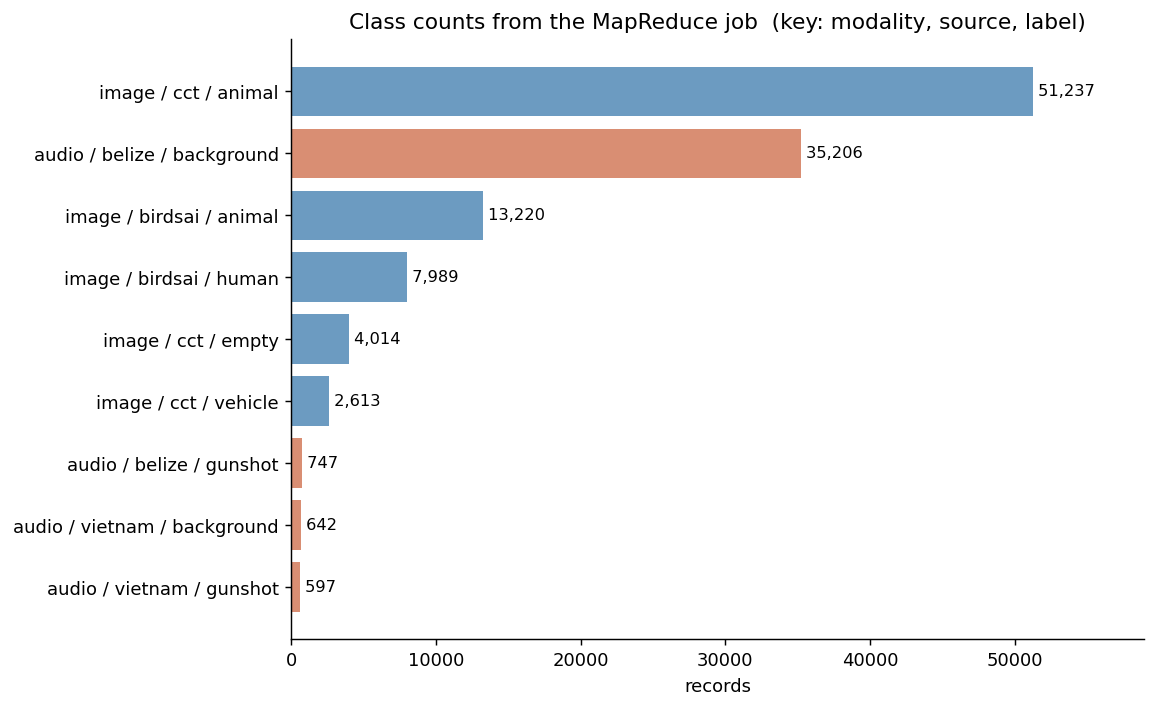

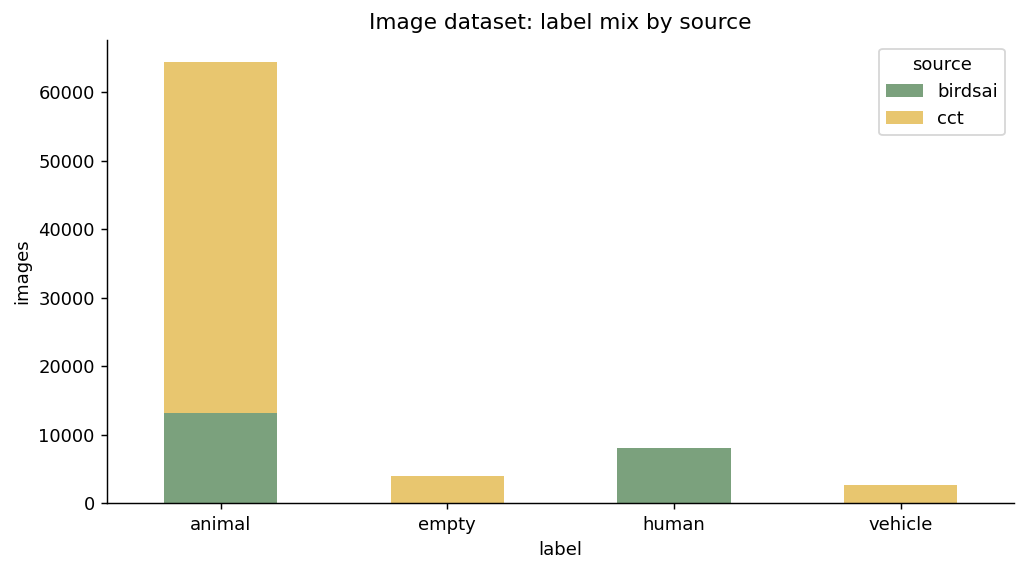

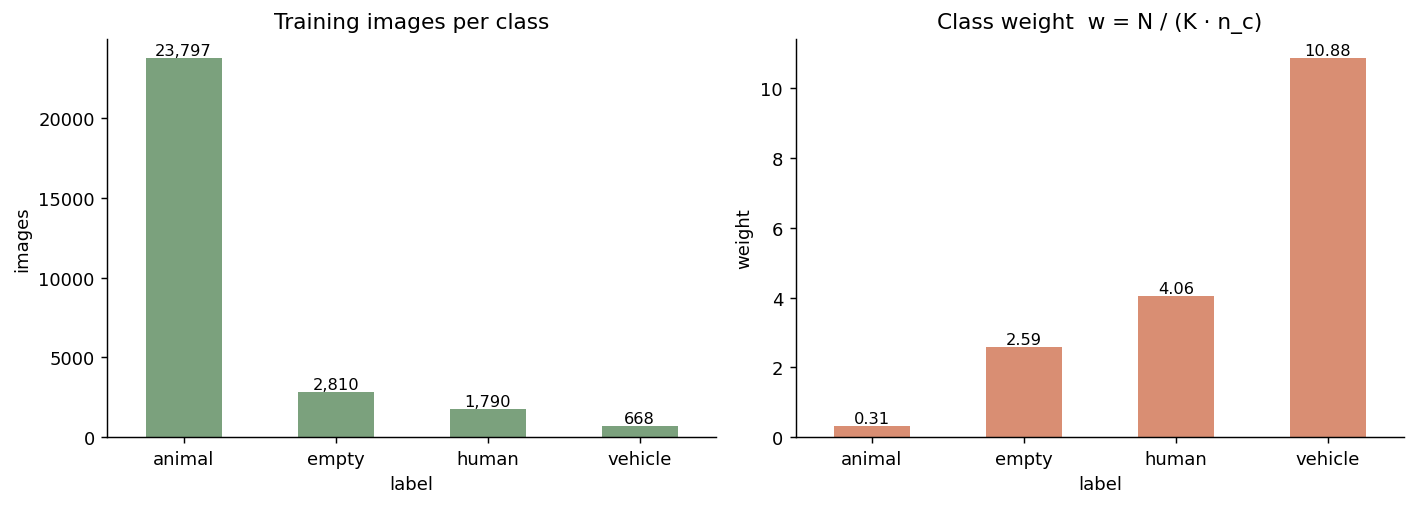

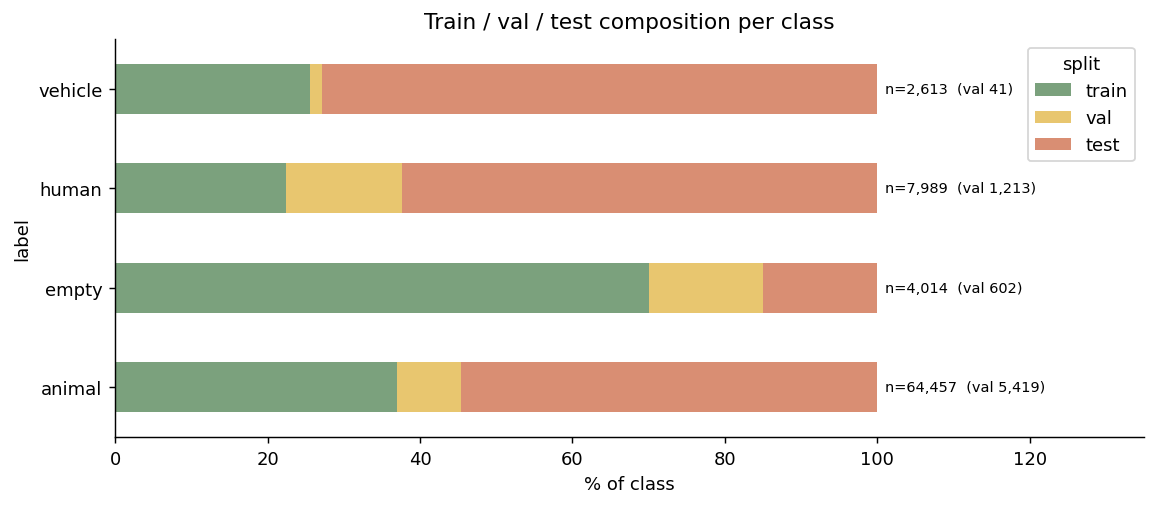

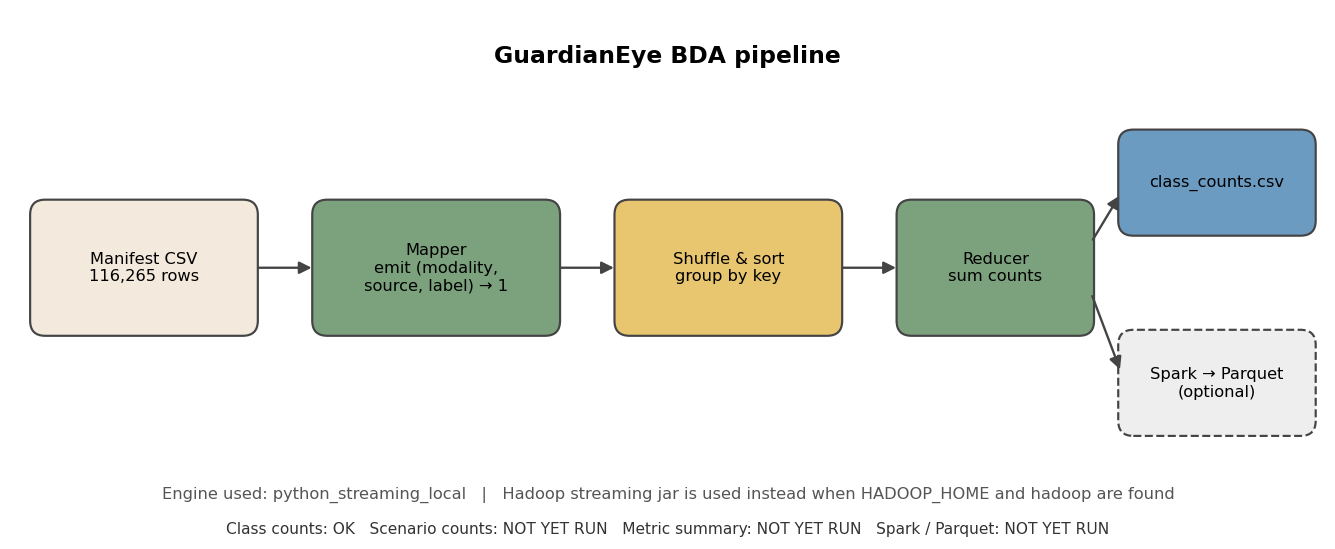

['1_class_counts.png', '2_label_by_source.png', '3_imbalance_and_weights.png', '4_split_composition.png', '5_pipeline.png']


In [40]:
import json, pandas as pd, numpy as np, matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

R = Path("/content/drive/MyDrive/GuardianEye_Data/results")
OUT = R / "bda/figures"; OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 130, "font.size": 10})
GREEN, TERRA, SAND, BLUE = "#7BA17D", "#D98E73", "#E8C66F", "#6C9BC1"

c = pd.read_csv(R / "bda/class_counts.csv")
m = pd.read_csv(R / "runs/seed_27/manifest/manifest.csv", low_memory=False)
st = json.load(open(R / "bda/bda_status.json"))
img = m[m.modality == "image"]

# 1. Class counts by modality / source / label (the MapReduce output)
d = c.sort_values("count")
lab = d.modality + " / " + d.source + " / " + d.label
fig, ax = plt.subplots(figsize=(9, 0.45 * len(d) + 1.5))
ax.barh(lab, d["count"], color=[BLUE if x == "image" else TERRA for x in d.modality])
for i, v in enumerate(d["count"]): ax.text(v, i, f" {v:,}", va="center", fontsize=9)
ax.set_title("Class counts from the MapReduce job  (key: modality, source, label)")
ax.set_xlabel("records"); ax.set_xlim(0, d["count"].max() * 1.15)
plt.tight_layout(); plt.savefig(OUT / "1_class_counts.png"); plt.show()

# 2. Image labels stacked by source
p = c[c.modality == "image"].pivot_table(index="label", columns="source", values="count", aggfunc="sum", fill_value=0)
ax = p.plot(kind="bar", stacked=True, figsize=(8, 4.5), color=[GREEN, SAND, BLUE, TERRA][:len(p.columns)], rot=0)
ax.set_title("Image dataset: label mix by source"); ax.set_ylabel("images")
plt.tight_layout(); plt.savefig(OUT / "2_label_by_source.png"); plt.show()

# 3. Class imbalance and class weights  w_c = N / (K * n_c)  (train split)
tr = img[img.split == "train"].label.value_counts()
K, N = len(tr), tr.sum()
w = (N / (K * tr)).sort_values()
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))
tr.reindex(w.index).plot(kind="bar", ax=a1, color=GREEN, rot=0); a1.set_title("Training images per class"); a1.set_ylabel("images")
for i, v in enumerate(tr.reindex(w.index)): a1.text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=9)
w.plot(kind="bar", ax=a2, color=TERRA, rot=0); a2.set_title("Class weight  w = N / (K · n_c)"); a2.set_ylabel("weight")
for i, v in enumerate(w): a2.text(i, v, f"{v:.2f}", ha="center", va="bottom", fontsize=9)
plt.tight_layout(); plt.savefig(OUT / "3_imbalance_and_weights.png"); plt.show()

# 4. Split composition per class (shows the tiny vehicle validation set)
s = img.groupby(["label", "split"]).size().unstack(fill_value=0)[["train", "val", "test"]]
ax = (s.div(s.sum(axis=1), axis=0) * 100).plot(kind="barh", stacked=True, figsize=(9, 4), color=[GREEN, SAND, TERRA])
ax.set_xlabel("% of class"); ax.set_title("Train / val / test composition per class")
for i, (_, r) in enumerate(s.iterrows()): ax.text(101, i, f"n={r.sum():,}  (val {r['val']:,})", va="center", fontsize=8)
ax.set_xlim(0, 135); plt.tight_layout(); plt.savefig(OUT / "4_split_composition.png"); plt.show()

# 5. Pipeline diagram + real job status
def box(ax, x, y, w, h, t, col, dashed=False):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.03,rounding_size=0.15", fc=col, ec="#444", lw=1.2, ls="--" if dashed else "-"))
    ax.text(x + w / 2, y + h / 2, t, ha="center", va="center", fontsize=9)
def arr(ax, x1, y1, x2, y2): ax.add_patch(FancyArrowPatch((x1, y1), (x2, y2), arrowstyle="-|>", mutation_scale=14, lw=1.3, color="#444"))

fig, ax = plt.subplots(figsize=(13, 5.2)); ax.set_xlim(0, 13); ax.set_ylim(0, 5.2); ax.axis("off")
box(ax, 0.2, 2.0, 2.2, 1.3, f"Manifest CSV\n{int(c['count'].sum()):,} rows", "#F3E9DC")
box(ax, 3.0, 2.0, 2.4, 1.3, "Mapper\nemit (modality,\nsource, label) → 1", GREEN)
box(ax, 6.0, 2.0, 2.2, 1.3, "Shuffle & sort\ngroup by key", SAND)
box(ax, 8.8, 2.0, 1.9, 1.3, "Reducer\nsum counts", GREEN)
box(ax, 11.0, 3.0, 1.9, 1.0, "class_counts.csv", BLUE)
box(ax, 11.0, 1.0, 1.9, 1.0, "Spark → Parquet\n(optional)", "#EEE", dashed=True)
for a in [(2.4, 2.65, 3.0, 2.65), (5.4, 2.65, 6.0, 2.65), (8.2, 2.65, 8.8, 2.65), (10.7, 2.9, 11.0, 3.4), (10.7, 2.4, 11.0, 1.6)]: arr(ax, *a)
ax.text(6.5, 4.7, "GuardianEye BDA pipeline", ha="center", fontsize=13, weight="bold")
ax.text(6.5, 0.35, f"Engine used: {st.get('engine', 'unknown')}   |   Hadoop streaming jar is used instead when HADOOP_HOME and hadoop are found", ha="center", fontsize=9, color="#555")
jobs = {"Class counts": "class_counts", "Scenario counts": "scenario_counts", "Metric summary": "metric_summary", "Spark / Parquet": "spark"}
txt = "   ".join(f"{k}: {st[v].get('status', 'NOT YET RUN') if isinstance(st.get(v), dict) else 'NOT YET RUN'}" for k, v in jobs.items())
ax.text(6.5, 0.0, txt, ha="center", fontsize=8.5, color="#333")
plt.savefig(OUT / "5_pipeline.png", bbox_inches="tight"); plt.show()

print(sorted(p.name for p in OUT.iterdir()))

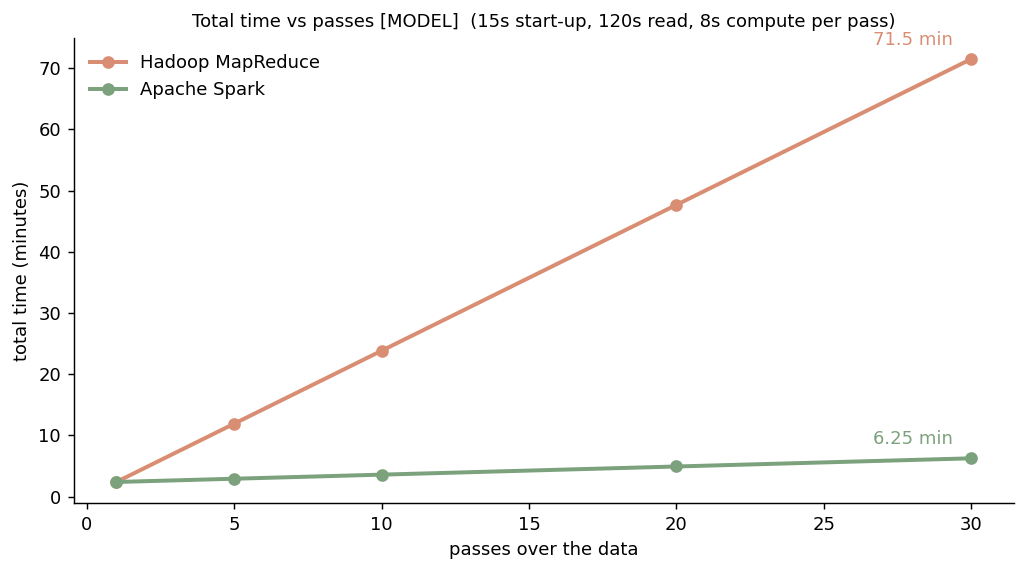

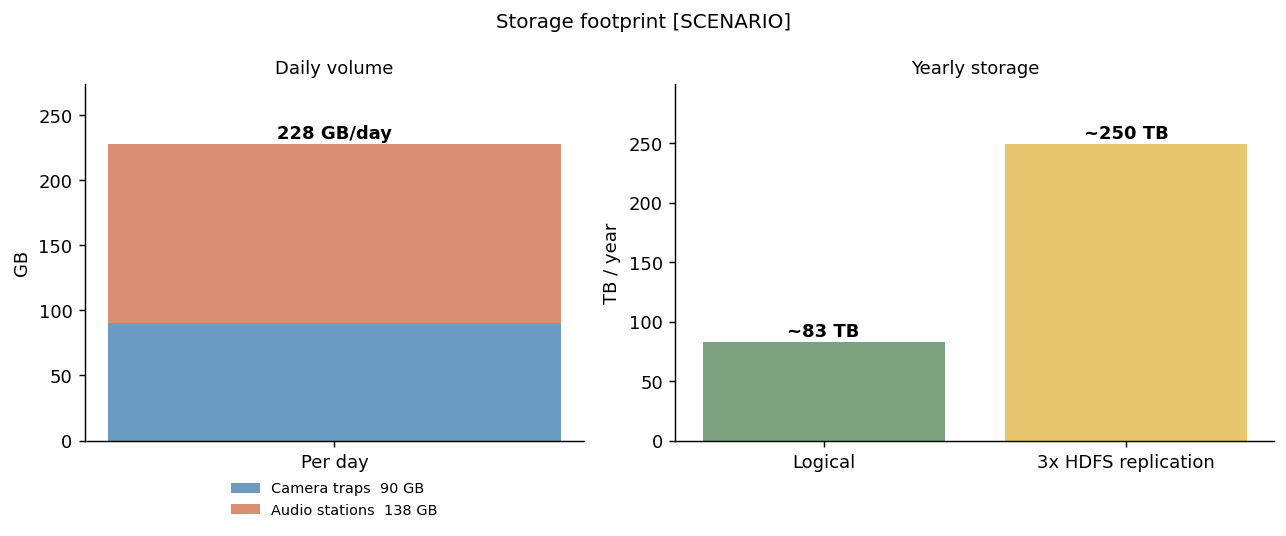

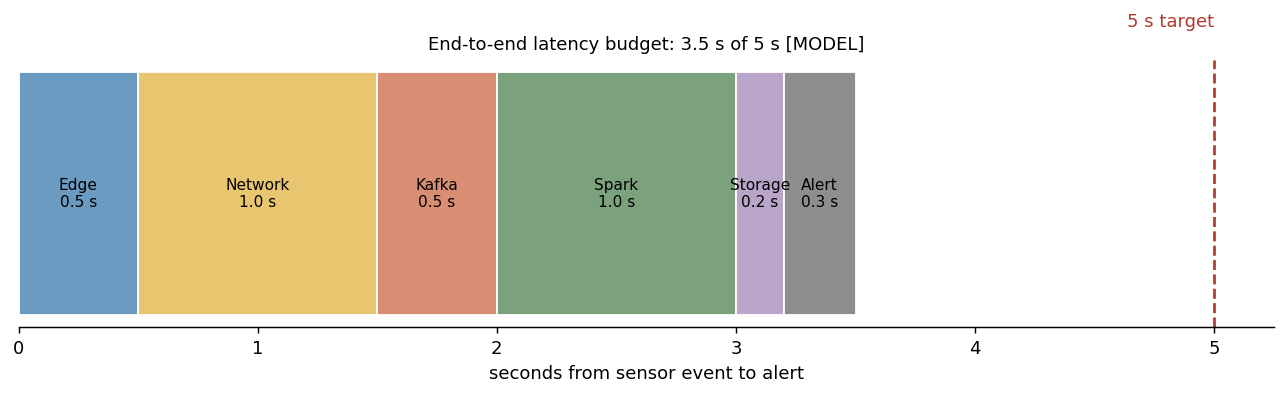

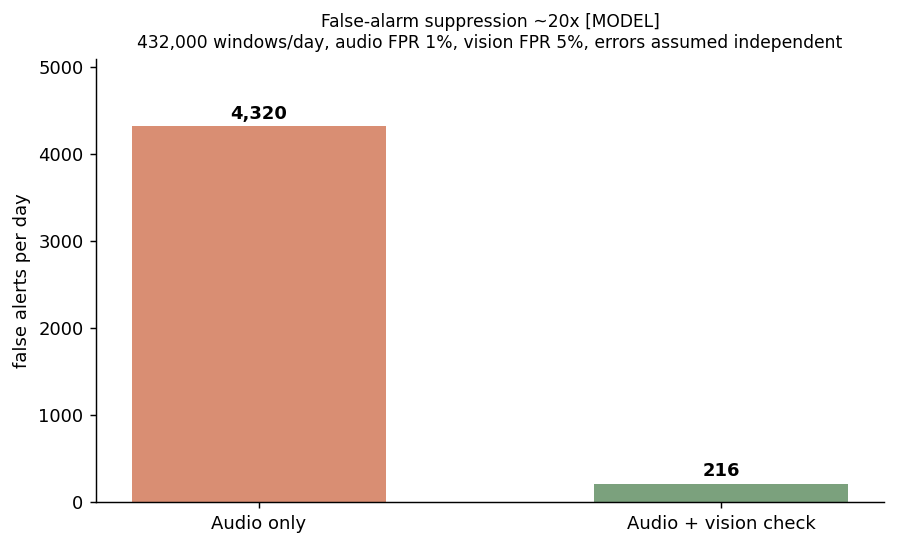

['1_class_counts.png', '2_label_by_source.png', '3_imbalance_and_weights.png', '4_split_composition.png', '5_pipeline.png', '6_time_vs_passes.png', '7_storage.png', '8_latency_budget.png', '9_false_alarms.png']


In [41]:
import numpy as np, matplotlib.pyplot as plt
from pathlib import Path

OUT = Path("/content/drive/MyDrive/GuardianEye_Data/results/bda/figures"); OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 130, "font.size": 10})
GREEN, TERRA, SAND, BLUE = "#7BA17D", "#D98E73", "#E8C66F", "#6C9BC1"

# ---------- EDIT ASSUMPTIONS HERE ----------
STARTUP_S, READ_S, COMPUTE_S = 15, 120, 8                  # seconds
PASSES = [1, 5, 10, 20, 30]
TRAPS_GB, STATIONS_GB = 90, 138                            # GB/day
LATENCY = {"Edge": 0.5, "Network": 1.0, "Kafka": 0.5, "Spark": 1.0, "Storage": 0.2, "Alert": 0.3}
BUDGET_S = 5.0
WINDOWS_PER_DAY, AUDIO_FPR, VISION_FPR = 432_000, 0.01, 0.05
# --------------------------------------------

# 6. Total time vs passes
mr = [(STARTUP_S + READ_S + COMPUTE_S) * p / 60 for p in PASSES]
sp = [(STARTUP_S + READ_S + COMPUTE_S * p) / 60 for p in PASSES]
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(PASSES, mr, "o-", color=TERRA, lw=2.2, label="Hadoop MapReduce")
ax.plot(PASSES, sp, "o-", color=GREEN, lw=2.2, label="Apache Spark")
ax.annotate(f"{mr[-1]:.1f} min", (PASSES[-1], mr[-1]), textcoords="offset points", xytext=(-10, 8), ha="right", color=TERRA)
ax.annotate(f"{sp[-1]:.2f} min", (PASSES[-1], sp[-1]), textcoords="offset points", xytext=(-10, 8), ha="right", color=GREEN)
ax.set_xlabel("passes over the data"); ax.set_ylabel("total time (minutes)"); ax.legend(frameon=False)
ax.set_title(f"Total time vs passes [MODEL]  ({STARTUP_S}s start-up, {READ_S}s read, {COMPUTE_S}s compute per pass)", fontsize=10)
plt.tight_layout(); plt.savefig(OUT / "6_time_vs_passes.png"); plt.show()

# 7. Storage per day and per year
total = TRAPS_GB + STATIONS_GB
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 4.2), gridspec_kw={"width_ratios": [1, 1.2]})
a1.bar(["Per day"], [TRAPS_GB], color=BLUE, label=f"Camera traps  {TRAPS_GB} GB")
a1.bar(["Per day"], [STATIONS_GB], bottom=[TRAPS_GB], color=TERRA, label=f"Audio stations  {STATIONS_GB} GB")
a1.text(0, total + 4, f"{total} GB/day", ha="center", weight="bold"); a1.set_ylim(0, total * 1.2)
a1.set_ylabel("GB"); a1.legend(frameon=False, loc="upper center", fontsize=8, bbox_to_anchor=(0.5, -0.08))
a1.set_title("Daily volume", fontsize=10)
logical = total * 365 / 1000
a2.bar(["Logical", "3x HDFS replication"], [logical, logical * 3], color=[GREEN, SAND])
for i, v in enumerate([logical, logical * 3]): a2.text(i, v + 4, f"~{v:.0f} TB", ha="center", weight="bold")
a2.set_ylim(0, logical * 3 * 1.2); a2.set_ylabel("TB / year"); a2.set_title("Yearly storage", fontsize=10)
fig.suptitle("Storage footprint [SCENARIO]", fontsize=11); plt.tight_layout(); plt.savefig(OUT / "7_storage.png"); plt.show()

# 8. Latency budget
names, vals = list(LATENCY), list(LATENCY.values()); starts = np.concatenate([[0], np.cumsum(vals)[:-1]])
cols = [BLUE, SAND, TERRA, GREEN, "#B9A5C9", "#8E8E8E"]
fig, ax = plt.subplots(figsize=(10, 3.2))
for n, s, v, c in zip(names, starts, vals, cols):
    ax.barh(0, v, left=s, color=c, edgecolor="white")
    ax.text(s + v / 2, 0, f"{n}\n{v} s", ha="center", va="center", fontsize=8.5)
ax.axvline(BUDGET_S, color="#B03A2E", ls="--", lw=1.5); ax.text(BUDGET_S, 0.55, f"{BUDGET_S:g} s target", ha="right", color="#B03A2E")
ax.set_xlim(0, BUDGET_S * 1.05); ax.set_yticks([]); ax.set_xlabel("seconds from sensor event to alert")
ax.set_title(f"End-to-end latency budget: {sum(vals):.1f} s of {BUDGET_S:g} s [MODEL]", fontsize=10)
ax.spines["left"].set_visible(False); plt.tight_layout(); plt.savefig(OUT / "8_latency_budget.png"); plt.show()

# 9. False alarms per day
audio_fa = WINDOWS_PER_DAY * AUDIO_FPR; fused_fa = audio_fa * VISION_FPR
fig, ax = plt.subplots(figsize=(7, 4.3))
ax.bar(["Audio only", "Audio + vision check"], [audio_fa, fused_fa], color=[TERRA, GREEN], width=0.55)
for i, v in enumerate([audio_fa, fused_fa]): ax.text(i, v + audio_fa * 0.02, f"{v:,.0f}", ha="center", weight="bold")
ax.set_ylim(0, audio_fa * 1.18); ax.set_ylabel("false alerts per day")
ax.set_title(f"False-alarm suppression ~{audio_fa / fused_fa:.0f}x [MODEL]\n"
             f"{WINDOWS_PER_DAY:,} windows/day, audio FPR {AUDIO_FPR:.0%}, vision FPR {VISION_FPR:.0%}, errors assumed independent", fontsize=9.5)
plt.tight_layout(); plt.savefig(OUT / "9_false_alarms.png"); plt.show()

print(sorted(p.name for p in OUT.iterdir()))

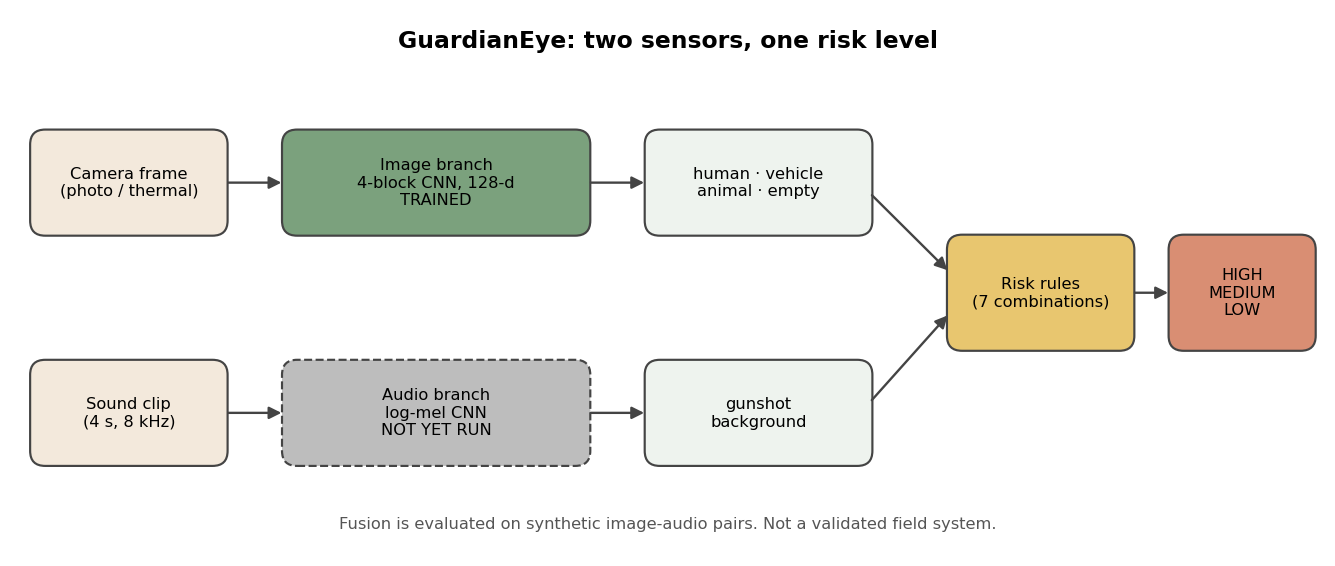

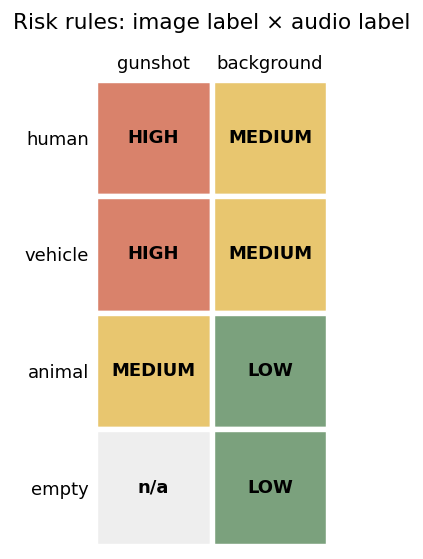

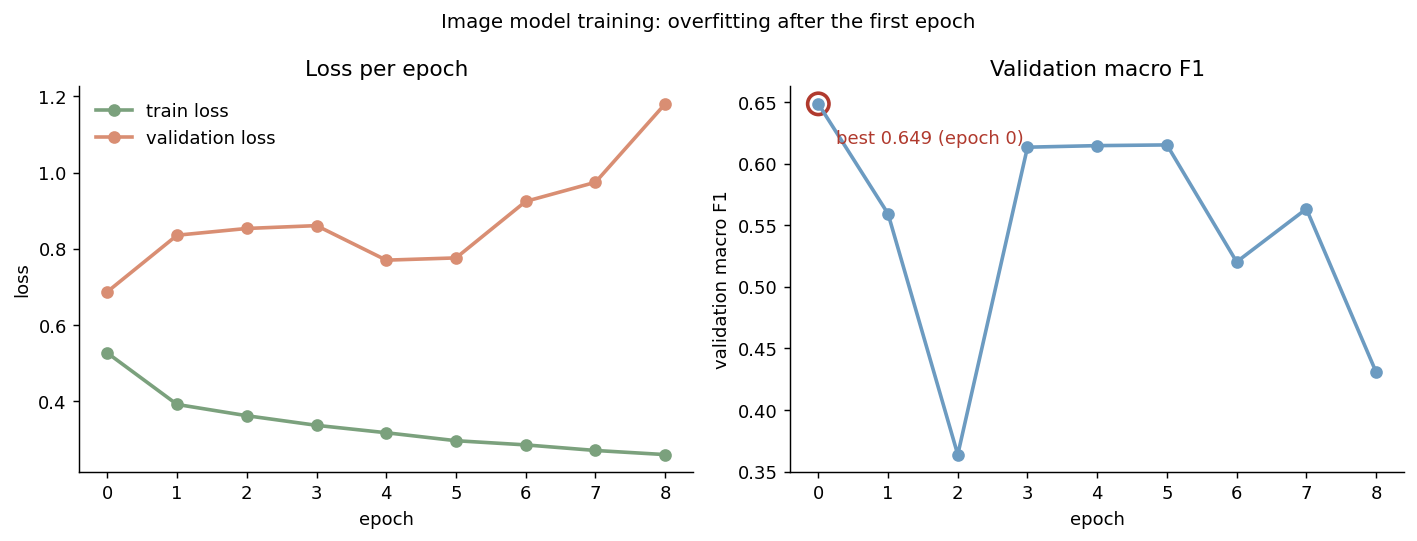

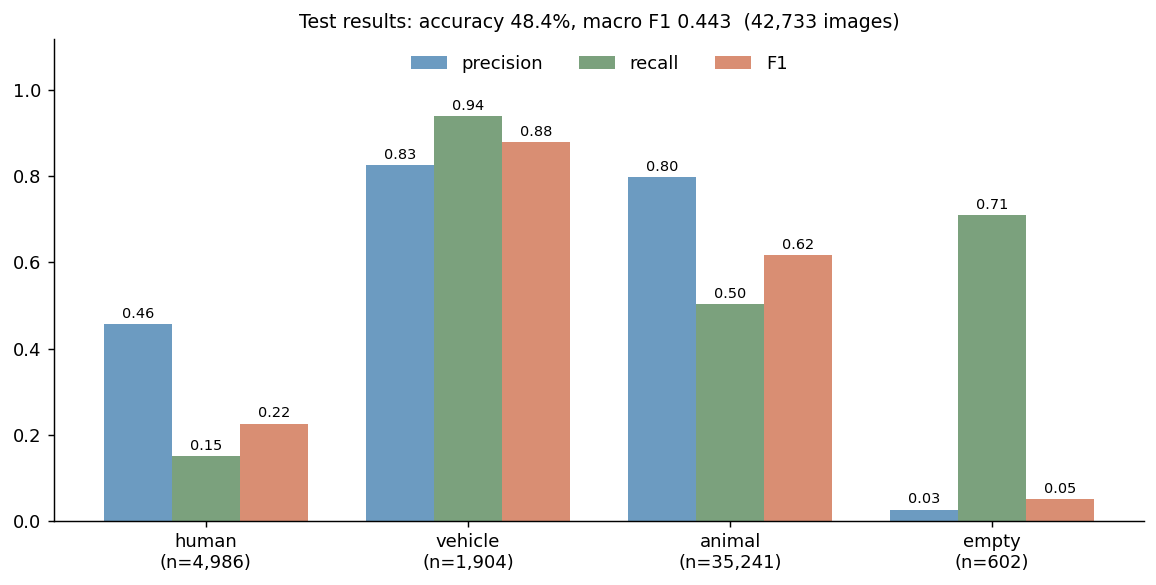

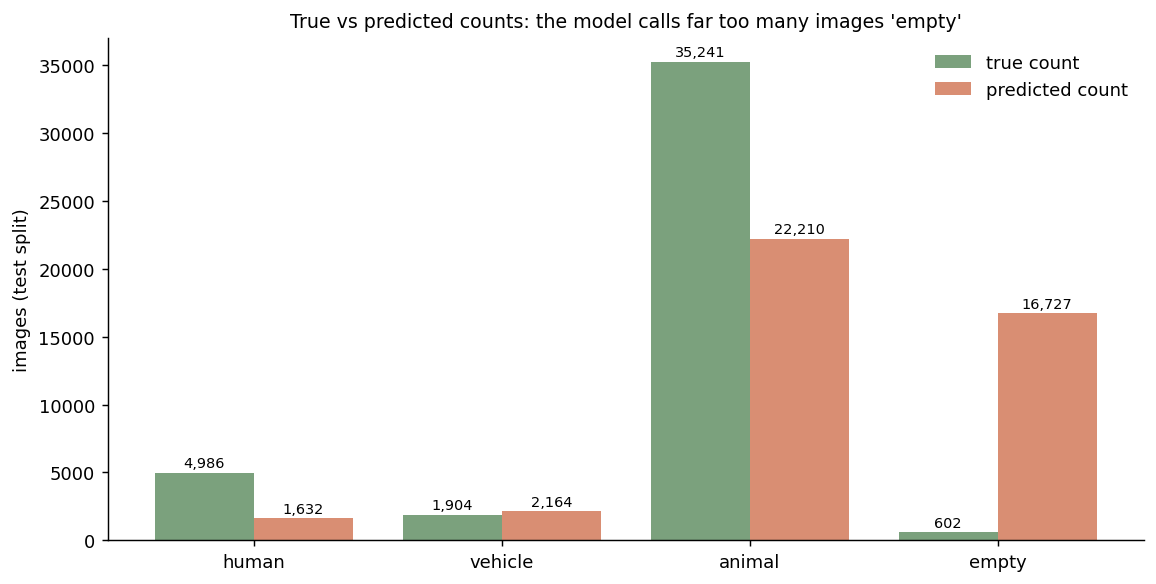

predicted per class (derived): {'human': 1632, 'vehicle': 2164, 'animal': 22210, 'empty': 16727} sum = 42733
['1_class_counts.png', '2_label_by_source.png', '3_imbalance_and_weights.png', '4_split_composition.png', '5_pipeline.png', '6_time_vs_passes.png', '7_storage.png', '8_latency_budget.png', '9_false_alarms.png', 'M1_architecture.png', 'M2_risk_matrix.png', 'M4_training_curves.png', 'M5_per_class.png', 'M6_true_vs_predicted.png']


In [42]:
# GuardianEye MMAI figures. Paste into ONE Colab cell (Drive mounted) and run.
# Uses real files only: epoch checkpoints and image_metrics.json. Nothing is invented.
import json, re
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
import torch

R = Path("/content/drive/MyDrive/GuardianEye_Data/results")
RUN = R / "runs/seed_27"
OUT = R / "bda/figures"; OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 130, "font.size": 10})
GREEN, TERRA, SAND, BLUE, GREY = "#7BA17D", "#D98E73", "#E8C66F", "#6C9BC1", "#BDBDBD"
CLASSES = ["human", "vehicle", "animal", "empty"]

# ---------------- M1: system architecture ----------------
def box(ax, x, y, w, h, t, col, dashed=False):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.03,rounding_size=0.15",
                                fc=col, ec="#444", lw=1.2, ls="--" if dashed else "-"))
    ax.text(x + w / 2, y + h / 2, t, ha="center", va="center", fontsize=9)

def arrow(ax, x1, y1, x2, y2):
    ax.add_patch(FancyArrowPatch((x1, y1), (x2, y2), arrowstyle="-|>", mutation_scale=14, lw=1.3, color="#444"))

fig, ax = plt.subplots(figsize=(13, 5.4)); ax.set_xlim(0, 13); ax.set_ylim(0, 5.4); ax.axis("off")
ax.text(6.5, 5.05, "GuardianEye: two sensors, one risk level", ha="center", fontsize=13, weight="bold")
box(ax, 0.2, 3.2, 1.9, 1.0, "Camera frame\n(photo / thermal)", "#F3E9DC")
box(ax, 2.7, 3.2, 3.0, 1.0, "Image branch\n4-block CNN, 128-d\nTRAINED", GREEN)
box(ax, 6.3, 3.2, 2.2, 1.0, "human · vehicle\nanimal · empty", "#EEF3EE")
box(ax, 0.2, 0.9, 1.9, 1.0, "Sound clip\n(4 s, 8 kHz)", "#F3E9DC")
box(ax, 2.7, 0.9, 3.0, 1.0, "Audio branch\nlog-mel CNN\nNOT YET RUN", GREY, dashed=True)
box(ax, 6.3, 0.9, 2.2, 1.0, "gunshot\nbackground", "#EEF3EE")
box(ax, 9.3, 2.05, 1.8, 1.1, "Risk rules\n(7 combinations)", SAND)
box(ax, 11.5, 2.05, 1.4, 1.1, "HIGH\nMEDIUM\nLOW", TERRA)
for a in [(2.1, 3.7, 2.7, 3.7), (5.7, 3.7, 6.3, 3.7), (2.1, 1.4, 2.7, 1.4), (5.7, 1.4, 6.3, 1.4),
          (8.5, 3.6, 9.3, 2.8), (8.5, 1.5, 9.3, 2.4), (11.1, 2.6, 11.5, 2.6)]:
    arrow(ax, *a)
ax.text(6.5, 0.25, "Fusion is evaluated on synthetic image-audio pairs. Not a validated field system.",
        ha="center", fontsize=9, color="#555")
plt.savefig(OUT / "M1_architecture.png", bbox_inches="tight"); plt.show()

# ---------------- M2: risk matrix ----------------
imgs = ["human", "vehicle", "animal", "empty"]; auds = ["gunshot", "background"]
risk = {("human", "gunshot"): "HIGH", ("vehicle", "gunshot"): "HIGH", ("animal", "gunshot"): "MEDIUM",
        ("empty", "gunshot"): "n/a", ("human", "background"): "MEDIUM", ("vehicle", "background"): "MEDIUM",
        ("animal", "background"): "LOW", ("empty", "background"): "LOW"}
col = {"HIGH": "#D9826B", "MEDIUM": SAND, "LOW": GREEN, "n/a": "#EEEEEE"}
fig, ax = plt.subplots(figsize=(6.5, 4.4))
for i, im in enumerate(imgs):
    for j, au in enumerate(auds):
        r = risk[(im, au)]
        ax.add_patch(plt.Rectangle((j, len(imgs) - 1 - i), 1, 1, fc=col[r], ec="white", lw=3))
        ax.text(j + 0.5, len(imgs) - 1 - i + 0.5, r, ha="center", va="center", weight="bold")
ax.set_xlim(0, 2); ax.set_ylim(0, 4); ax.set_aspect("equal")
ax.set_xticks([0.5, 1.5]); ax.set_xticklabels(auds)
ax.set_yticks([3.5 - i for i in range(4)]); ax.set_yticklabels(imgs)
ax.xaxis.tick_top(); ax.tick_params(length=0)
for s in ax.spines.values(): s.set_visible(False)
ax.set_title("Risk rules: image label × audio label", pad=28)
plt.tight_layout(); plt.savefig(OUT / "M2_risk_matrix.png"); plt.show()

# ---------------- M4: training curves from checkpoints ----------------
rows = []
for p in sorted((RUN / "checkpoints/image_branch").glob("epoch_*.pt")):
    st = torch.load(p, map_location="cpu", weights_only=False)
    mt = st.get("metrics", {})
    rows.append((int(st["epoch"]), mt.get("train_loss"), mt.get("val_loss"), mt.get("val_f1")))
rows.sort()
if rows:
    ep = [r[0] for r in rows]
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.2))
    a1.plot(ep, [r[1] for r in rows], "o-", color=GREEN, lw=2, label="train loss")
    a1.plot(ep, [r[2] for r in rows], "o-", color=TERRA, lw=2, label="validation loss")
    a1.set_xlabel("epoch"); a1.set_ylabel("loss"); a1.legend(frameon=False); a1.set_title("Loss per epoch")
    f1 = [np.nan if r[3] is None else r[3] for r in rows]
    a2.plot(ep, f1, "o-", color=BLUE, lw=2)
    b = int(np.nanargmax(f1)); a2.scatter([ep[b]], [f1[b]], s=140, facecolors="none", edgecolors="#B03A2E", lw=2)
    a2.annotate(f"best {f1[b]:.3f} (epoch {ep[b]})", (ep[b], f1[b]), textcoords="offset points",
                xytext=(10, -22), color="#B03A2E")
    a2.set_xlabel("epoch"); a2.set_ylabel("validation macro F1"); a2.set_title("Validation macro F1")
    fig.suptitle("Image model training: overfitting after the first epoch", fontsize=11)
    plt.tight_layout(); plt.savefig(OUT / "M4_training_curves.png"); plt.show()
else:
    print("No epoch_*.pt checkpoints found: M4 skipped.")

# ---------------- M5 and M6: test results from image_metrics.json ----------------
m = json.load(open(RUN / "metrics/image_metrics.json"))
pc = m["overall"]["per_class"]
P = [pc[c]["precision"] for c in CLASSES]; Rc = [pc[c]["recall"] for c in CLASSES]; F = [pc[c]["f1"] for c in CLASSES]
S = [pc[c]["support"] for c in CLASSES]

x = np.arange(4); w = 0.26
fig, ax = plt.subplots(figsize=(9, 4.6))
for off, vals, c, n in [(-w, P, BLUE, "precision"), (0, Rc, GREEN, "recall"), (w, F, TERRA, "F1")]:
    bars = ax.bar(x + off, vals, w, color=c, label=n)
    for b_, v in zip(bars, vals): ax.text(b_.get_x() + b_.get_width() / 2, v + 0.015, f"{v:.2f}", ha="center", fontsize=8)
ax.set_xticks(x); ax.set_xticklabels([f"{c}\n(n={s:,})" for c, s in zip(CLASSES, S)])
ax.set_ylim(0, 1.12); ax.legend(frameon=False, ncol=3, loc="upper center")
ax.set_title(f"Test results: accuracy {m['overall']['accuracy']:.1%}, macro F1 {m['overall']['f1_macro']:.3f}  "
             f"({m['count']:,} images)", fontsize=10.5)
plt.tight_layout(); plt.savefig(OUT / "M5_per_class.png"); plt.show()

# predicted count per class = TP / precision, TP = recall * support
pred = [(Rc[i] * S[i]) / P[i] if P[i] else 0 for i in range(4)]
fig, ax = plt.subplots(figsize=(9, 4.6))
b1 = ax.bar(x - 0.2, S, 0.4, color=GREEN, label="true count")
b2 = ax.bar(x + 0.2, pred, 0.4, color=TERRA, label="predicted count")
for bars in (b1, b2):
    for b_ in bars: ax.text(b_.get_x() + b_.get_width() / 2, b_.get_height() + 400, f"{b_.get_height():,.0f}", ha="center", fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(CLASSES); ax.set_ylabel("images (test split)"); ax.legend(frameon=False)
ax.set_title("True vs predicted counts: the model calls far too many images 'empty'", fontsize=10.5)
plt.tight_layout(); plt.savefig(OUT / "M6_true_vs_predicted.png"); plt.show()
print("predicted per class (derived):", dict(zip(CLASSES, [round(v) for v in pred])), "sum =", round(sum(pred)))

print(sorted(p.name for p in OUT.iterdir()))